In [204]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import MinMaxScaler



sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [205]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'

In [206]:
orf_distances = pd.read_csv(f"{outputs_dir}/orf_distances_enhanced_metrics.csv").pipe(pl.from_pandas)
edge_df = pd.read_csv(f"{outputs_dir}/all_variant_scores_enhanced_metrics.csv")
consensus_all_media_df = pd.read_csv(f"{outputs_dir}/4_final_filtered_consensus_scores.csv")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/1290221930.py:2: DtypeWarning: Columns (157,159,162,178,187,200,205,206,221,223,224,225,226,227,228,229,230,231,237,238,280,281,606,608,670,672,674,960,967,970,979,980,981,990,1000,1001,1002,1006,1009,1010,1016,1020,1025) have mixed types. Specify dtype option on import or set low_memory=False.
  edge_df = pd.read_csv(f"{outputs_dir}/all_variant_scores_enhanced_metrics.csv")
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/1290221930.py:3: DtypeWarning: Columns (28,29,30,31,34,35,36,37,38,39,40,41,42,43,44,46,47,48,49,50,51,52,53,67,68,69,70,71,73,74,76,77,78,80,82,83,84,85,86,87,88,89,90,93,94,96,97,98,102,103,104,105,106,107,108,109,110,111,112,114,115,117,119,120,121,122,123,124,126,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,181,184,186,187,188,189,190,191,

Perturbation threshold (95th percentile of Benign): 0.6224


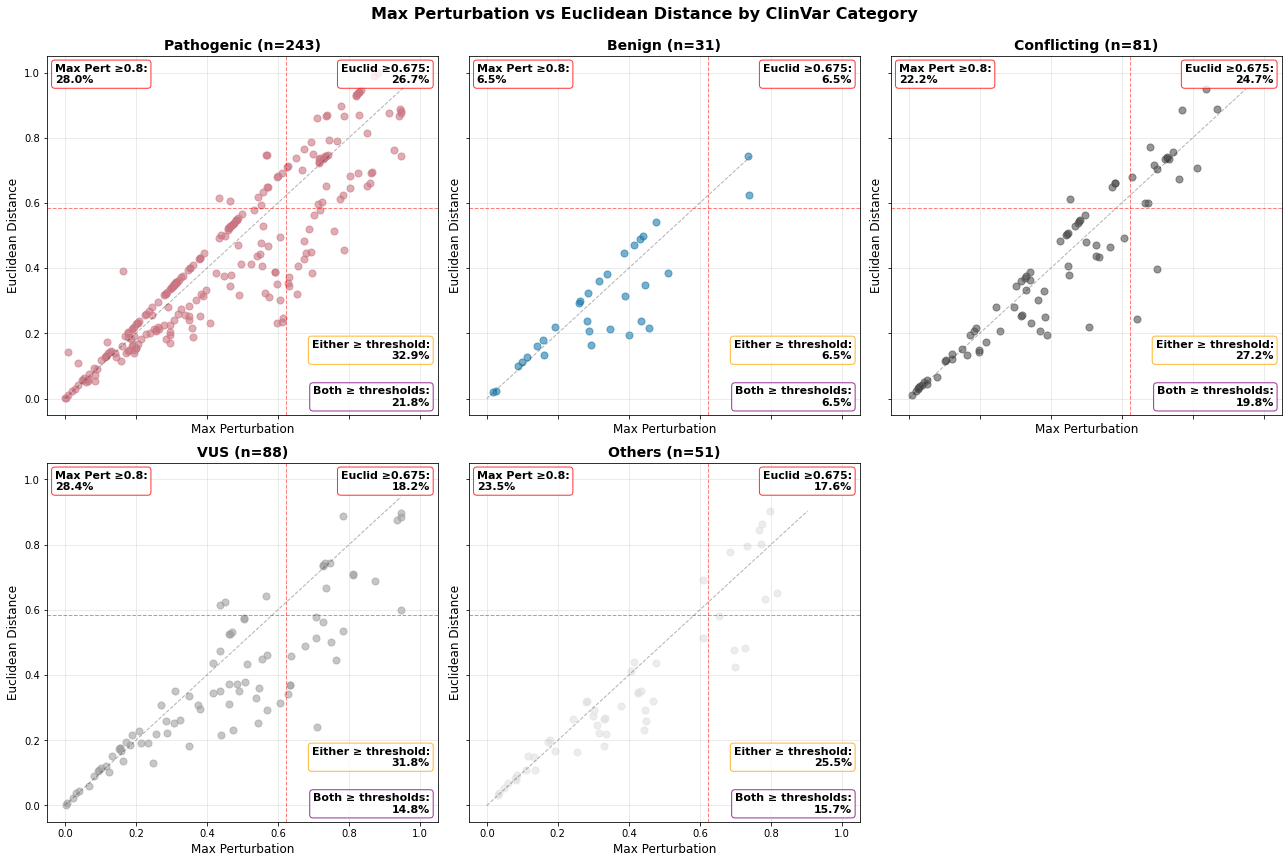

In [207]:
# Create 5 subplots for each category
fig, axes = plt.subplots(2, 3, figsize=(18, 12), sharex=True, sharey=True)
axes = axes.flatten()

categories = ['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']

plot_data = orf_distances.filter(
    pl.col("clinvar_clnsig_clean").is_in(categories)
).to_pandas()

# defined as the 95th percentile of benign variants

euclid_threshold = plot_data[plot_data['clinvar_clnsig_clean'] == 'Benign']['normalized_euclid_distance_normalized'].quantile(0.95)
pertubration_threshold = plot_data[plot_data['clinvar_clnsig_clean'] == 'Benign']['max_perturbation'].quantile(0.95)
print(f"Perturbation threshold (95th percentile of Benign): {pertubration_threshold:.4f}")

for idx, category in enumerate(categories):
    ax = axes[idx]
    data = plot_data[plot_data['clinvar_clnsig_clean'] == category]
    
    ax.scatter(
        data['max_perturbation'],
        np.abs(data['normalized_euclid_distance_normalized']),
        c=palette_dict['clinvar_clnsig_clean'][category],
        alpha=0.6,
        s=50
    )
    
    ax.set_xlabel('Max Perturbation', fontsize=12)
    ax.set_ylabel('Euclidean Distance', fontsize=12)
    ax.set_title(f'{category} (n={len(data)})', fontsize=14, fontweight='bold')
    ax.axhline(euclid_threshold, color='red', linestyle='--', linewidth=1, alpha=0.5)
    ax.axvline(pertubration_threshold, color='red', linestyle='--', linewidth=1, alpha=0.5)
    ax.grid(alpha=0.3)
    
    # Add diagonal line for reference
    max_val = max(data['max_perturbation'].max(), np.abs(data['normalized_euclid_distance_normalized']).max())
    ax.plot([0, max_val], [0, max_val], 'k--', alpha=0.3, linewidth=1)
    
    # Calculate and display percentages for both thresholds
    if len(data) > 0:
        # Max perturbation threshold (top-left)
        pct_max_pert = (data['max_perturbation'] >= pertubration_threshold).sum() / len(data) * 100
        ax.text(0.02, 0.98, f'Max Pert ≥0.8:\n{pct_max_pert:.1f}%',
                transform=ax.transAxes,
                fontsize=11,
                fontweight='bold',
                verticalalignment='top',
                horizontalalignment='left',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='red'))
        
        # Euclidean distance threshold (top-right)
        pct_euclid = (np.abs(data['normalized_euclid_distance_normalized']) >= euclid_threshold).sum() / len(data) * 100
        ax.text(0.98, 0.98, f'Euclid ≥0.675:\n{pct_euclid:.1f}%',
                transform=ax.transAxes,
                fontsize=11,
                fontweight='bold',
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='red'))
        
        # Union of both thresholds (right side, above "both")
        pct_union = ((data['max_perturbation'] >= pertubration_threshold) | 
                     (np.abs(data['normalized_euclid_distance_normalized']) >= euclid_threshold)).sum() / len(data) * 100
        ax.text(0.98, 0.15, f'Either ≥ threshold:\n{pct_union:.1f}%',
                transform=ax.transAxes,
                fontsize=11,
                fontweight='bold',
                verticalalignment='bottom',
                horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='orange'))
        
        # Both thresholds (bottom-right)
        pct_both = ((data['max_perturbation'] >= pertubration_threshold) & 
                    (np.abs(data['normalized_euclid_distance_normalized']) >= euclid_threshold)).sum() / len(data) * 100
        ax.text(0.98, 0.02, f'Both ≥ thresholds:\n{pct_both:.1f}%',
                transform=ax.transAxes,
                fontsize=11,
                fontweight='bold',
                verticalalignment='bottom',
                horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='purple'))

# Hide the 6th subplot since we only have 5 categories
axes[5].set_visible(False)

plt.suptitle('Max Perturbation vs Euclidean Distance by ClinVar Category', 
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

In [227]:
plot_data[(plot_data['clinvar_clnsig_clean'] == 'Benign') &
          (plot_data.max_perturbation >= pertubration_threshold)][['symbol']]

,symbol
78,KCNJ2
271,ACSF3


In [209]:
edge_df[
    (edge_df.symbol == 'BAG3') &
    (edge_df.ad_symbol == 'TRIM27') &
    (edge_df.db_mut_id == 201830)
    ]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
668,VUSAPWT1B2r03_029,A05,VUSAPWT1B2r03_025_026_027_028_029_030,VUSAPWT1B2,r09,LWH1,1,False,152,NaN,...,5066.0_201830.0_LWH1_VUSAPWT1B2,152.0_5066.0_201830.0_VUSAPWT1B2,152.0_5066.0_VUSAPWT1B2,1,1,Y,2.590796,3.0,424.235966,-0.167795


In [210]:
consensus_all_media_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,splicing_variant,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,aa_score,consensus_manual_score_growth
0,VUSAPWT1B1r01_001,A15,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,71704,NaN,...,NaN,11805.0_0.0_VUSAPWT1B1,11805.0_0.0_LW_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,NaN,495.702792,4.0
1,VUSAPWT1B1r01_001,A17,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,13662,NaN,...,NaN,70497.0_0.0_VUSAPWT1B1,70497.0_0.0_LW_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,NaN,490.064748,4.0
2,VUSAPWT1B1r01_001,A23,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,11567,NaN,...,NaN,52920.0_0.0_VUSAPWT1B1,52920.0_0.0_LW_VUSAPWT1B1,11567.0_52920.0_0.0_VUSAPWT1B1,11567.0_52920.0_VUSAPWT1B1,1,1,NaN,523.463219,4.0
3,VUSAPWT1B1r01_001,C03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,12260,NaN,...,NaN,2651.0_0.0_VUSAPWT1B1,2651.0_0.0_LW_VUSAPWT1B1,12260.0_2651.0_0.0_VUSAPWT1B1,12260.0_2651.0_VUSAPWT1B1,1,1,NaN,442.496195,NaN
4,VUSAPWT1B1r01_001,C07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,5441,NaN,...,NaN,71892.0_0.0_VUSAPWT1B1,71892.0_0.0_LW_VUSAPWT1B1,5441.0_71892.0_0.0_VUSAPWT1B1,5441.0_71892.0_VUSAPWT1B1,1,1,NaN,444.169574,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18844,VUSAPWT1B1r06_033,O11,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,53964,NaN,...,False,2713.0_200832.0_VUSAPWT1B1,2713.0_200832.0_LWAH1_VUSAPWT1B1,53964.0_2713.0_200832.0_VUSAPWT1B1,53964.0_2713.0_VUSAPWT1B1,1,1,Y,0.000000,0.0
18845,VUSAPWT1B1r06_033,O13,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,11922,NaN,...,False,2713.0_200832.0_VUSAPWT1B1,2713.0_200832.0_LWAH1_VUSAPWT1B1,11922.0_2713.0_200832.0_VUSAPWT1B1,11922.0_2713.0_VUSAPWT1B1,1,1,Y,0.000000,2.0
18846,VUSAPWT1B1r06_033,O21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,6811,NaN,...,False,4723.0_201739.0_VUSAPWT1B1,4723.0_201739.0_LWAH1_VUSAPWT1B1,6811.0_4723.0_201739.0_VUSAPWT1B1,6811.0_4723.0_VUSAPWT1B1,1,1,Y,0.000000,3.0
18847,VUSAPWT1B1r06_036,O15,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,3598,NaN,...,False,52920.0_218637.0_VUSAPWT1B1,52920.0_218637.0_LWAH1_VUSAPWT1B1,3598.0_52920.0_218637.0_VUSAPWT1B1,3598.0_52920.0_VUSAPWT1B1,1,1,Y,0.000000,2.0


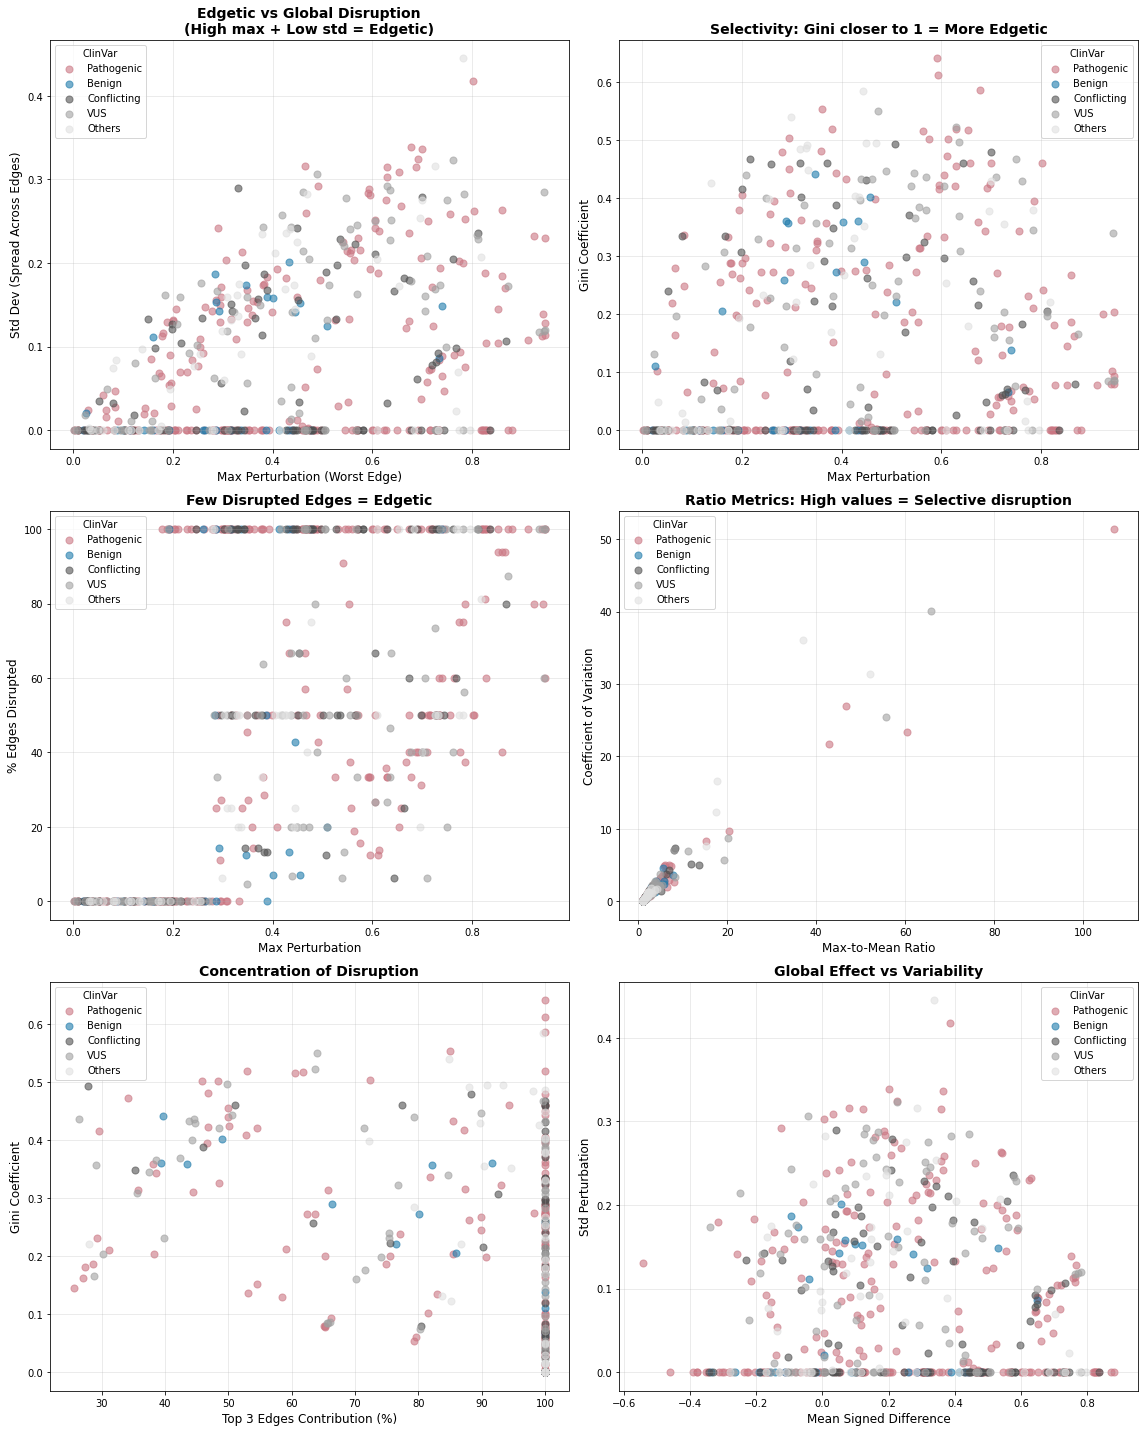

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2312506394.py:206: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2312506394.py:206: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2312506394.py:206: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2312506394.py:206: FutureWarning: 

Passing `palette` without assigning `hue` is deprecat

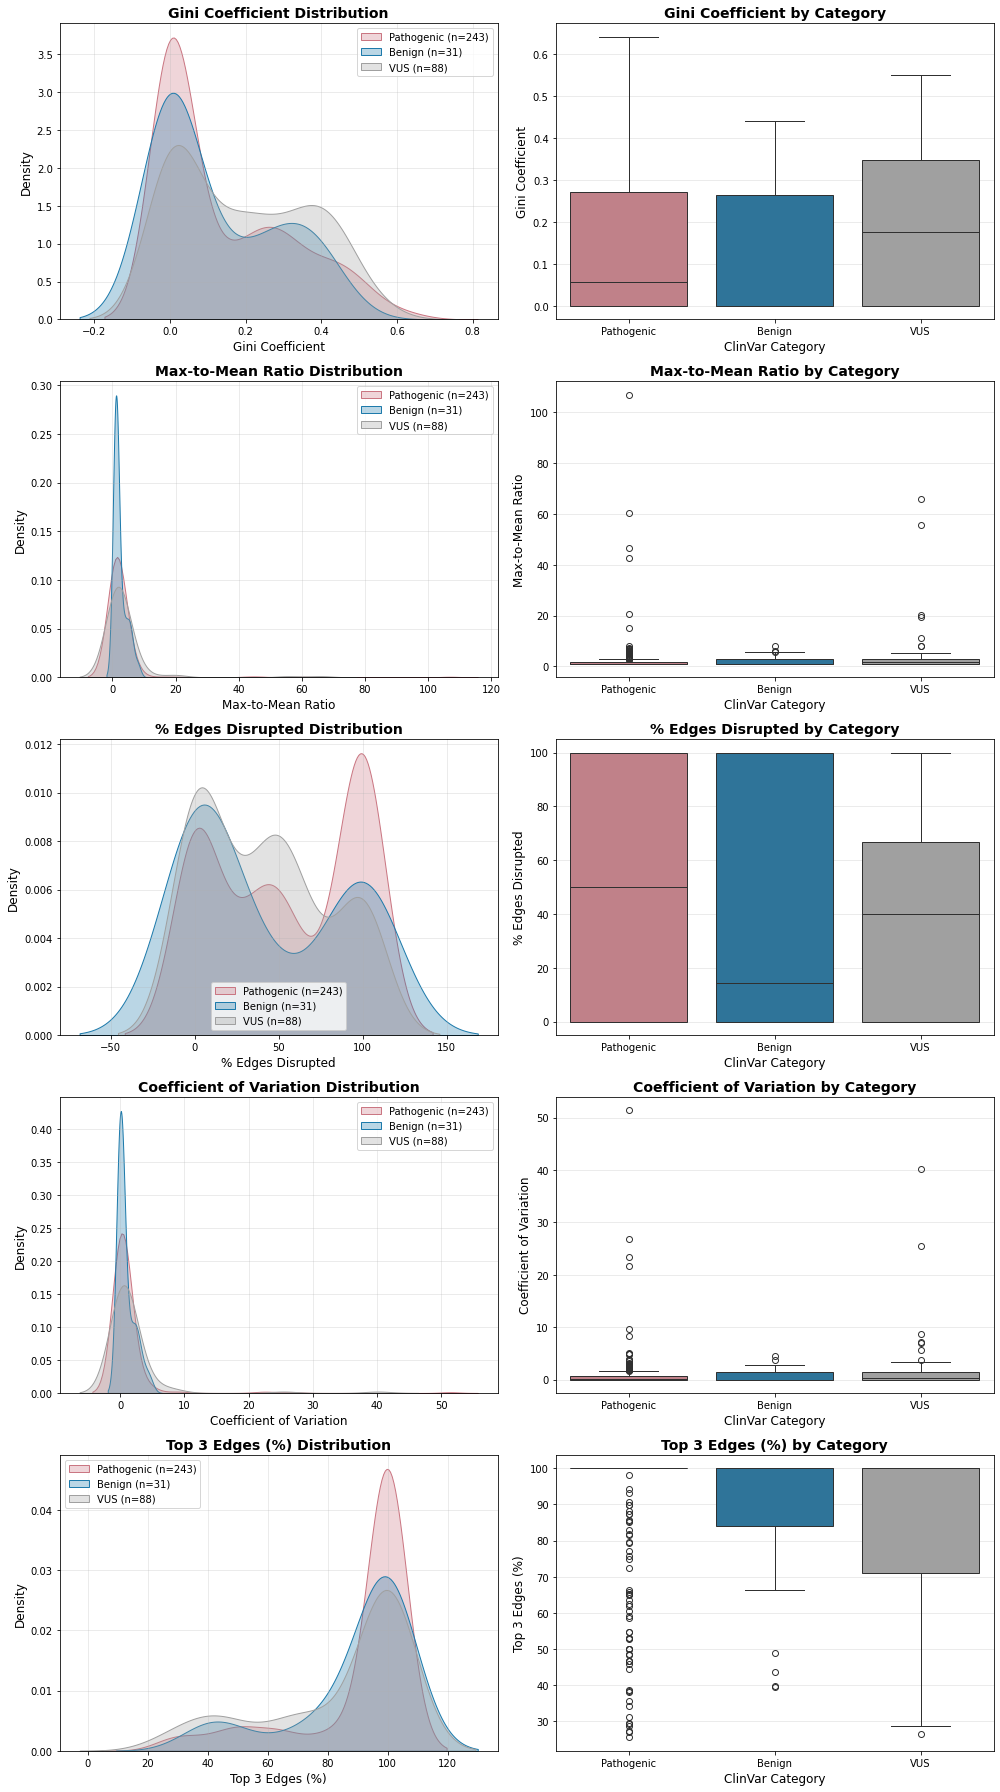


Edgetic Variant Summary:
Total variants: 494
Edgetic variants: 238

By ClinVar category:
clinvar_clnsig_clean  is_edgetic
Benign                True           18
                      False          13
Conflicting           False          47
                      True           34
Others                True           34
                      False          17
Pathogenic            False         142
                      True          101
VUS                   True           51
                      False          37
Name: count, dtype: int64


In [211]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import polars as pl

def plot_edgetic_analysis(orf_distances, palette_dict=None):
    """
    Create comprehensive visualizations for edgetic analysis.
    
    Parameters:
    -----------
    orf_distances : pl.DataFrame
        DataFrame with edgetic metrics from compute_orf_distances()
    palette_dict : dict
        Dictionary mapping clinvar categories to colors
    """
    
    orf_pd = orf_distances.to_pandas()
    
    if palette_dict is None:
        palette_dict = {
            'clinvar_clnsig_clean': {
                'Pathogenic': "#CA7682",
                'Benign': "#1D7AAB",
                'Conflicting': "#505050",
                'VUS': "#A0A0A0",
                'Others': "#E0E0E0"
            }
        }
    
    # Create figure with 6 subplots
    fig, axes = plt.subplots(3, 2, figsize=(16, 20))
    axes = axes.flatten()
    
    # 1. Max Perturbation vs Std Deviation
    ax = axes[0]
    for category in ['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']:
        data = orf_pd[orf_pd['clinvar_clnsig_clean'] == category]
        ax.scatter(
            data['max_perturbation'],
            data['std_perturbation'],
            c=palette_dict['clinvar_clnsig_clean'][category],
            label=category,
            alpha=0.6,
            s=50
        )
    ax.set_xlabel('Max Perturbation (Worst Edge)', fontsize=12)
    ax.set_ylabel('Std Dev (Spread Across Edges)', fontsize=12)
    ax.set_title('Edgetic vs Global Disruption\n(High max + Low std = Edgetic)', 
                 fontsize=14, fontweight='bold')
    ax.legend(title='ClinVar', fontsize=10)
    ax.grid(alpha=0.3)
    
    # 2. Max Perturbation vs Gini Coefficient
    ax = axes[1]
    for category in ['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']:
        data = orf_pd[orf_pd['clinvar_clnsig_clean'] == category]
        ax.scatter(
            data['max_perturbation'],
            data['gini_coefficient'],
            c=palette_dict['clinvar_clnsig_clean'][category],
            label=category,
            alpha=0.6,
            s=50
        )
    ax.set_xlabel('Max Perturbation', fontsize=12)
    ax.set_ylabel('Gini Coefficient', fontsize=12)
    ax.set_title('Selectivity: Gini closer to 1 = More Edgetic', 
                 fontsize=14, fontweight='bold')
    ax.legend(title='ClinVar', fontsize=10)
    ax.grid(alpha=0.3)
    
    # 3. Max Perturbation vs % Edges Disrupted
    ax = axes[2]
    for category in ['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']:
        data = orf_pd[orf_pd['clinvar_clnsig_clean'] == category]
        ax.scatter(
            data['max_perturbation'],
            data['edges_disrupted_pct'],
            c=palette_dict['clinvar_clnsig_clean'][category],
            label=category,
            alpha=0.6,
            s=50
        )
    ax.set_xlabel('Max Perturbation', fontsize=12)
    ax.set_ylabel('% Edges Disrupted', fontsize=12)
    ax.set_title('Few Disrupted Edges = Edgetic', 
                 fontsize=14, fontweight='bold')
    ax.legend(title='ClinVar', fontsize=10)
    ax.grid(alpha=0.3)
    
    # 4. Max-to-Mean Ratio vs CV
    ax = axes[3]
    for category in ['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']:
        data = orf_pd[orf_pd['clinvar_clnsig_clean'] == category]
        ax.scatter(
            data['max_to_mean_ratio'],
            data['cv_perturbation'],
            c=palette_dict['clinvar_clnsig_clean'][category],
            label=category,
            alpha=0.6,
            s=50
        )
    ax.set_xlabel('Max-to-Mean Ratio', fontsize=12)
    ax.set_ylabel('Coefficient of Variation', fontsize=12)
    ax.set_title('Ratio Metrics: High values = Selective disruption', 
                 fontsize=14, fontweight='bold')
    ax.legend(title='ClinVar', fontsize=10)
    ax.grid(alpha=0.3)
    
    # 5. Top 3 Contribution vs Gini
    ax = axes[4]
    for category in ['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']:
        data = orf_pd[orf_pd['clinvar_clnsig_clean'] == category]
        ax.scatter(
            data['top3_edges_contribution_pct'],
            data['gini_coefficient'],
            c=palette_dict['clinvar_clnsig_clean'][category],
            label=category,
            alpha=0.6,
            s=50
        )
    ax.set_xlabel('Top 3 Edges Contribution (%)', fontsize=12)
    ax.set_ylabel('Gini Coefficient', fontsize=12)
    ax.set_title('Concentration of Disruption', 
                 fontsize=14, fontweight='bold')
    ax.legend(title='ClinVar', fontsize=10)
    ax.grid(alpha=0.3)
    
    # 6. Mean Signed Difference vs Std Perturbation
    ax = axes[5]
    for category in ['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']:
        data = orf_pd[orf_pd['clinvar_clnsig_clean'] == category]
        ax.scatter(
            data['mean_signed_difference'],
            data['std_perturbation'],
            c=palette_dict['clinvar_clnsig_clean'][category],
            label=category,
            alpha=0.6,
            s=50
        )
    ax.set_xlabel('Mean Signed Difference', fontsize=12)
    ax.set_ylabel('Std Perturbation', fontsize=12)
    ax.set_title('Global Effect vs Variability', 
                 fontsize=14, fontweight='bold')
    ax.legend(title='ClinVar', fontsize=10)
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return fig


def plot_edgetic_distributions(orf_distances, palette_dict=None):
    """
    Plot distribution of edgetic metrics by ClinVar category.
    """
    
    orf_pd = orf_distances.to_pandas()
    
    if palette_dict is None:
        palette_dict = {
            'clinvar_clnsig_clean': {
                'Pathogenic': "#CA7682",
                'Benign': "#1D7AAB",
                'Conflicting': "#505050",
                'VUS': "#A0A0A0",
                'Others': "#E0E0E0"
            }
        }
    
    metrics = [
        ('gini_coefficient', 'Gini Coefficient'),
        ('max_to_mean_ratio', 'Max-to-Mean Ratio'),
        ('edges_disrupted_pct', '% Edges Disrupted'),
        ('cv_perturbation', 'Coefficient of Variation'),
        ('top3_edges_contribution_pct', 'Top 3 Edges (%)')
    ]
    
    fig, axes = plt.subplots(len(metrics), 2, figsize=(14, 5*len(metrics)))
    
    for idx, (metric, label) in enumerate(metrics):
        # KDE plot
        ax_kde = axes[idx, 0]
        for category in ['Pathogenic', 'Benign', 'VUS']:
            data = orf_pd[orf_pd['clinvar_clnsig_clean'] == category][metric].dropna()
            if len(data) > 0:
                sns.kdeplot(
                    data=data,
                    label=f'{category} (n={len(data)})',
                    color=palette_dict['clinvar_clnsig_clean'][category],
                    fill=True,
                    alpha=0.3,
                    ax=ax_kde
                )
        ax_kde.set_xlabel(label, fontsize=12)
        ax_kde.set_ylabel('Density', fontsize=12)
        ax_kde.set_title(f'{label} Distribution', fontsize=14, fontweight='bold')
        ax_kde.legend()
        ax_kde.grid(alpha=0.3)
        
        # Box plot
        ax_box = axes[idx, 1]
        plot_data = orf_pd[orf_pd['clinvar_clnsig_clean'].isin(['Pathogenic', 'Benign', 'VUS'])]
        sns.boxplot(
            data=plot_data,
            x='clinvar_clnsig_clean',
            y=metric,
            order=['Pathogenic', 'Benign', 'VUS'],
            palette=palette_dict['clinvar_clnsig_clean'],
            ax=ax_box
        )
        ax_box.set_ylabel(label, fontsize=12)
        ax_box.set_xlabel('ClinVar Category', fontsize=12)
        ax_box.set_title(f'{label} by Category', fontsize=14, fontweight='bold')
        ax_box.grid(alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
    
    return fig


def identify_edgetic_variants(orf_distances, 
                              gini_threshold=0.6,
                              max_to_mean_threshold=2.0,
                              edges_disrupted_threshold=30):
    """
    Identify potential edgetic variants based on multiple criteria.
    
    Returns DataFrame with edgetic classification.
    """
    
    orf_pd = orf_distances.to_pandas()
    
    orf_pd['is_edgetic'] = (
        (orf_pd['gini_coefficient'] >= gini_threshold) |
        (orf_pd['max_to_mean_ratio'] >= max_to_mean_threshold) |
        (orf_pd['edges_disrupted_pct'] <= edges_disrupted_threshold)
    )
    
    print(f"\nEdgetic Variant Summary:")
    print(f"Total variants: {len(orf_pd)}")
    print(f"Edgetic variants: {orf_pd['is_edgetic'].sum()}")
    print(f"\nBy ClinVar category:")
    print(orf_pd.groupby('clinvar_clnsig_clean')['is_edgetic'].value_counts())
    
    return pl.DataFrame(orf_pd)


# Usage:
plot_edgetic_analysis(orf_distances, palette_dict=palette_dict)
plot_edgetic_distributions(orf_distances, palette_dict=palette_dict)
edgetic_df = identify_edgetic_variants(orf_distances)

# Ridge plots for all genes

In [212]:
def plot_ridge_with_missing(edge_df, db_symbol, clnsig_column='clinvar_clnsig_clean', 
                            palette_dict=None, row_height=2.0, overlap=0, 
                            figsize_width=16, save_path=None):
    """
    Create ridge plot showing normalized interaction profiles with missing data markers.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with columns: aa_change, ad_symbol, db_symbol, consensus_score
    db_symbol : str
        Gene symbol to plot (filters db_symbol column)
    clnsig_column : str
        Column name for ClinVar classification (default: 'clinvar_clnsig_clean')
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each ridge (default: 2.0)
    overlap : float
        Overlap between ridges (default: 0)
    figsize_width : int
        Figure width (default: 16)
    save_path : str, optional
        Path to save figure (if None, only displays)
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    """
    
    # Set default palette if not provided
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    # Filter data for the specified gene
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    
    gene_data = gene_data[['symbol', 'aa_change', 'db_mut_id', 'ad_symbol',
       'clinvar_clnsig_clean', 'consensus_score',
       'wt_consensus_score', 'log2fc']]
    
    if len(gene_data) == 0:
        print(f"No data found for gene: {db_symbol}")
        return None, None
    
    # Fill aa_change NaNs with 'WT'
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    
    # Create variant_to_clnsig mapping from the data
    if clnsig_column in gene_data.columns:
        variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    else:
        print(f"Warning: Column '{clnsig_column}' not found. Using 'Unknown' for all variants.")
        variant_to_clnsig = {}
    
    print(f"Plotting {db_symbol}: {gene_data['aa_change'].nunique()} variants, "
          f"{gene_data['ad_symbol'].nunique()} interactors")
    
    # ==========================================
    # 1. Prepare Data & Identify Missingness
    # ==========================================
    
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
    subset=['aa_change', 'ad_symbol'], 
    keep='first'
        )
    
    # Create raw pivot (with NaNs)
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
        
    # Check if only 1 interactor - create bar plot instead
    if len(pivot_raw.columns) == 1:
        print(f"Only 1 interactor found for {db_symbol}. Creating bar plot instead of ridge plot.")
        return plot_single_interactor(gene_data, db_symbol, clnsig_column, palette_dict, save_path)
    
    
    # Create boolean mask identifying missing data
    missing_mask = pivot_raw.isna()
    
    # Sort rows based on available data mean
    pivot_raw['mean_signal'] = pivot_raw.mean(axis=1)
    pivot_sorted = pivot_raw.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
    

    
    # Move WT to the end (top of plot) if it exists
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    
    # Re-align missing mask
    missing_mask_sorted = missing_mask.reindex(pivot_sorted.index)
    
    # ==========================================
    # 2. Normalize (Filling with 0 for plotting)
    # ==========================================
    pivot_filled = pivot_sorted.fillna(0)
    
    
    # Global normalization: scale ALL values together
    # This allows comparison across both variants AND interactors
    scaler = MinMaxScaler()
    # Flatten, scale, reshape back
    values_flat = pivot_filled.values.flatten().reshape(-1, 1)
    values_scaled = scaler.fit_transform(values_flat).reshape(pivot_filled.shape)

    plot_matrix_norm = pd.DataFrame(
        values_scaled,
        index=pivot_filled.index,
        columns=pivot_filled.columns
    )
    
    
    # ==========================================
    # 3. Plot Setup
    # ==========================================
    fig_height = len(plot_matrix_norm) * 1.0
    fig, ax = plt.subplots(figsize=(figsize_width, fig_height))
    
    scale_factor = row_height + overlap
    interactors = plot_matrix_norm.columns
    x_indices = np.arange(len(interactors))
    
    # ==========================================
    # 4. Plotting Loop (Lines + Missing Markers)
    # ==========================================
    
    
    for i, (variant, row) in enumerate(plot_matrix_norm.iterrows()):
        y_base = i * row_height
        y_values = y_base + (row.values * scale_factor)
                
        # Get ClinVar color, but use green for WT
        if variant == 'WT':
            color_hex = '#28a745'  # Green for WT
        else:
            clnsig = variant_to_clnsig.get(variant, 'Unknown')
            color_hex = palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6')
        
        # Plot ridge line and fill
        ax.plot(x_indices, y_values, color='#2c3e50', linewidth=1.0, alpha=0.9, zorder=i*2+2)
        ax.fill_between(x_indices, y_base, y_values, color='white', alpha=1.0, zorder=i*2)
        ax.fill_between(x_indices, y_base, y_values, color=color_hex, alpha=0.6, zorder=i*2+1)
        
        # Label
        ax.text(-0.6, y_base + (row_height*0.25), variant,
                fontsize=11, ha='right', va='center', fontweight='bold', color=color_hex)
        
        # Plot markers for missing data
        variant_missing_status = missing_mask_sorted.loc[variant]
        missing_x_locs = x_indices[variant_missing_status]
        
        if len(missing_x_locs) > 0:
            missing_y_locs = np.full(len(missing_x_locs), y_base)
            ax.scatter(missing_x_locs, missing_y_locs, 
                      marker='x', color='red', s=30, linewidth=1.5, 
                      zorder=i*2+5, label='Data Not Tested' if i == 0 else "")
    
    # ==========================================
    # 5. Final Formatting
    # ==========================================
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.set_xticks(x_indices)
    ax.set_xticklabels(interactors, rotation=90, ha='center', fontsize=11)
    ax.set_xlim(-0.5, len(interactors)-0.5)
    ax.set_xlabel("Interactors (ad_symbol)", fontsize=12, labelpad=10)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    
    plt.title(f"{db_symbol} - Normalized Interaction Profiles (Red 'x' = Not Tested)", 
              fontsize=16, y=1.01, fontweight='bold')
    
    # Legend
    if palette_dict.get(clnsig_column):
        clinvar_handles = [plt.Rectangle((0,0),1,1, color=color, label=label, alpha=0.6)
                          for label, color in palette_dict[clnsig_column].items()]
        handles, labels = ax.get_legend_handles_labels()
        all_handles = clinvar_handles + handles
        ax.legend(handles=all_handles, title='Legend',
                 bbox_to_anchor=(1.02, 1.0), loc='upper left', frameon=False)
    
    plt.tight_layout()
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    
    return fig, ax

def plot_all_genes_ridges(edge_df, clnsig_column='clinvar_clnsig_clean',
                          palette_dict=None, output_dir=None, file_format='pdf', **kwargs):
    """
    Generate ridge plots for all genes in edge_df.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    clnsig_column : str
        Column name for ClinVar classification (default: 'clinvar_clnsig_clean')
    palette_dict : dict, optional
        Color palette for ClinVar categories
    output_dir : str, optional
        Directory to save plots (if None, only displays)
    file_format : str
        File format for saving ('pdf' or 'png', default: 'pdf')
    **kwargs : additional arguments passed to plot_ridge_with_missing
    
    Returns:
    --------
    dict : Dictionary of {gene: (fig, ax)} for all generated plots
    """
    
    genes = edge_df['symbol'].unique()
    print(f"Found {len(genes)} unique genes")
    
    results = {}
    
    for gene in genes:
        print(f"\n{'='*60}")
        print(f"Processing: {gene}")
        print(f"{'='*60}")
        
        save_path = None
        if output_dir:
            os.makedirs(output_dir, exist_ok=True)
            save_path = os.path.join(output_dir, f"{gene}_ridge_plot.{file_format}")
        
        fig, ax = plot_ridge_with_missing(
            edge_df=edge_df,
            db_symbol=gene,
            clnsig_column=clnsig_column,
            palette_dict=palette_dict,
            save_path=save_path,
            **kwargs
        )
        
        if fig is not None:
            results[gene] = (fig, ax)
    
    print(f"\n{'='*60}")
    print(f"Completed: {len(results)} plots generated as {file_format.upper()}")
    print(f"{'='*60}")
    
    return results


def plot_single_interactor(gene_data, db_symbol, clnsig_column, palette_dict, save_path):
    """
    Create a bar plot for genes with only one interactor.
    """
    # Get the single interactor name
    interactor = gene_data['ad_symbol'].iloc[0]
    
    # Create variant to score mapping
    variant_scores = gene_data.groupby('aa_change')['consensus_score'].first().sort_values()
    
    # Move WT to end if exists
    if 'WT' in variant_scores.index:
        wt_score = variant_scores['WT']
        variant_scores = variant_scores.drop('WT')
        variant_scores['WT'] = wt_score
    
    # Create variant to clnsig mapping
    if clnsig_column in gene_data.columns:
        variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    else:
        variant_to_clnsig = {}
    
    # Get colors for each variant
    colors = []
    for variant in variant_scores.index:
        if variant == 'WT':
            colors.append('#28a745')  # Green for WT
        else:
            clnsig = variant_to_clnsig.get(variant, 'Unknown')
            colors.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
    
    # Create figure
    fig, ax = plt.subplots(figsize=(10, max(6, len(variant_scores) * 0.4)))
    
    # Create horizontal bar chart
    y_pos = np.arange(len(variant_scores))
    ax.barh(y_pos, variant_scores.values, color=colors, alpha=0.7, edgecolor='black', linewidth=0.5)
    
    # Customize
    ax.set_yticks(y_pos)
    ax.set_yticklabels(variant_scores.index, fontsize=11)
    
    # Color y-tick labels
    for i, (variant, tick_label) in enumerate(zip(variant_scores.index, ax.get_yticklabels())):
        tick_label.set_color(colors[i])
        tick_label.set_fontweight('bold')
    
    ax.set_xlabel('Consensus Score', fontsize=12)
    ax.set_title(f'{db_symbol} - {interactor} Interaction Scores', fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    
    # Legend
    if palette_dict.get(clnsig_column):
        clinvar_handles = [plt.Rectangle((0,0),1,1, color=color, label=label, alpha=0.7)
                          for label, color in palette_dict[clnsig_column].items()]
        # Add WT to legend
        wt_handle = plt.Rectangle((0,0),1,1, color='#28a745', label='WT', alpha=0.7)
        ax.legend(handles=clinvar_handles + [wt_handle], title='Legend',
                 bbox_to_anchor=(1.02, 1.0), loc='upper left', frameon=False)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    
    return fig, ax


# ==========================================
# Usage Examples
# ==========================================

# # Single gene plot
# fig, ax = plot_ridge_with_missing(
#     edge_df=edge_df,
#     db_symbol='MLH1',
#     palette_dict=palette_dict
# )

# # All genes (display only)
# all_plots = plot_all_genes_ridges(
#     edge_df=edge_df,
#     palette_dict=palette_dict
# )

# # All genes (save to directory)
# all_plots = plot_all_genes_ridges(
#     edge_df=edge_df,
#     palette_dict=palette_dict,
#     output_dir=f"{outputs_dir}/ridge_plots"
# )

In [213]:
# # Usage - saves as PDF
# all_plots = plot_all_genes_ridges(
#     edge_df=edge_df,
#     palette_dict=palette_dict,
#     output_dir=f"{outputs_dir}/ridge_plots",
#     file_format='pdf'
# )

# Log2FC plots

In [214]:
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch
import os

def plot_log2fc_single_gene(edge_df, gene, clnsig_column='clinvar_clnsig_clean',
                           palette_dict=None, figsize_width=16, save_path=None):
    """
    Create log2FC scatter plot for a single gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data including log2fc values
    gene : str
        Gene symbol to plot
    clnsig_column : str
        Column name for ClinVar classification (default: 'clinvar_clnsig_clean')
    palette_dict : dict, optional
        Color palette for ClinVar categories
    figsize_width : int
        Figure width (default: 16)
    save_path : str, optional
        Path to save figure (if None, only displays)
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    """
    
    # Set default palette if not provided
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    # Filter data for the specified gene
    gene_data = edge_df[edge_df['symbol'] == gene].copy()
    
    if len(gene_data) == 0:
        print(f"No data found for {gene}")
        return None, None
    
    # Extract position numbers and sort variants
    def extract_position(aa_change):
        if pd.isna(aa_change):
            return 0
        match = re.search(r'(\d+)', str(aa_change))
        return int(match.group(1)) if match else 0
    
    variants = gene_data['aa_change'].dropna().unique()
    variants_sorted = sorted(variants, key=extract_position, reverse=True)
    interactors = gene_data['ad_symbol'].unique()
    
    print(f"Plotting {gene}: {len(variants_sorted)} variants, {len(interactors)} interactors")
    
    # Create the plot with extra space for OMIM annotations
    fig, ax = plt.subplots(figsize=(figsize_width, max(8, len(variants) * 0.5)))
    
    # Color palette for interactors
    colors = plt.cm.Set3(np.linspace(0, 1, len(interactors)))
    interactor_colors = dict(zip(interactors, colors))
    
    # Plot each variant (using sorted order)
    for i, variant in enumerate(variants_sorted):
        variant_data = gene_data[gene_data['aa_change'] == variant]
        
        for _, row in variant_data.iterrows():
            interactor = row['ad_symbol']
            log2fc = row['log2fc']
            
            ax.scatter(log2fc, i, 
                      color=interactor_colors[interactor], 
                      s=100, 
                      alpha=0.8,
                      label=interactor if i == 0 else "")
    
    # Add vertical lines
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5)
    ax.axvline(x=-1, color='red', linestyle='--', alpha=0.5, label='Perturbation threshold')
    
    # Customize plot with colored variant labels and OMIM annotations
    ax.set_yticks(range(len(variants_sorted)))
    
    # Color y-axis labels based on ClinVar classification and add OMIM IDs
    colored_labels = []
    clinvar_categories_used = set()
    for i, variant in enumerate(variants_sorted):
        # Get ClinVar classification for this variant
        variant_row = gene_data[gene_data['aa_change'] == variant].iloc[0]
        clinvar_category = variant_row.get(clnsig_column, None)
        label_color = palette_dict.get(clnsig_column, {}).get(clinvar_category, "black")
        colored_labels.append((variant, label_color))
        if clinvar_category:
            clinvar_categories_used.add(clinvar_category)
        
        # Add OMIM ID annotation to the right of the plot
        omim_id = variant_row.get('OMIM_IDs', None)
        if omim_id and pd.notna(omim_id):
            # Position the OMIM text to the right of the plot area
            ax.text(4.5, i, f"OMIM: {omim_id}", 
                   verticalalignment='center', 
                   fontsize=9, 
                   color='darkblue',
                   bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue", alpha=0.7))
    
    ax.set_yticklabels([label for label, color in colored_labels])
    
    # Apply colors to y-tick labels
    for i, (label, color) in enumerate(colored_labels):
        ax.get_yticklabels()[i].set_color(color)
        ax.get_yticklabels()[i].set_fontweight('bold')
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=12)
    ax.set_title(f'{gene} - Variant Perturbation Profiles', fontsize=14, fontweight='bold')
    ax.set_xlim(-12, 6)  # Extended to make room for OMIM annotations
    
    # Create legend patches for all interactors
    interactor_patches = []
    for interactor in sorted(interactors):
        color = interactor_colors[interactor]
        interactor_patches.append(Patch(color=color, label=interactor))

    interactor_legend = ax.legend(handles=interactor_patches, 
                                bbox_to_anchor=(1.25, 1), loc='upper left', 
                                title='Interactor')
    
    # Add ClinVar color legend
    clinvar_patches = []
    for category in sorted(clinvar_categories_used):
        color = palette_dict.get(clnsig_column, {}).get(category, "black")
        # Clean up category name for display
        display_name = category.replace('clinvar_clnsig_', '').replace('_', ' ').title()
        clinvar_patches.append(Patch(color=color, label=display_name))
    
    if clinvar_patches:
        clinvar_legend = ax.legend(handles=clinvar_patches, 
                                  bbox_to_anchor=(1.25, 0.5), loc='upper left',
                                  title='ClinVar Classification')
        
        # Add the interactor legend back (matplotlib removes it when adding new legend)
        ax.add_artist(interactor_legend)
    
    plt.tight_layout()
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    
    return fig, ax


def plot_all_genes_log2fc(edge_df, clnsig_column='clinvar_clnsig_clean',
                          palette_dict=None, output_dir=None, file_format='pdf', **kwargs):
    """
    Generate log2FC plots for all genes in edge_df.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data including log2fc values
    clnsig_column : str
        Column name for ClinVar classification (default: 'clinvar_clnsig_clean')
    palette_dict : dict, optional
        Color palette for ClinVar categories
    output_dir : str, optional
        Directory to save plots (if None, only displays)
    file_format : str
        File format for saving ('pdf' or 'png', default: 'pdf')
    **kwargs : additional arguments passed to plot_log2fc_single_gene
    
    Returns:
    --------
    dict : Dictionary of {gene: (fig, ax)} for all generated plots
    """
    
    # Create output directory if specified
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
    
    genes = sorted(edge_df['symbol'].unique())
    print(f"Found {len(genes)} unique genes")
    
    results = {}
    
    for gene in genes:
        print(f"\n{'='*60}")
        print(f"Processing: {gene}")
        print(f"{'='*60}")
        
        save_path = None
        if output_dir:
            save_path = os.path.join(output_dir, f"{gene}_log2fc.{file_format}")
        
        fig, ax = plot_log2fc_single_gene(
            edge_df=edge_df,
            gene=gene,
            clnsig_column=clnsig_column,
            palette_dict=palette_dict,
            save_path=save_path,
            **kwargs
        )
        
        if fig is not None:
            results[gene] = (fig, ax)
    
    print(f"\n{'='*60}")
    print(f"Completed: {len(results)} plots generated as {file_format.upper()}")
    print(f"{'='*60}")
    
    return results


# ==========================================
# Usage Examples
# ==========================================

# # Load OMIM mapping if not already loaded
# allele_coll = pd.read_csv(f"{meta_output}/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI_SpliceAI.tsv", sep="\t")
# omim_dict = allele_coll.set_index('gene_variant')['OMIM_IDs'].to_dict()

# # Add OMIM IDs to edge_df if not present
# if 'OMIM_IDs' not in edge_df.columns:
#     edge_df['gene_variant'] = edge_df['symbol'] + '_' + edge_df['aa_change']
#     edge_df['OMIM_IDs'] = edge_df['gene_variant'].map(omim_dict)

# # Generate all log2FC plots as PDFs
# all_log2fc_plots = plot_all_genes_log2fc(
#     edge_df=edge_df,
#     palette_dict=palette_dict,
#     output_dir=f"{outputs_dir}/log2fc_plots",
#     file_format='pdf'
# )

# Combined plots

In [223]:
def plot_combined_single_gene(edge_df, gene, clnsig_column='clinvar_clnsig_clean',
                              palette_dict=None, row_height=2.0, overlap=0,
                              figsize=(24, None), save_path=None):
    """
    Create combined ridge + log2FC plot for a single gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    gene : str
        Gene symbol to plot
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each ridge/row (default: 2.0)
    overlap : float
        Overlap between ridges (default: 0)
    figsize : tuple
        Figure size (width, height). If height is None, auto-calculated
    save_path : str, optional
        Path to save figure
    
    Returns:
    --------
    fig, (ax_ridge, ax_log2fc) : matplotlib objects
    """
    
    # Set default palette if not provided
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    # Filter and prepare data
    gene_data = edge_df[edge_df['symbol'] == gene].copy()
    
    if len(gene_data) == 0:
        print(f"No data found for {gene}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    
    # Remove duplicates
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Create variant ordering (matching ridge plot logic)
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    
    # Check if only 1 interactor - use bar plot instead of ridge
    single_interactor = len(pivot_raw.columns) == 1
    
    if not single_interactor:
        # ORDER INTERACTORS BY MEAN SIGNAL
        interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
        pivot_raw = pivot_raw[interactor_means.index]
        
        # Create boolean mask identifying missing data BEFORE modifying pivot_raw
        missing_mask = pivot_raw.isna()
        
        # Sort variants by mean signal
        pivot_raw['mean_signal'] = pivot_raw.mean(axis=1)
        pivot_sorted = pivot_raw.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
        
        # Move WT to end (top)
        if 'WT' in pivot_sorted.index:
            wt_row = pivot_sorted.loc[['WT']]
            pivot_sorted = pivot_sorted.drop('WT')
            pivot_sorted = pd.concat([pivot_sorted, wt_row])
        
        # Re-align missing mask
        missing_mask_sorted = missing_mask.reindex(index=pivot_sorted.index, columns=pivot_sorted.columns)
        
        variants_sorted = pivot_sorted.index.tolist()
        interactors = pivot_sorted.columns.tolist()
    else:
        # Single interactor: sort by score
        variant_scores = gene_data.groupby('aa_change')['consensus_score'].first().sort_values()
        if 'WT' in variant_scores.index:
            wt_score = variant_scores['WT']
            variant_scores = variant_scores.drop('WT')
            variant_scores['WT'] = wt_score
        variants_sorted = variant_scores.index.tolist()
        interactors = pivot_raw.columns.tolist()
    
    # Get variant to clnsig mapping
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # Calculate figure height
    if figsize[1] is None:
        fig_height = max(8, len(variants_sorted) * 0.5)
        figsize = (figsize[0], fig_height)
    
    # Create figure with GridSpec
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(1, 2, width_ratios=[1.2, 1], wspace=0.15)
    ax_left = fig.add_subplot(gs[0])
    ax_log2fc = fig.add_subplot(gs[1], sharey=ax_left)
    
    print(f"Plotting {gene}: {len(variants_sorted)} variants, {len(interactors)} interactors")
    
    # ==========================================
    # LEFT PANEL: RIDGE PLOT or BAR PLOT
    # ==========================================
    
    if not single_interactor:
        # RIDGE PLOT (multiple interactors)
        pivot_filled = pivot_sorted.fillna(0)
        
        # Global normalization
        scaler = MinMaxScaler()
        values_flat = pivot_filled.values.flatten().reshape(-1, 1)
        values_scaled = scaler.fit_transform(values_flat).reshape(pivot_filled.shape)
        plot_matrix_norm = pd.DataFrame(values_scaled, index=pivot_filled.index, columns=pivot_filled.columns)
        
        # Plot ridges
        scale_factor = row_height + overlap
        x_indices = np.arange(len(interactors))
        
        for i, (variant, row) in enumerate(plot_matrix_norm.iterrows()):
            y_base = i * row_height
            y_values = y_base + (row.values * scale_factor)
            
            # Get color
            if variant == 'WT':
                color_hex = '#28a745'
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                color_hex = palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6')
                
                
            
            # Plot ridge
            ax_left.plot(x_indices, y_values, color='#2c3e50', linewidth=1.0, alpha=0.9, zorder=i*2+2)
            ax_left.fill_between(x_indices, y_base, y_values, color='white', alpha=1.0, zorder=i*2)
            ax_left.fill_between(x_indices, y_base, y_values, color=color_hex, alpha=0.6, zorder=i*2+1)
            
            # Variant label
            ax_left.text(-0.6, y_base + (row_height*0.25), variant,
                        fontsize=11, ha='right', va='center', fontweight='bold', color=color_hex)
            
            # Missing data markers
            variant_missing_status = missing_mask_sorted.loc[variant]
            missing_x_locs = x_indices[variant_missing_status.values]
            if len(missing_x_locs) > 0:
                missing_y_locs = np.full(len(missing_x_locs), y_base)
                ax_left.scatter(missing_x_locs, missing_y_locs, 
                              marker='x', color='red', s=30, linewidth=1.5, 
                              zorder=i*2+5, label='Not Tested' if i == 0 else "")
        
        # Ridge plot formatting
        ax_left.set_yticks([])
        ax_left.spines['left'].set_visible(False)
        ax_left.spines['top'].set_visible(False)
        ax_left.spines['right'].set_visible(False)
        ax_left.set_xticks(x_indices)
        ax_left.set_xticklabels(interactors, rotation=90, ha='center', fontsize=10)
        ax_left.set_xlim(-0.5, len(interactors)-0.5)
        ax_left.set_xlabel("Interactors", fontsize=11, labelpad=10)
        ax_left.grid(axis='x', linestyle='--', alpha=0.5)
        ax_left.set_title("Normalized Interaction Profiles", fontsize=12, fontweight='bold', pad=10)
    
    else:
        # BAR PLOT (single interactor)
        interactor_name = interactors[0]
        variant_scores = gene_data.groupby('aa_change')['consensus_score'].first()
        variant_scores = variant_scores.reindex(variants_sorted)
        
        # Get colors for each variant
        colors_bar = []
        for variant in variants_sorted:
            if variant == 'WT':
                colors_bar.append('#28a745')
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                colors_bar.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
        
        # Create horizontal bar chart
        y_pos = np.arange(len(variants_sorted)) * row_height
        ax_left.barh(y_pos, variant_scores.values, height=row_height*0.8, 
                    color=colors_bar, alpha=0.7, edgecolor='black', linewidth=0.5)
        
        # Add variant labels
        for i, variant in enumerate(variants_sorted):
            ax_left.text(-0.05, y_pos[i], variant,
                        fontsize=11, ha='right', va='center', 
                        fontweight='bold', color=colors_bar[i],
                        transform=ax_left.get_yaxis_transform())
        
        ax_left.set_yticks([])
        
        # Add horizontal grid lines at each variant position
        for i in range(len(variants_sorted)):
            ax_left.axhline(y=i*row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
        ax_left.spines['left'].set_visible(False)
        ax_left.spines['top'].set_visible(False)
        ax_left.spines['right'].set_visible(False)
        ax_left.set_xlabel('Consensus Score', fontsize=11)
        ax_left.set_title(f"Interaction with {interactor_name}", fontsize=12, fontweight='bold', pad=10)
        ax_left.grid(axis='x', alpha=0.3)
    
    # ==========================================
    # RIGHT PANEL: LOG2FC PLOT
    # ==========================================
    
    # Color palette for interactors
    colors = plt.cm.Set3(np.linspace(0, 1, len(interactors)))
    interactor_colors = dict(zip(interactors, colors))
    
    # Plot each variant (in same order as left panel)
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        # Get variant color for label
        if variant == 'WT':
            variant_color = '#28a745'
        else:
            clnsig = variant_to_clnsig.get(variant, 'Unknown')
            variant_color = palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6')
        
        # Add variant label to the left
        ax_log2fc.text(-0.05, y_pos, variant,
                      fontsize=11, ha='right', va='center', 
                      fontweight='bold', color=variant_color,
                      transform=ax_log2fc.get_yaxis_transform())
        
        if variant == 'WT':
            # Plot WT at log2fc=0 for all interactors
            for interactor in interactors:
                ax_log2fc.scatter(0, y_pos, 
                                color=interactor_colors[interactor], 
                                s=100, alpha=0.3, marker='o')
        else:
            # Plot actual data
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax_log2fc.scatter(log2fc, y_pos, 
                                color=interactor_colors[interactor], 
                                s=100, alpha=0.8)
    
    # Log2FC plot formatting
    ax_log2fc.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax_log2fc.axvline(x=-1, color='red', linestyle='--', alpha=0.5, linewidth=1.5, 
                      label='Perturbation threshold')
    
    ax_log2fc.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax_log2fc.set_xlim(-12, 6)
    ax_log2fc.set_ylim(-row_height*0.5, len(variants_sorted)*row_height)
    ax_log2fc.spines['top'].set_visible(False)
    ax_log2fc.spines['right'].set_visible(False)
    ax_log2fc.spines['left'].set_visible(False)
    ax_log2fc.set_yticks([])
    # Add horizontal grid lines at each variant position
    for i in range(len(variants_sorted)):
        ax_log2fc.axhline(y=i*row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    ax_log2fc.grid(axis='x', linestyle='--', alpha=0.3)
    ax_log2fc.set_title("Perturbation Profiles", fontsize=12, fontweight='bold', pad=10)
    
    # Legend for interactors
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    leg1 = ax_log2fc.legend(handles=interactor_patches, 
                           bbox_to_anchor=(1.02, 1), loc='upper left', 
                           title='Interactor', fontsize=9, title_fontsize=10)
    
    # Legend for ClinVar categories
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), 
                                label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        leg2 = ax_log2fc.legend(handles=clinvar_patches, 
                               bbox_to_anchor=(1.02, 0.5), loc='upper left',
                               title='ClinVar', fontsize=9, title_fontsize=10)
        ax_log2fc.add_artist(leg1)
    
    # Main title
    fig.suptitle(f"{gene} - Combined Interaction Analysis", 
                fontsize=16, fontweight='bold', y=0.98)
    
    plt.tight_layout(rect=[0, 0, 0.85, 0.96])
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    
    return fig, (ax_left, ax_log2fc)



def plot_all_genes_combined(edge_df, clnsig_column='clinvar_clnsig_clean',
                            palette_dict=None, output_dir=None, file_format='pdf', **kwargs):
    """
    Generate combined ridge+log2FC plots for all genes.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    output_dir : str, optional
        Directory to save plots
    file_format : str
        File format for saving ('pdf' or 'png', default: 'pdf')
    **kwargs : additional arguments passed to plot_combined_single_gene
    
    Returns:
    --------
    dict : Dictionary of {gene: (fig, axes)} for all generated plots
    """
    
    # Create output directory if specified
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
    
    genes = sorted(edge_df['symbol'].unique())
    print(f"Found {len(genes)} unique genes")
    
    results = {}
    
    for gene in genes:
        print(f"\n{'='*60}")
        print(f"Processing: {gene}")
        print(f"{'='*60}")
        
        save_path = None
        if output_dir:
            save_path = os.path.join(output_dir, f"{gene}_combined.{file_format}")
        
        fig, axes = plot_combined_single_gene(
            edge_df=edge_df,
            gene=gene,
            clnsig_column=clnsig_column,
            palette_dict=palette_dict,
            save_path=save_path,
            **kwargs
        )
        
        if fig is not None:
            results[gene] = (fig, axes)
    
    print(f"\n{'='*60}")
    print(f"Completed: {len(results)} combined plots generated as {file_format.upper()}")
    print(f"{'='*60}")
    
    return results



In [263]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import pandas as pd
import numpy as np
import os
from sklearn.preprocessing import MinMaxScaler

def plot_combined_single_gene(edge_df, gene, clnsig_column='clinvar_clnsig_clean',
                              palette_dict=None, row_height=2.0, overlap=0,
                              figsize=(24, None), save_path=None):
    """
    Create combined ridge + log2FC plot with edge-cropped missing data zones.
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    gene_data = edge_df[edge_df['symbol'] == gene].copy()
    
    if len(gene_data) == 0:
        print(f"No data found for {gene}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    
    # Remove duplicates
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    single_interactor = len(pivot_raw.columns) == 1
    
    if not single_interactor:
        interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
        pivot_raw = pivot_raw[interactor_means.index]
        
        missing_mask = pivot_raw.isna()
        
        pivot_raw['mean_signal'] = pivot_raw.mean(axis=1)
        pivot_sorted = pivot_raw.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
        
        if 'WT' in pivot_sorted.index:
            wt_row = pivot_sorted.loc[['WT']]
            pivot_sorted = pivot_sorted.drop('WT')
            pivot_sorted = pd.concat([pivot_sorted, wt_row])
        
        missing_mask_sorted = missing_mask.reindex(index=pivot_sorted.index, columns=pivot_sorted.columns)
        
        variants_sorted = pivot_sorted.index.tolist()
        interactors = pivot_sorted.columns.tolist()
    else:
        variant_scores = gene_data.groupby('aa_change')['consensus_score'].first().sort_values()
        if 'WT' in variant_scores.index:
            wt_score = variant_scores['WT']
            variant_scores = variant_scores.drop('WT')
            variant_scores['WT'] = wt_score
        variants_sorted = variant_scores.index.tolist()
        interactors = pivot_raw.columns.tolist()
    
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    if figsize[1] is None:
        fig_height = max(8, len(variants_sorted) * 0.5)
        figsize = (figsize[0], fig_height)
    
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(1, 2, width_ratios=[1.2, 1], wspace=0.15)
    ax_left = fig.add_subplot(gs[0])
    ax_log2fc = fig.add_subplot(gs[1], sharey=ax_left)
    
    print(f"Plotting {gene}: {len(variants_sorted)} variants, {len(interactors)} interactors")
    
    # ==========================================
    # LEFT PANEL: RIDGE PLOT
    # ==========================================
    
    if not single_interactor:
        pivot_interp = pivot_sorted.interpolate(axis=1, limit_direction='both').fillna(0)
        
        # Global normalization (Max Scaling only, preserving 0 as baseline)
        global_max = pivot_interp.max().max()
        
        if global_max > 0:
            # Scale everything relative to the highest peak in this gene
            plot_matrix_norm = pivot_interp / global_max
        else:
            plot_matrix_norm = pivot_interp.copy() # All zeros remain zeros
        
        scale_factor = row_height + overlap
        x_indices = np.arange(len(interactors))
        max_idx = len(interactors) - 1
        
        for i, (variant, row) in enumerate(plot_matrix_norm.iterrows()):
            y_base = i * row_height
            y_values = y_base + (row.values * scale_factor)
            
            if variant == 'WT':
                color_hex = '#28a745'
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                color_hex = palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6')
            
            # Plot Ridge
            ax_left.plot(x_indices, y_values, color='#2c3e50', linewidth=1.0, alpha=0.9, zorder=i*2+2)
            ax_left.fill_between(x_indices, y_base, y_values, color='white', alpha=1.0, zorder=i*2)
            ax_left.fill_between(x_indices, y_base, y_values, color=color_hex, alpha=0.6, zorder=i*2+1)
            
            # ---------------------------------------------------------
            # MISSING DATA BARS (With Edge Cropping)
            # ---------------------------------------------------------
            variant_missing_status = missing_mask_sorted.loc[variant].values
            missing_indices = np.where(variant_missing_status)[0]
            
            if len(missing_indices) > 0:
                bar_x_positions = []
                bar_widths = []
                
                for idx in missing_indices:
                    if idx == 0:
                        # First Bar: Start at 0, End at 0.5 (Width 0.5, Center 0.25)
                        bar_x_positions.append(0.25)
                        bar_widths.append(0.525)
                    elif idx == max_idx:
                        # Last Bar: Start at N-1.5, End at N-1 (Width 0.5, Center N-1.25)
                        bar_x_positions.append(idx - 0.25)
                        bar_widths.append(0.55)
                    else:
                        # Middle Bars: Standard centered (Width 1.0)
                        bar_x_positions.append(idx)
                        bar_widths.append(1.0)

                
                overlap_fix = 0.1 

                ax_left.bar(bar_x_positions, 
                           height=scale_factor + overlap_fix, 
                           bottom=y_base - overlap_fix, 
                           width=bar_widths, 
                           color='#E0E0E0', 
                           alpha=1.0, 
                           edgecolor='none', 
                           zorder=i*2+3,
                           clip_on=True,
                           label='Missing Data' if i == 0 else "")

            ax_left.text(-0.6, y_base + (row_height*0.25), variant,
                        fontsize=11, ha='right', va='center', fontweight='bold', color=color_hex)
        
        ax_left.set_yticks([])
        ax_left.spines['left'].set_visible(False)
        ax_left.spines['top'].set_visible(False)
        ax_left.spines['right'].set_visible(False)
        ax_left.set_xticks(x_indices)
        ax_left.set_xticklabels(interactors, rotation=90, ha='center', fontsize=10)
        
        # TIGHT X-LIMITS match the ridge line extents exactly
        ax_left.set_xlim(-0.5, len(interactors)-0.5)
        
        ax_left.set_xlabel("Interactors", fontsize=11, labelpad=10)
        ax_left.grid(axis='x', linestyle='--', alpha=0.5)
        ax_left.set_title("Normalized Interaction Profiles (Gray = Missing)", fontsize=12, fontweight='bold', pad=10)
    
    else:
        # Single interactor logic (unchanged)
        interactor_name = interactors[0]
        variant_scores = gene_data.groupby('aa_change')['consensus_score'].first()
        variant_scores = variant_scores.reindex(variants_sorted)
        
        colors_bar = []
        for variant in variants_sorted:
            if variant == 'WT':
                colors_bar.append('#28a745')
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                colors_bar.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
        
        y_pos = np.arange(len(variants_sorted)) * row_height
        ax_left.barh(y_pos, variant_scores.values, height=row_height*0.8, 
                    color=colors_bar, alpha=0.7, edgecolor='black', linewidth=0.5)
        
        for i, variant in enumerate(variants_sorted):
            ax_left.text(-0.05, y_pos[i], variant,
                        fontsize=11, ha='right', va='center', 
                        fontweight='bold', color=colors_bar[i],
                        transform=ax_left.get_yaxis_transform())
        
        ax_left.set_yticks([])
        ax_left.spines['left'].set_visible(False)
        ax_left.spines['top'].set_visible(False)
        ax_left.spines['right'].set_visible(False)
        ax_left.set_xlabel('Consensus Score', fontsize=11)
        ax_left.set_title(f"Interaction with {interactor_name}", fontsize=12, fontweight='bold', pad=10)
        ax_left.grid(axis='x', alpha=0.3)
    
    # ==========================================
    # RIGHT PANEL: LOG2FC (Unchanged)
    # ==========================================
    colors = plt.cm.Set3(np.linspace(0, 1, len(interactors)))
    interactor_colors = dict(zip(interactors, colors))
    
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        if variant == 'WT':
            variant_color = '#28a745'
        else:
            clnsig = variant_to_clnsig.get(variant, 'Unknown')
            variant_color = palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6')
        
        ax_log2fc.text(-0.05, y_pos, variant,
                      fontsize=11, ha='right', va='center', 
                      fontweight='bold', color=variant_color,
                      transform=ax_log2fc.get_yaxis_transform())
        
        if variant == 'WT':
            for interactor in interactors:
                ax_log2fc.scatter(0, y_pos, color=interactor_colors[interactor], 
                                s=100, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax_log2fc.scatter(log2fc, y_pos, color=interactor_colors[interactor], 
                                s=100, alpha=0.8)
    
    ax_log2fc.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax_log2fc.axvline(x=-1, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='Perturbation threshold')
    ax_log2fc.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax_log2fc.set_xlim(-12, 6)
    ax_log2fc.set_ylim(-row_height*0.5, len(variants_sorted)*row_height)
    ax_log2fc.spines['top'].set_visible(False)
    ax_log2fc.spines['right'].set_visible(False)
    ax_log2fc.spines['left'].set_visible(False)
    ax_log2fc.set_yticks([])
    for i in range(len(variants_sorted)):
        ax_log2fc.axhline(y=i*row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    ax_log2fc.grid(axis='x', linestyle='--', alpha=0.3)
    ax_log2fc.set_title("Perturbation Profiles", fontsize=12, fontweight='bold', pad=10)
    
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    leg1 = ax_log2fc.legend(handles=interactor_patches, bbox_to_anchor=(1.02, 1), loc='upper left', 
                           title='Interactor', fontsize=9, title_fontsize=10)
    
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        leg2 = ax_log2fc.legend(handles=clinvar_patches, bbox_to_anchor=(1.02, 0.5), loc='upper left',
                               title='ClinVar', fontsize=9, title_fontsize=10)
        ax_log2fc.add_artist(leg1)
    
    fig.suptitle(f"{gene} - Combined Interaction Analysis", fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 0.85, 0.96])
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, (ax_left, ax_log2fc)


def plot_all_genes_combined(edge_df, clnsig_column='clinvar_clnsig_clean',
                            palette_dict=None, output_dir=None, file_format='pdf', **kwargs):
    """
    Generate combined ridge+log2FC plots for all genes.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    output_dir : str, optional
        Directory to save plots
    file_format : str
        File format for saving ('pdf' or 'png', default: 'pdf')
    **kwargs : additional arguments passed to plot_combined_single_gene
    
    Returns:
    --------
    dict : Dictionary of {gene: (fig, axes)} for all generated plots
    """
    
    # Create output directory if specified
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
    
    genes = sorted(edge_df['symbol'].unique())
    print(f"Found {len(genes)} unique genes")
    
    results = {}
    
    for gene in genes:
        print(f"\n{'='*60}")
        print(f"Processing: {gene}")
        print(f"{'='*60}")
        
        save_path = None
        if output_dir:
            save_path = os.path.join(output_dir, f"{gene}_combined.{file_format}")
        
        fig, axes = plot_combined_single_gene(
            edge_df=edge_df,
            gene=gene,
            clnsig_column=clnsig_column,
            palette_dict=palette_dict,
            save_path=save_path,
            **kwargs
        )
        
        if fig is not None:
            results[gene] = (fig, axes)
    
    print(f"\n{'='*60}")
    print(f"Completed: {len(results)} combined plots generated as {file_format.upper()}")
    print(f"{'='*60}")
    
    return results



Plotting MLH1: 13 variants, 16 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


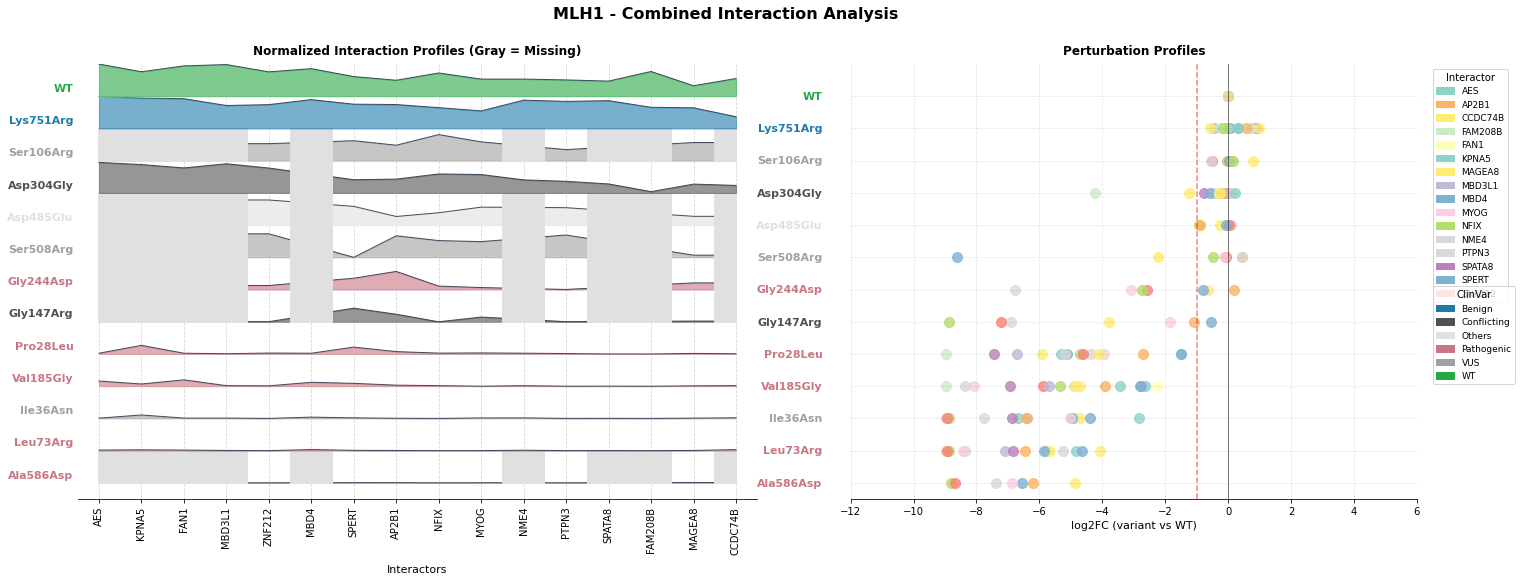

In [264]:
# single plot

fig, (ax_ridge, ax_log2fc) = plot_combined_single_gene(
    edge_df=edge_df,
    gene='MLH1',
    palette_dict=palette_dict
)

Plotting ACSF3: 10 variants, 3 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


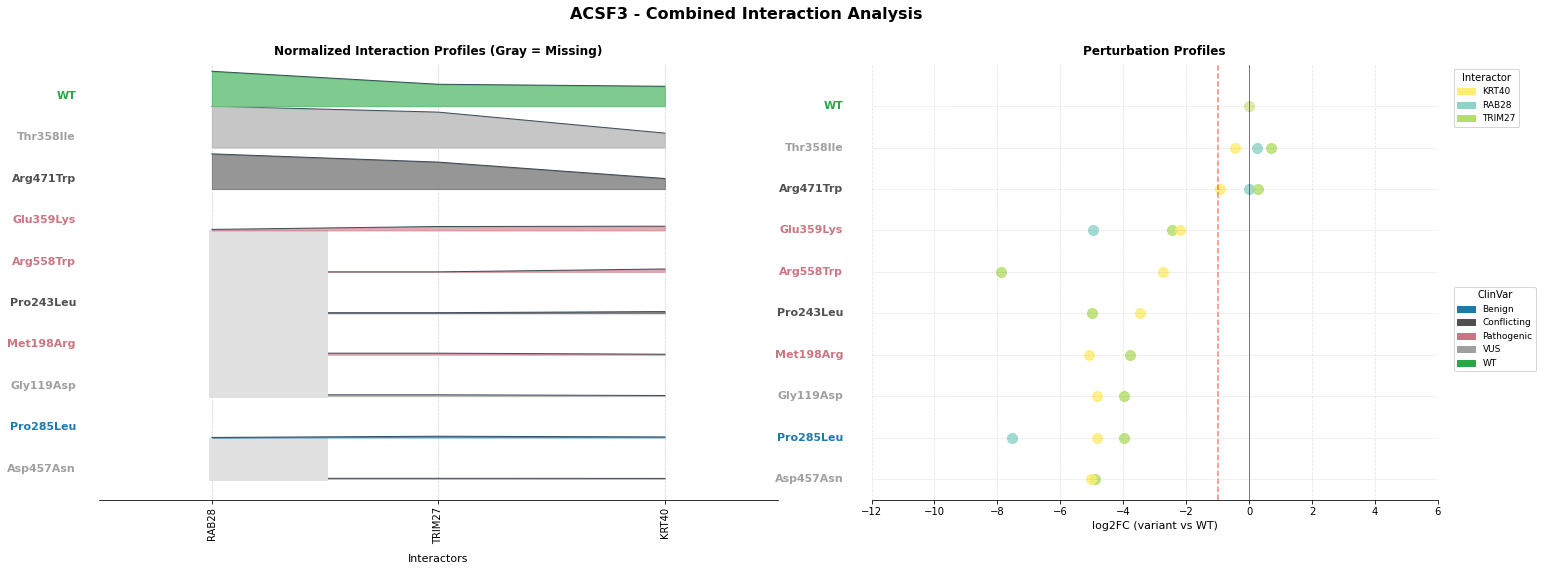

In [265]:
# single plot

fig, (ax_ridge, ax_log2fc) = plot_combined_single_gene(
    edge_df=edge_df,
    gene='ACSF3',
    palette_dict=palette_dict
)

Found 73 unique genes

Processing: ACSF3
Plotting ACSF3: 10 variants, 3 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/ACSF3_combined.pdf


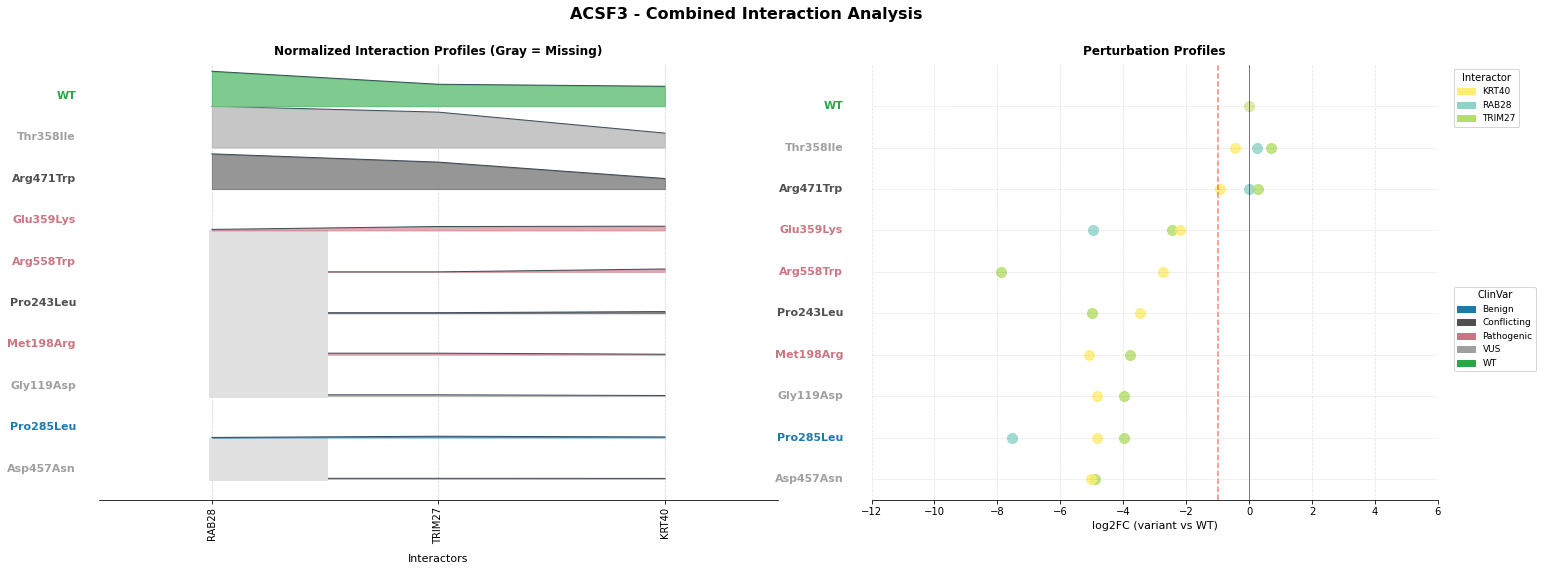


Processing: AGXT
Plotting AGXT: 37 variants, 1 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/AGXT_combined.pdf


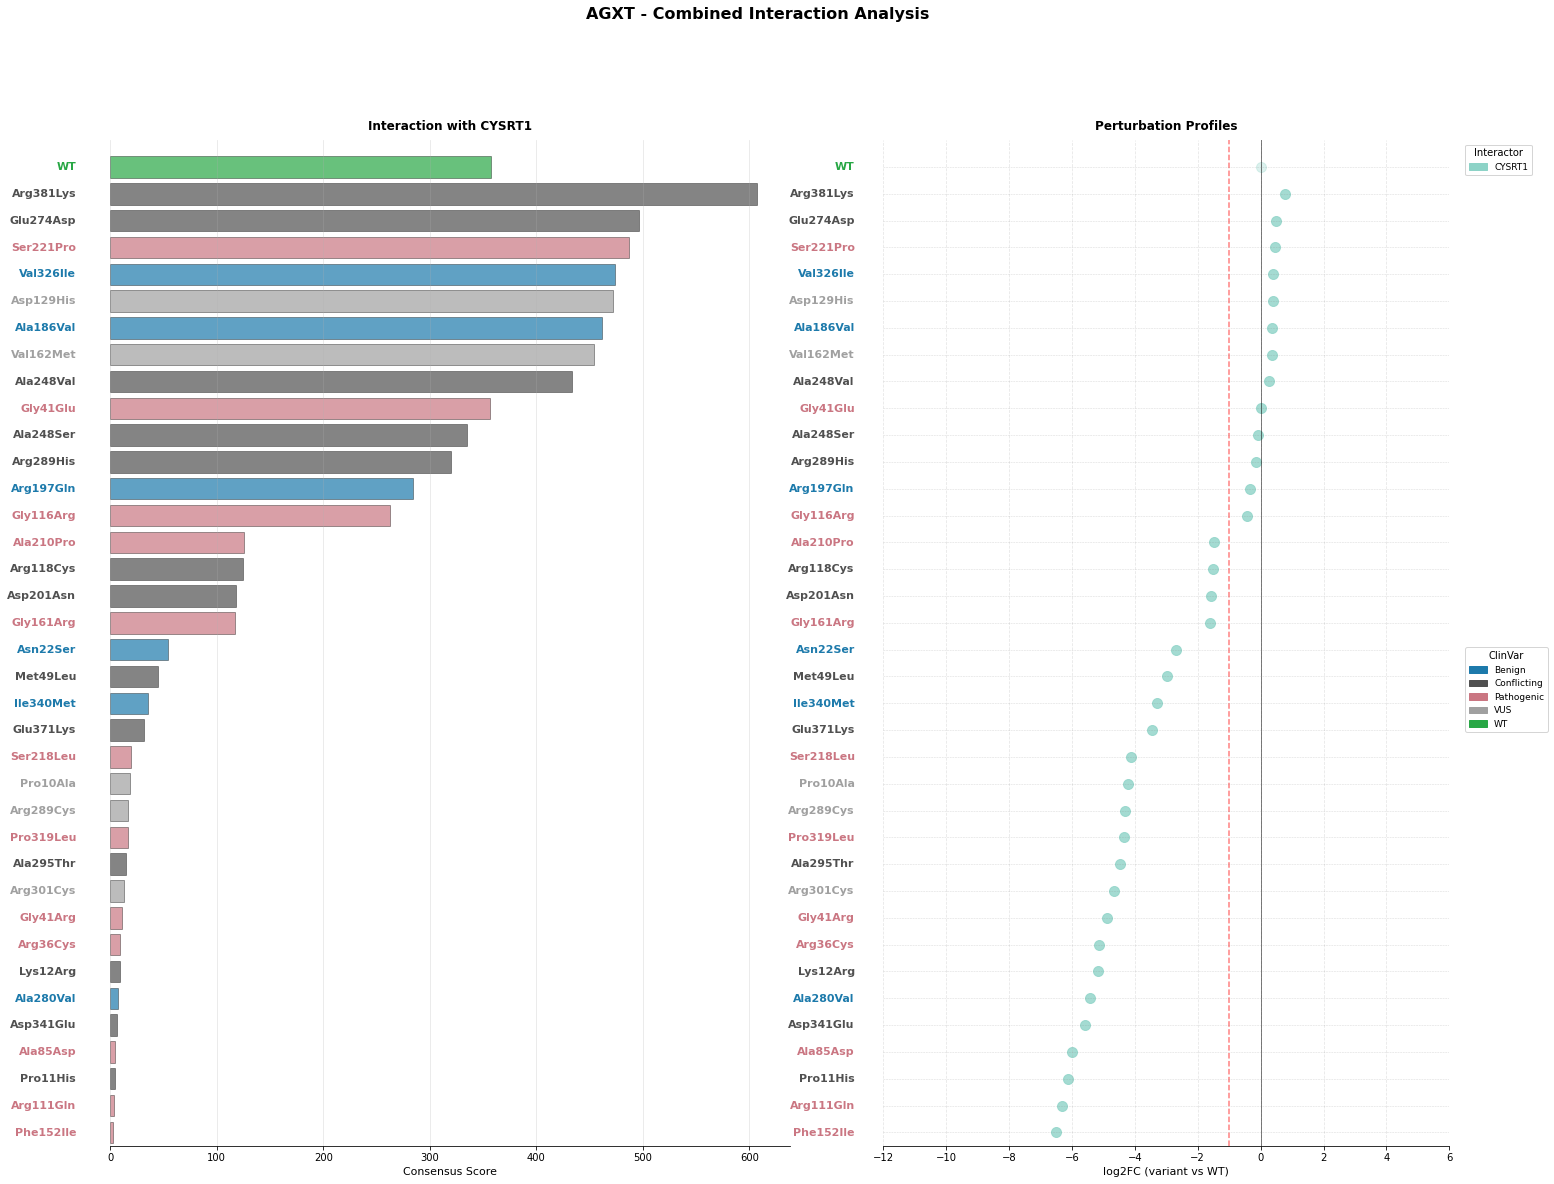


Processing: AIPL1
Plotting AIPL1: 8 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/AIPL1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


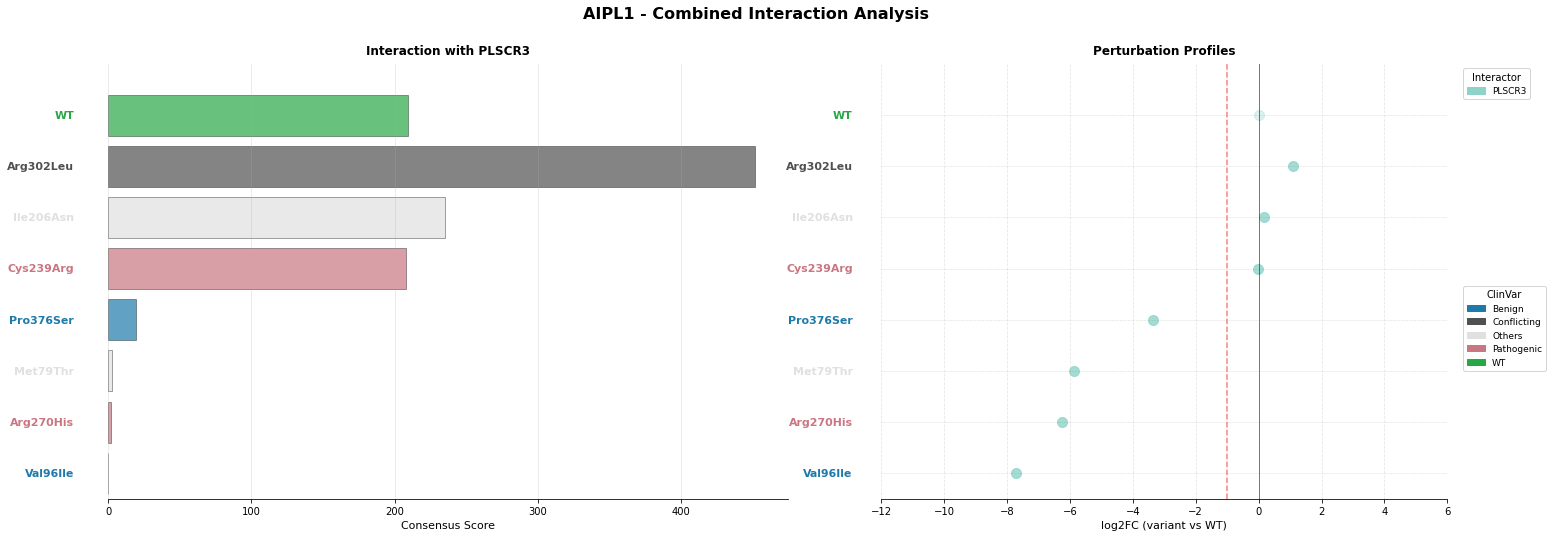


Processing: ALAS2
Plotting ALAS2: 10 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/ALAS2_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


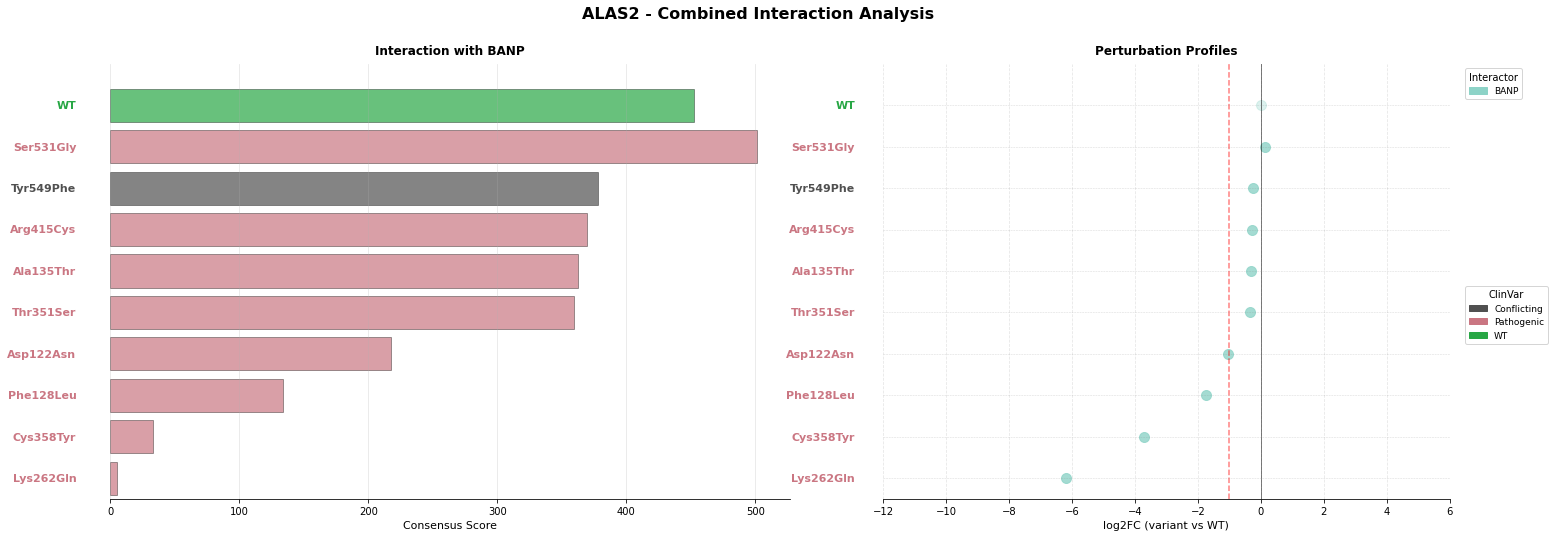


Processing: AP2S1
Plotting AP2S1: 3 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/AP2S1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


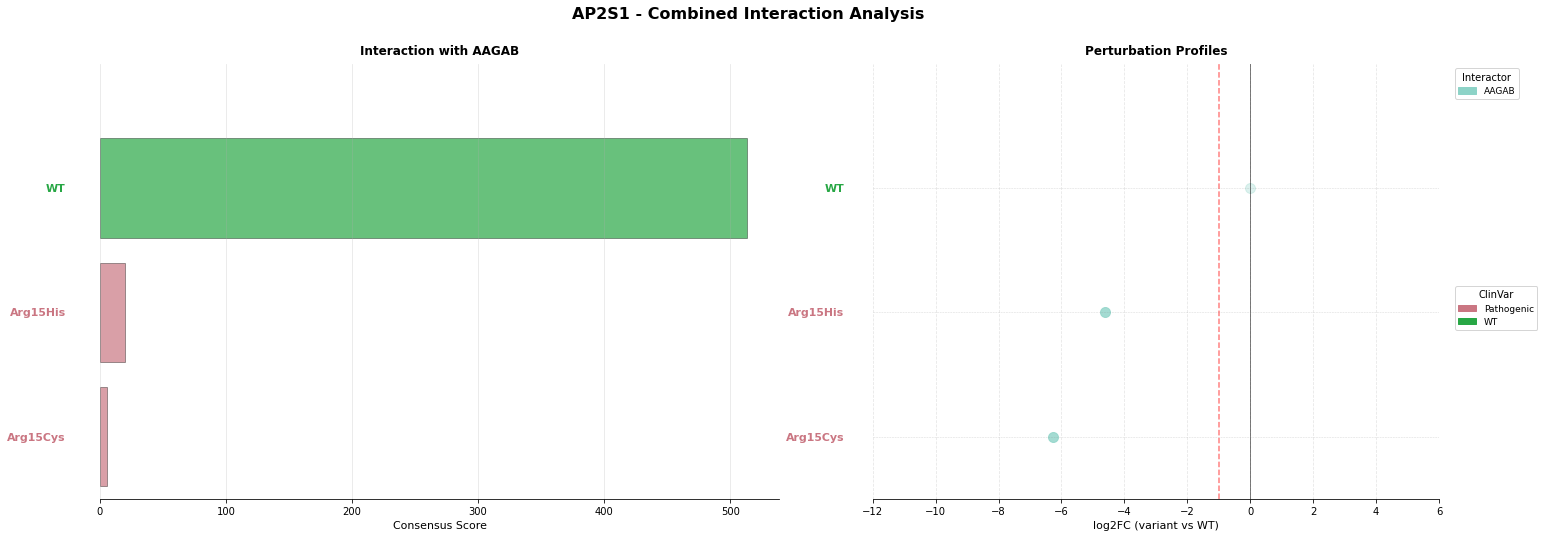


Processing: ASNS
Plotting ASNS: 2 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/ASNS_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


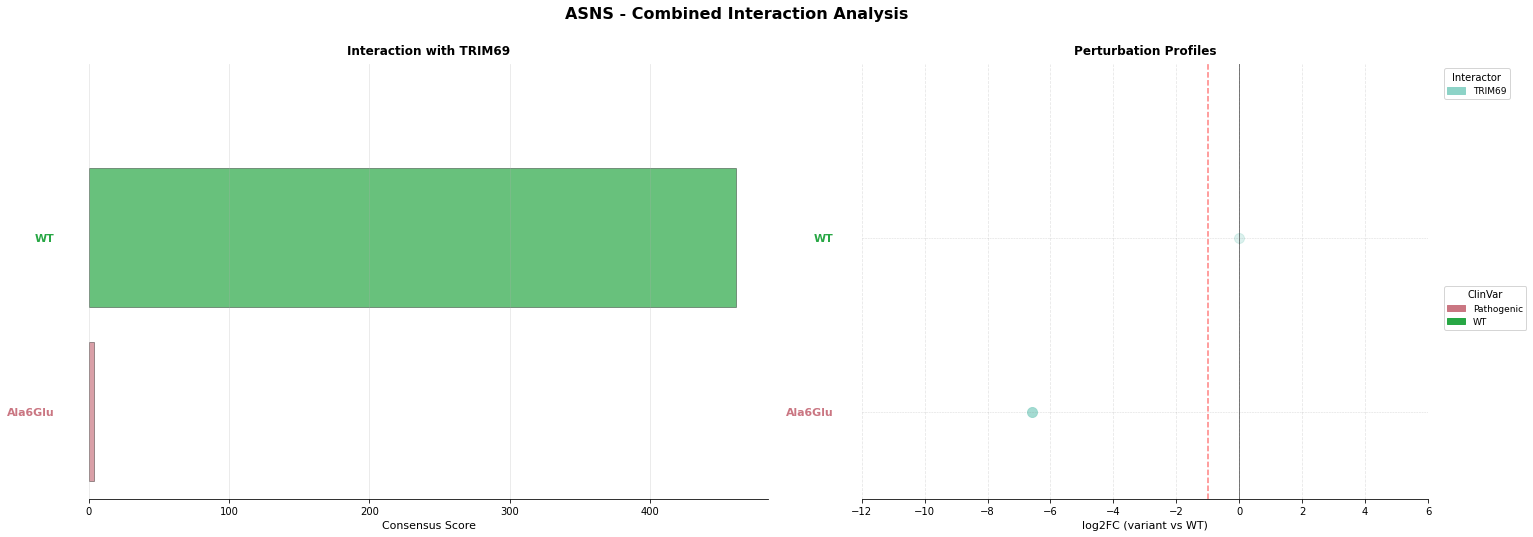


Processing: BAG3
Plotting BAG3: 4 variants, 14 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/BAG3_combined.pdf


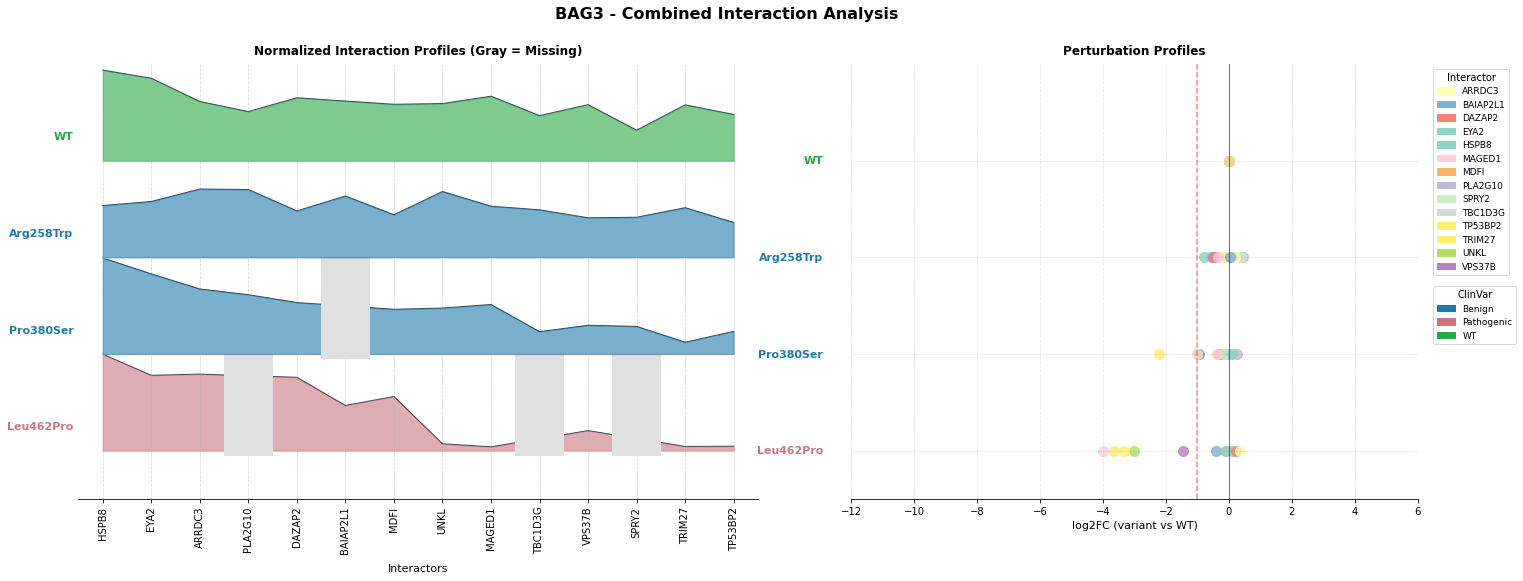


Processing: CHN1
Plotting CHN1: 4 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/CHN1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


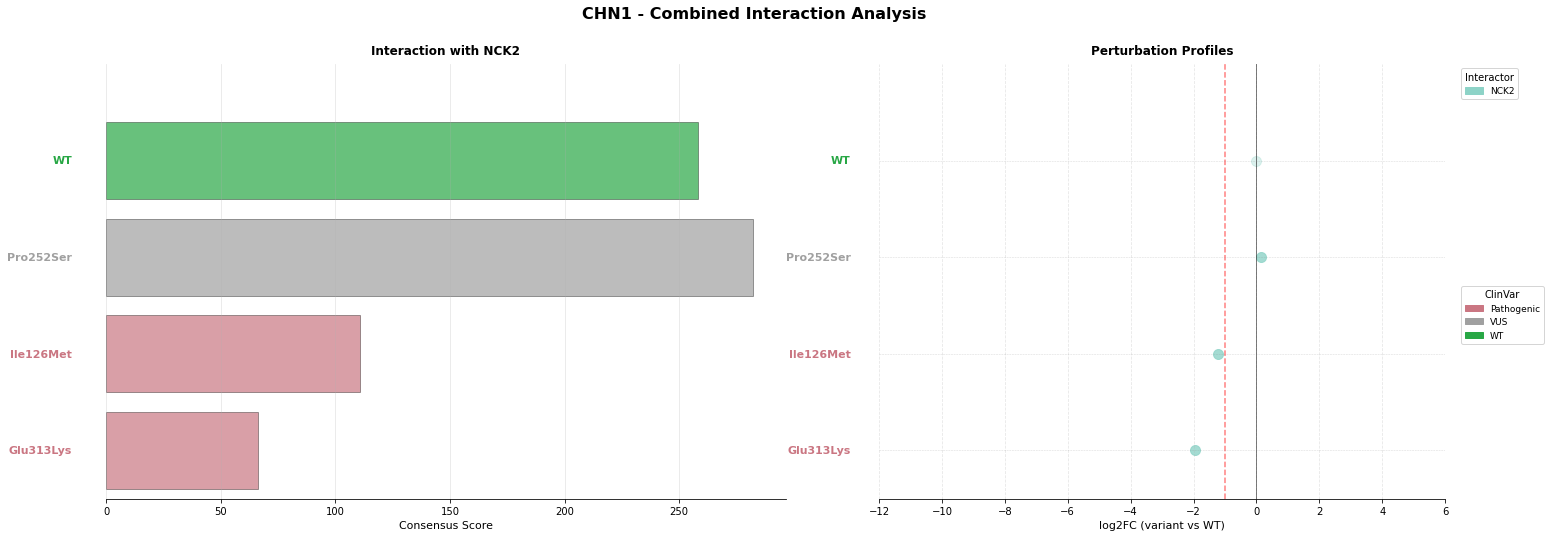


Processing: CLN6
Plotting CLN6: 4 variants, 1 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/CLN6_combined.pdf


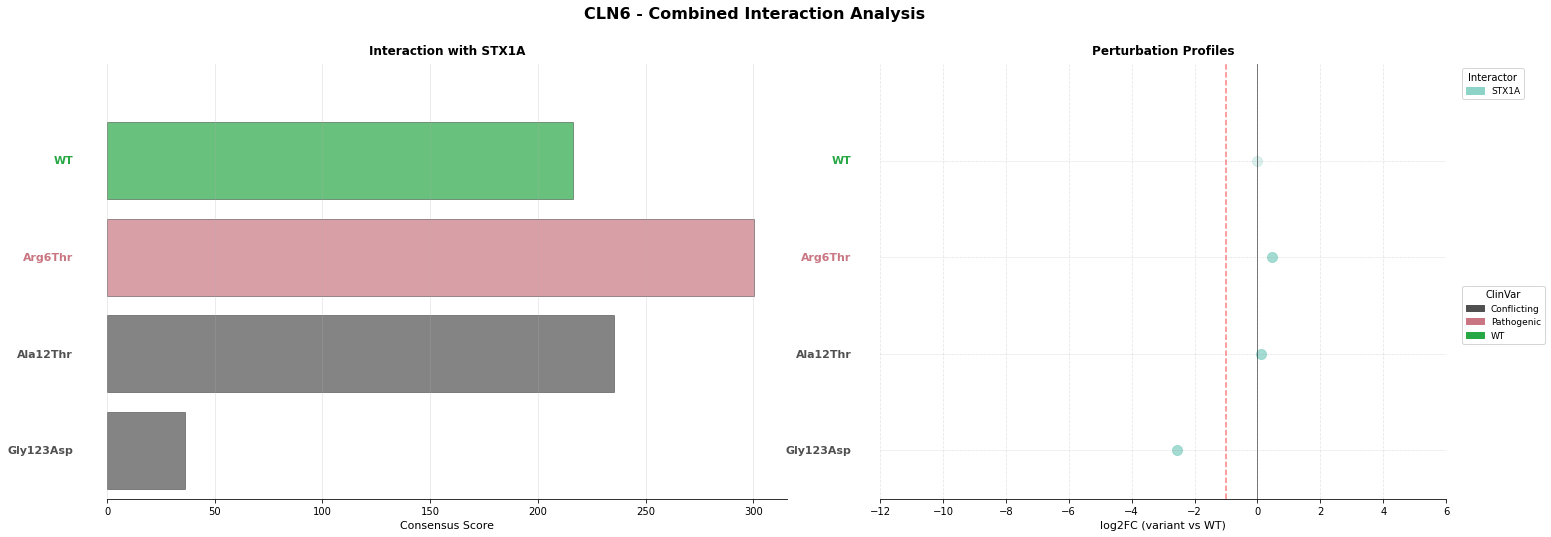


Processing: COL2A1
Plotting COL2A1: 3 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/COL2A1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


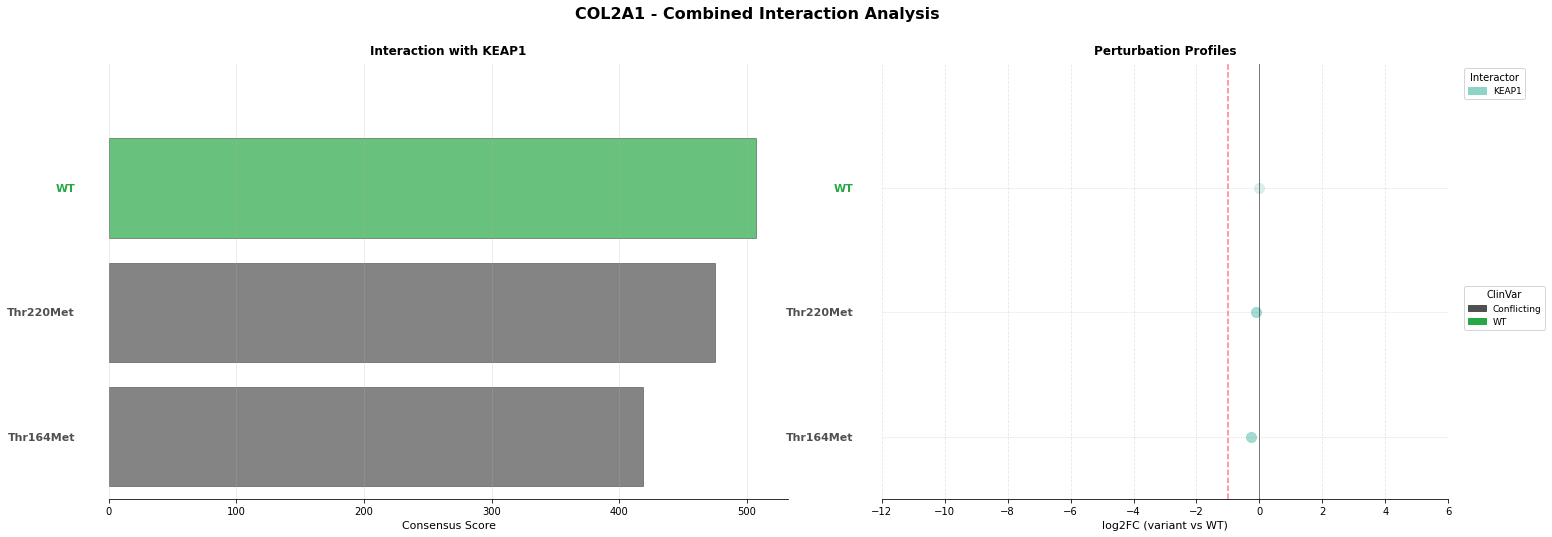


Processing: COQ8A
Plotting COQ8A: 3 variants, 6 interactors
Saved: ../3_outputs/sqY2H/combined_plots/COQ8A_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


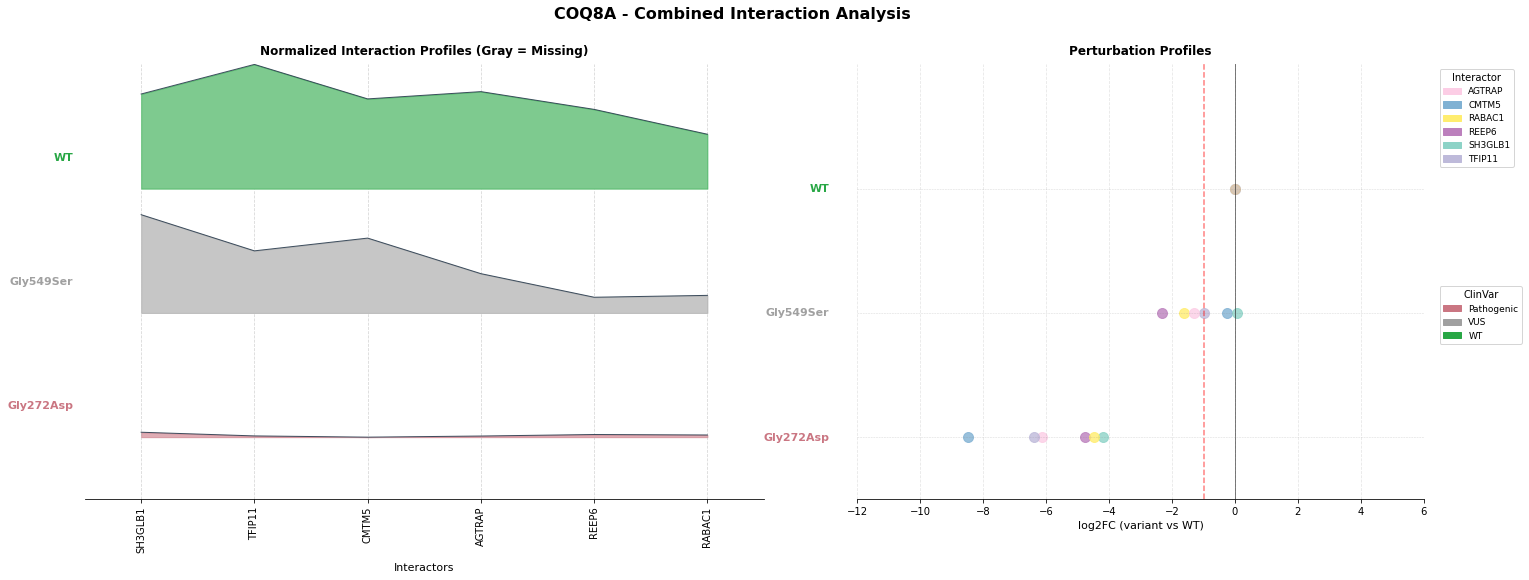


Processing: CRYAB
Plotting CRYAB: 3 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/CRYAB_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


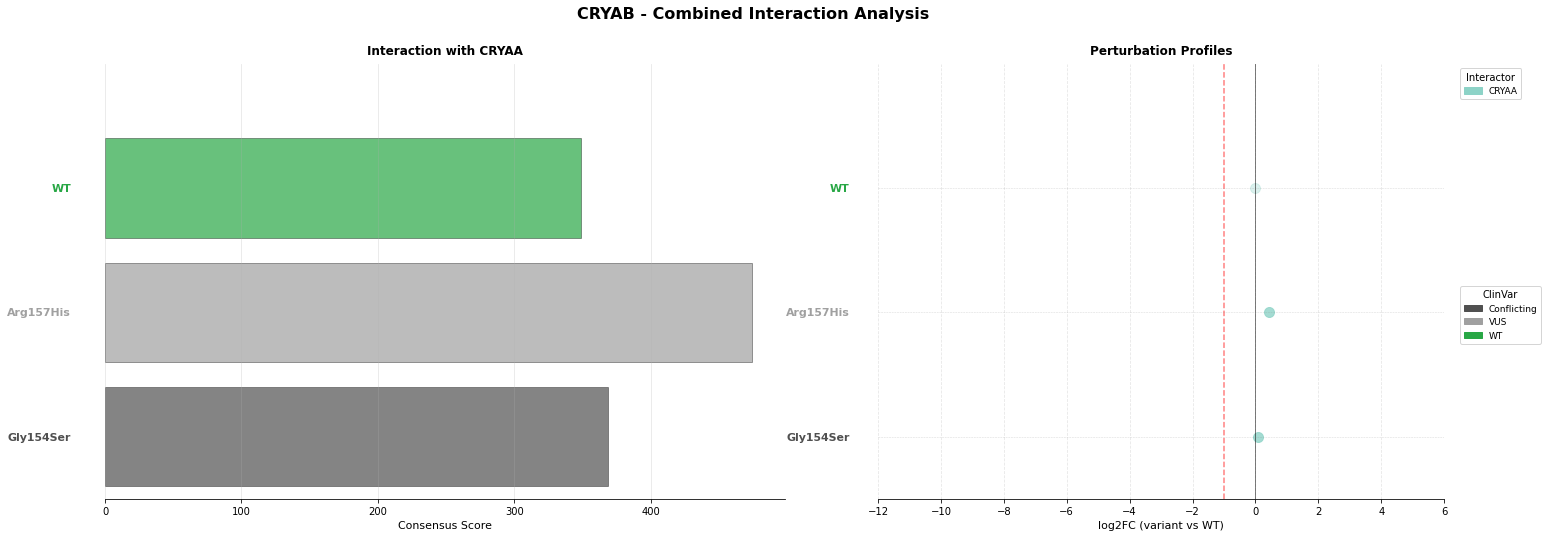


Processing: EMD
Plotting EMD: 5 variants, 11 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/EMD_combined.pdf


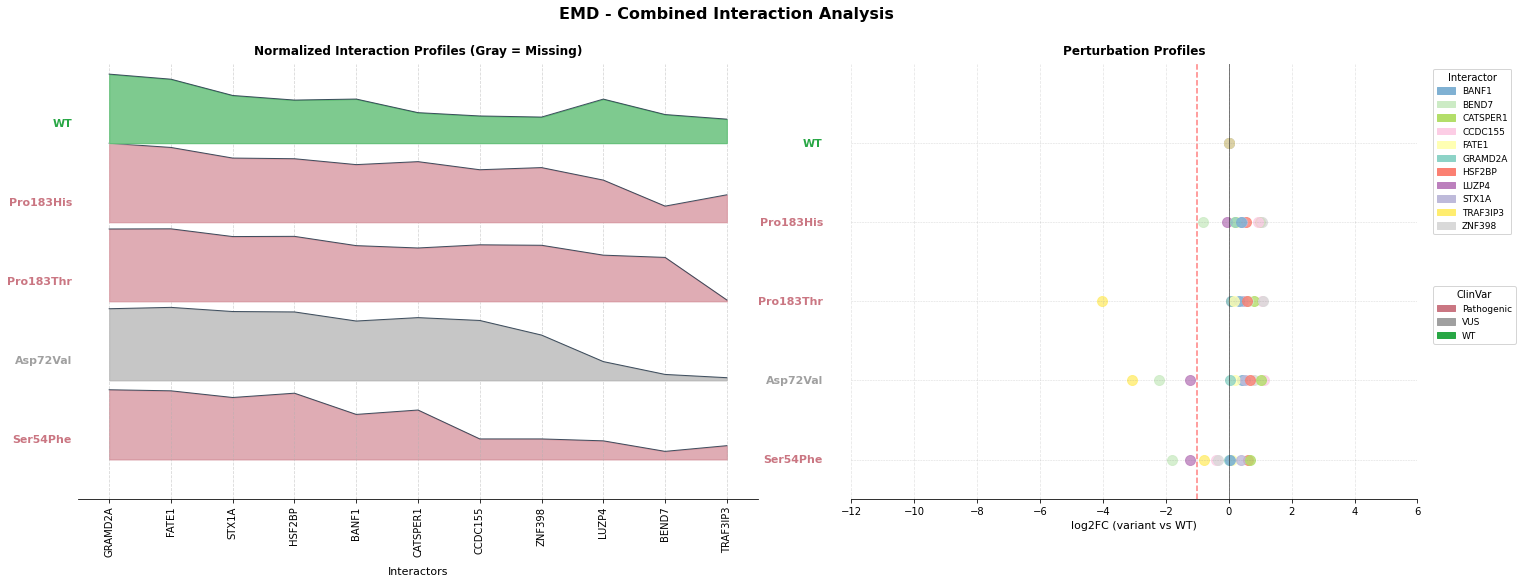


Processing: EZH2
Plotting EZH2: 2 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/EZH2_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


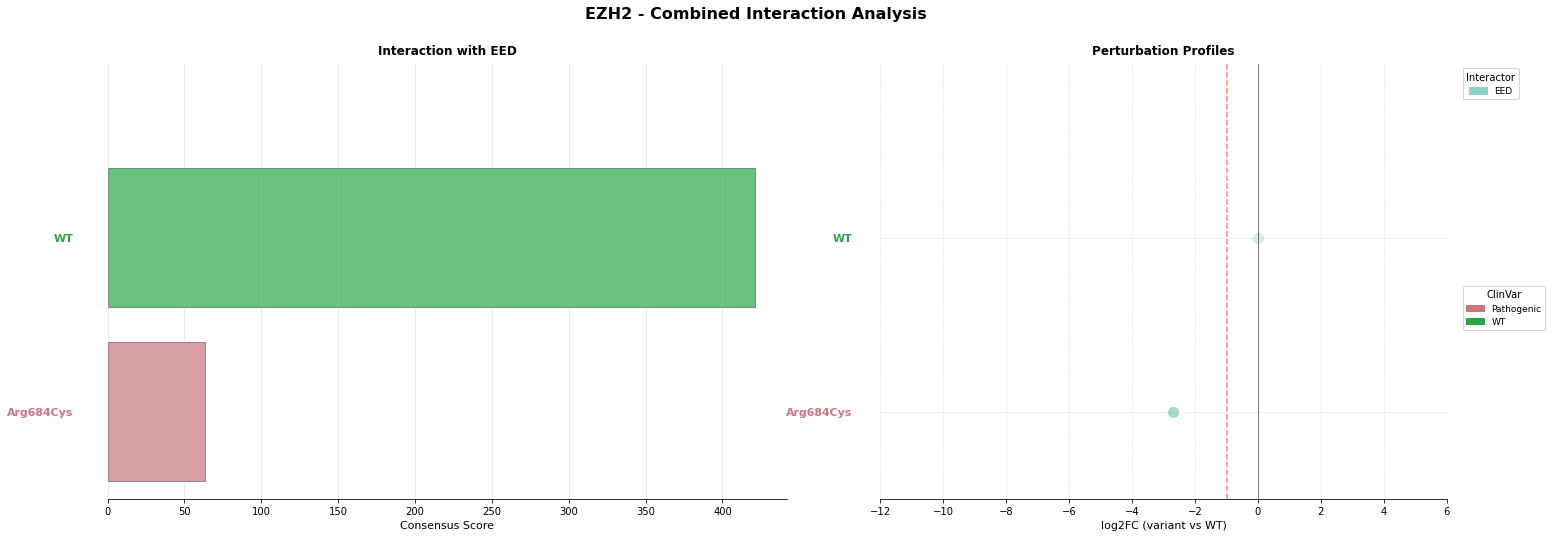


Processing: FA2H
Plotting FA2H: 3 variants, 3 interactors
Saved: ../3_outputs/sqY2H/combined_plots/FA2H_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


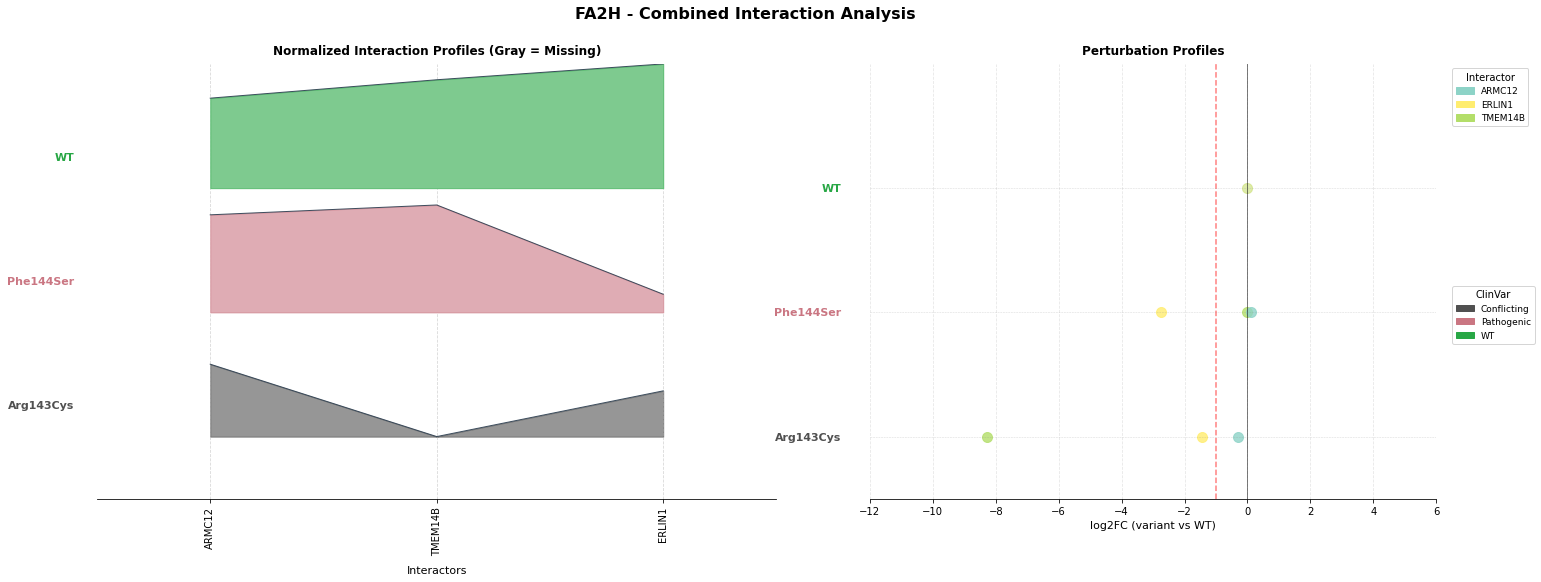


Processing: FBP1
Plotting FBP1: 3 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/FBP1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


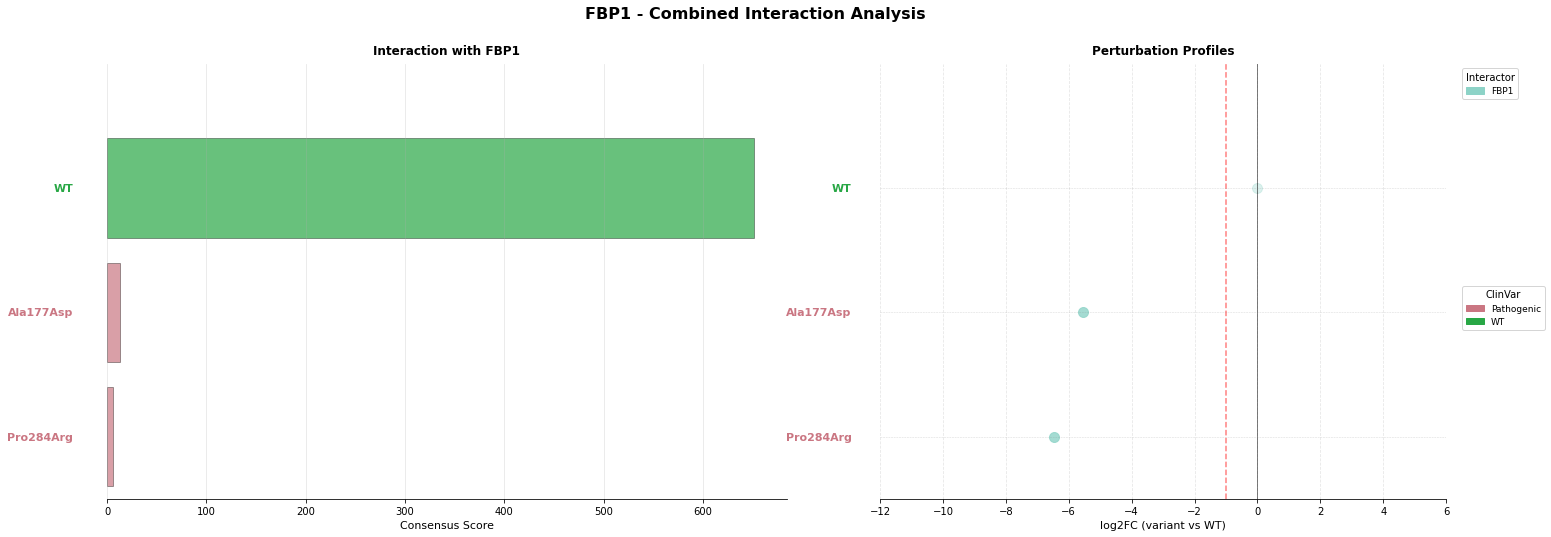


Processing: GALE
Plotting GALE: 6 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/GALE_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


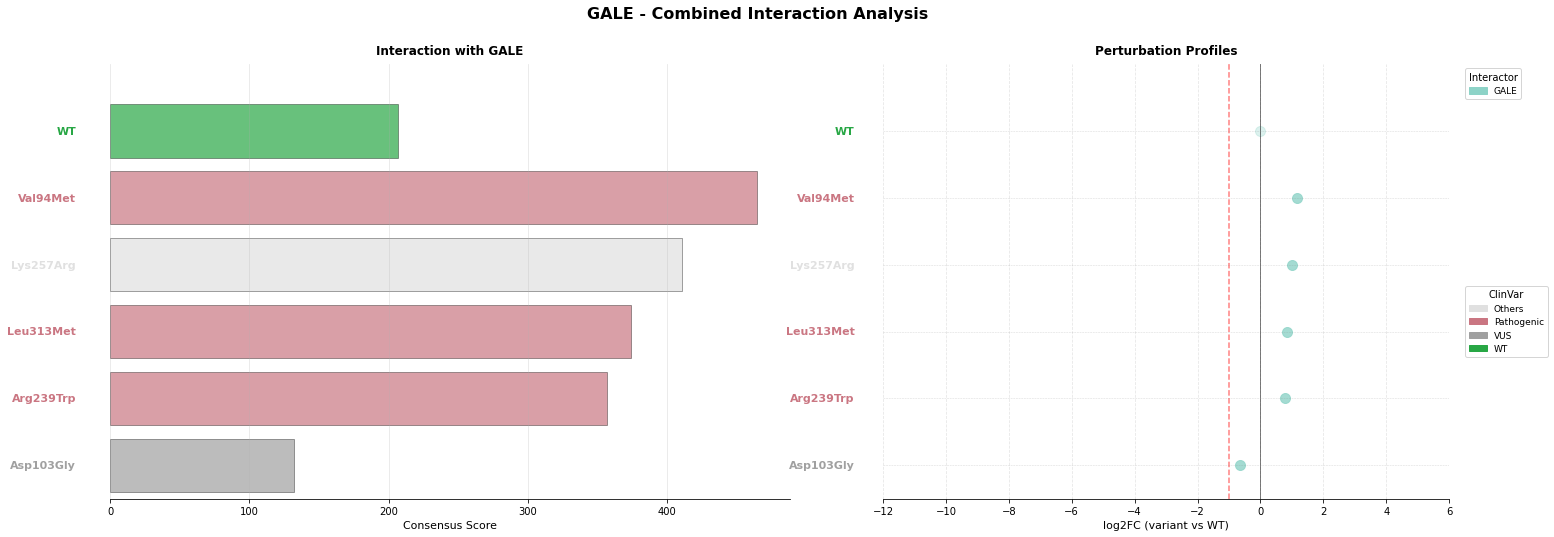


Processing: GATA2
Plotting GATA2: 2 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/GATA2_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


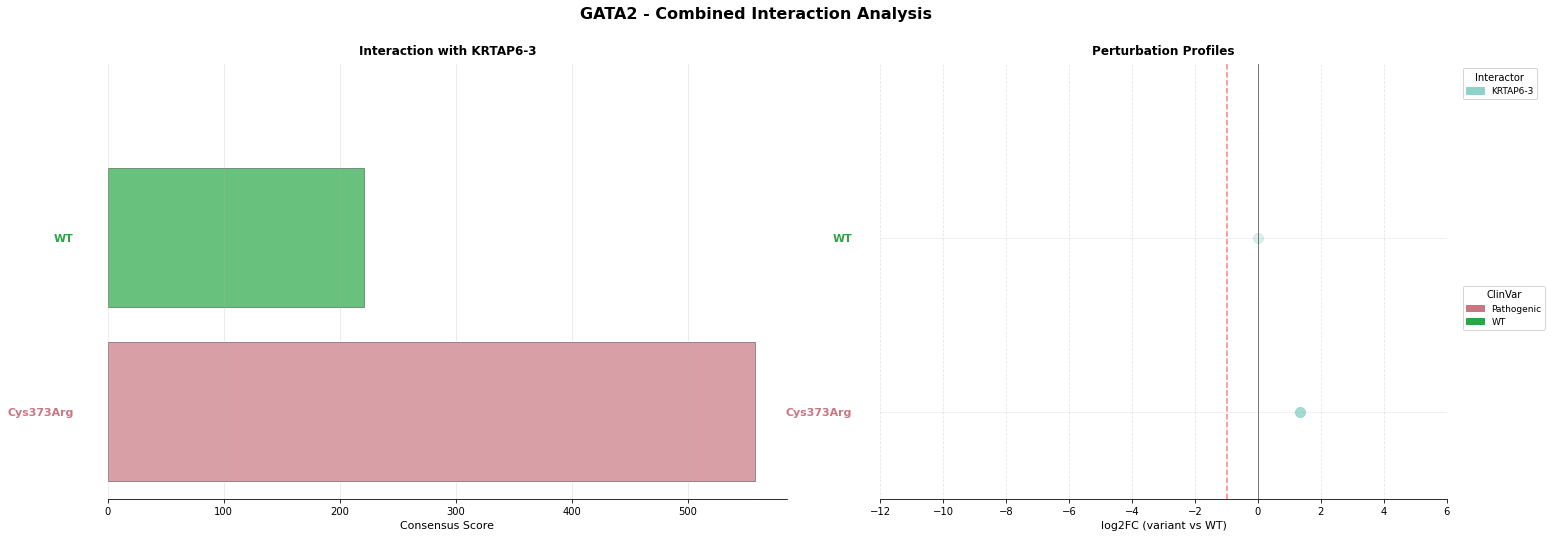


Processing: GCK
Plotting GCK: 8 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/GCK_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


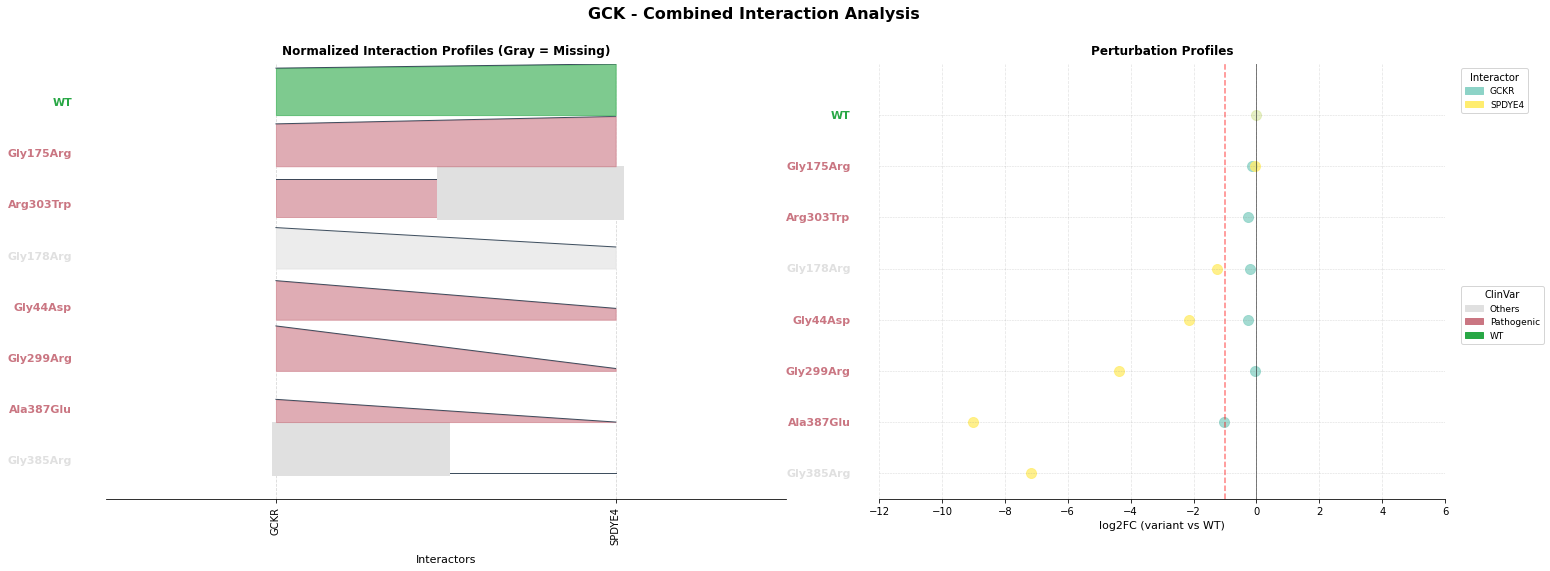


Processing: GFAP
Plotting GFAP: 18 variants, 5 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/GFAP_combined.pdf


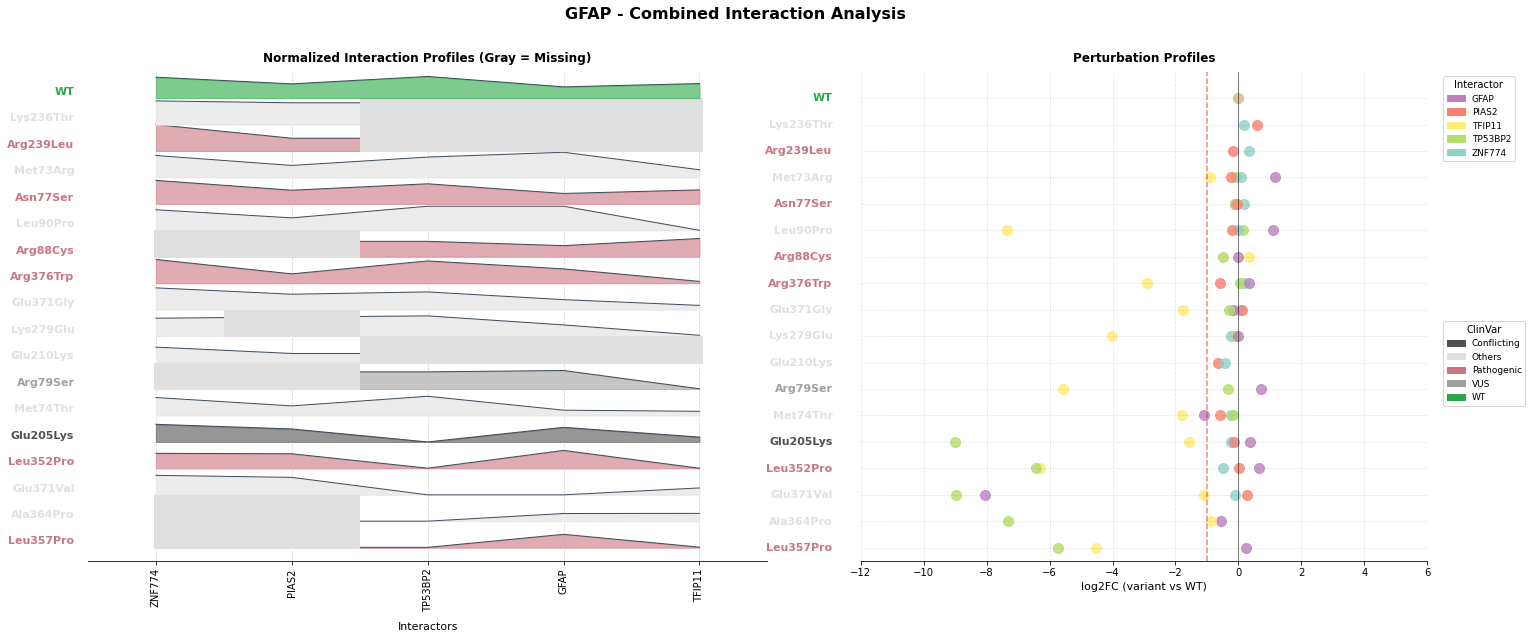


Processing: GRN
Plotting GRN: 5 variants, 7 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/GRN_combined.pdf


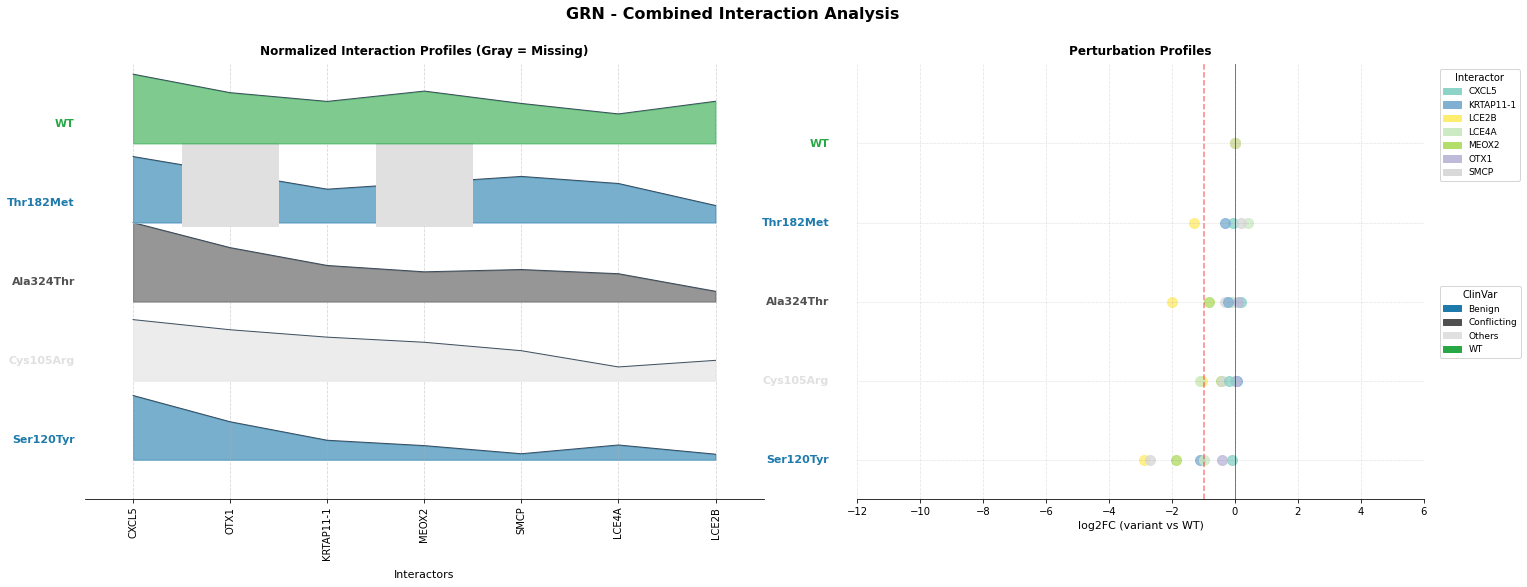


Processing: GSS
Plotting GSS: 4 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/GSS_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


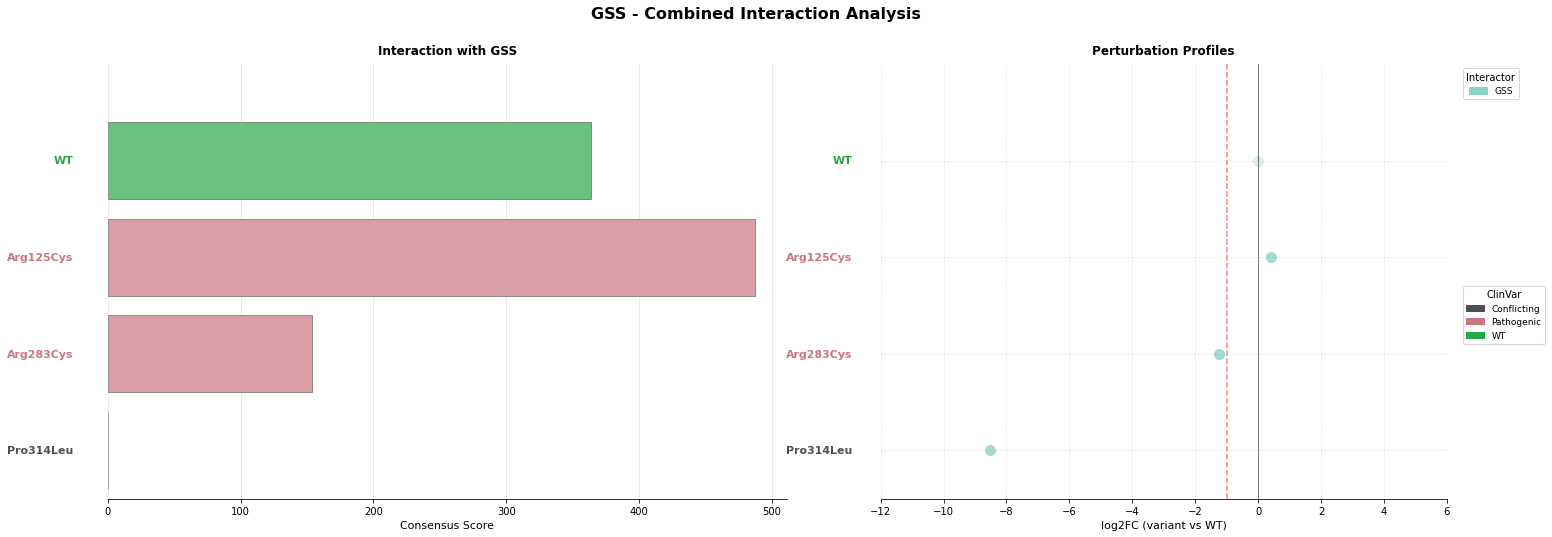


Processing: HBD
Plotting HBD: 12 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/HBD_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


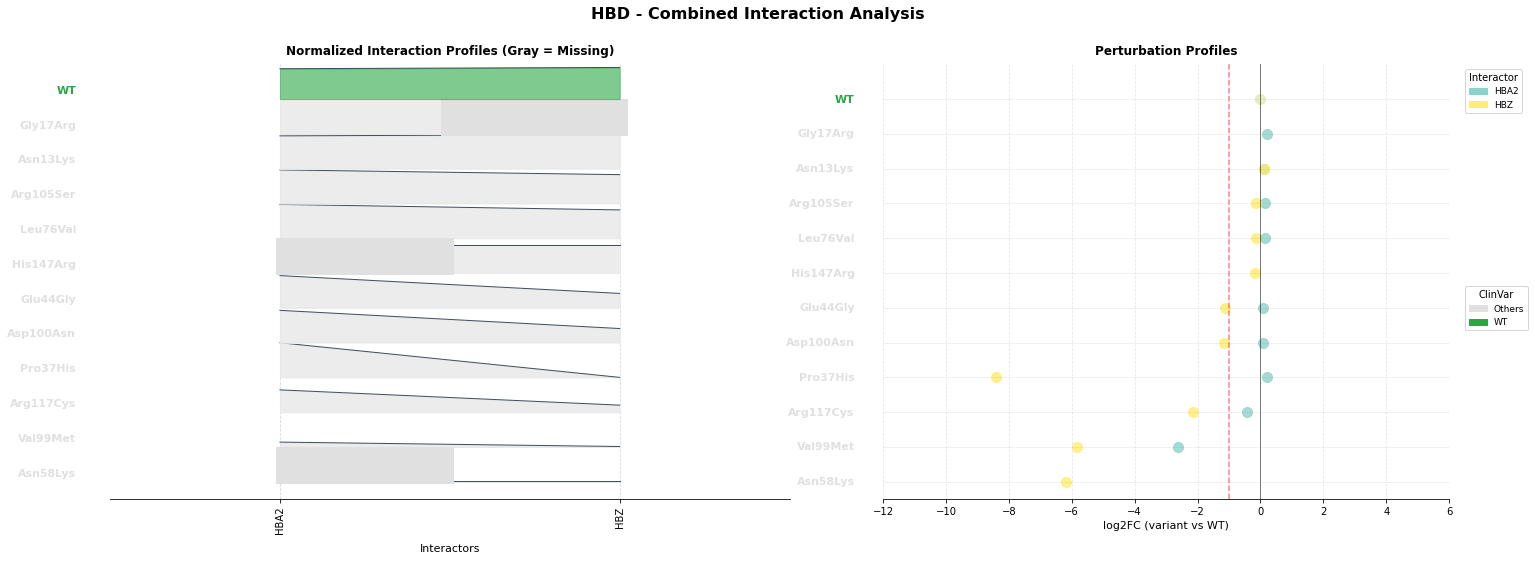


Processing: HGD
Plotting HGD: 7 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/HGD_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


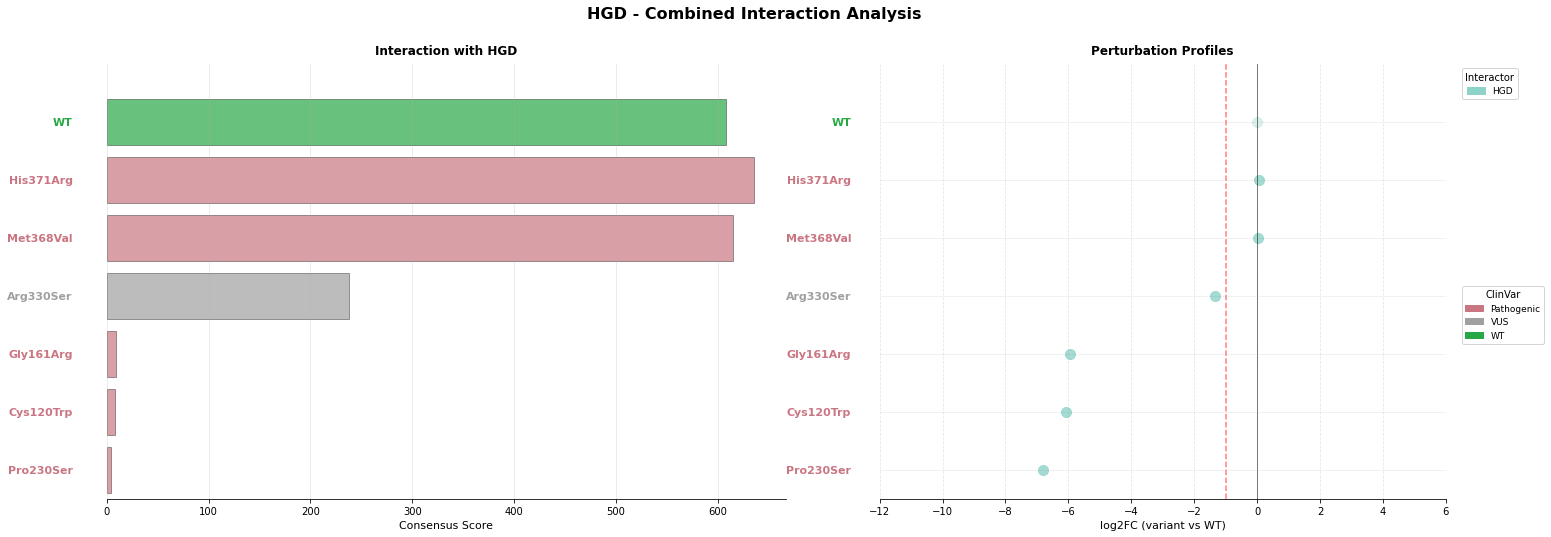


Processing: HMBS
Plotting HMBS: 17 variants, 1 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/HMBS_combined.pdf


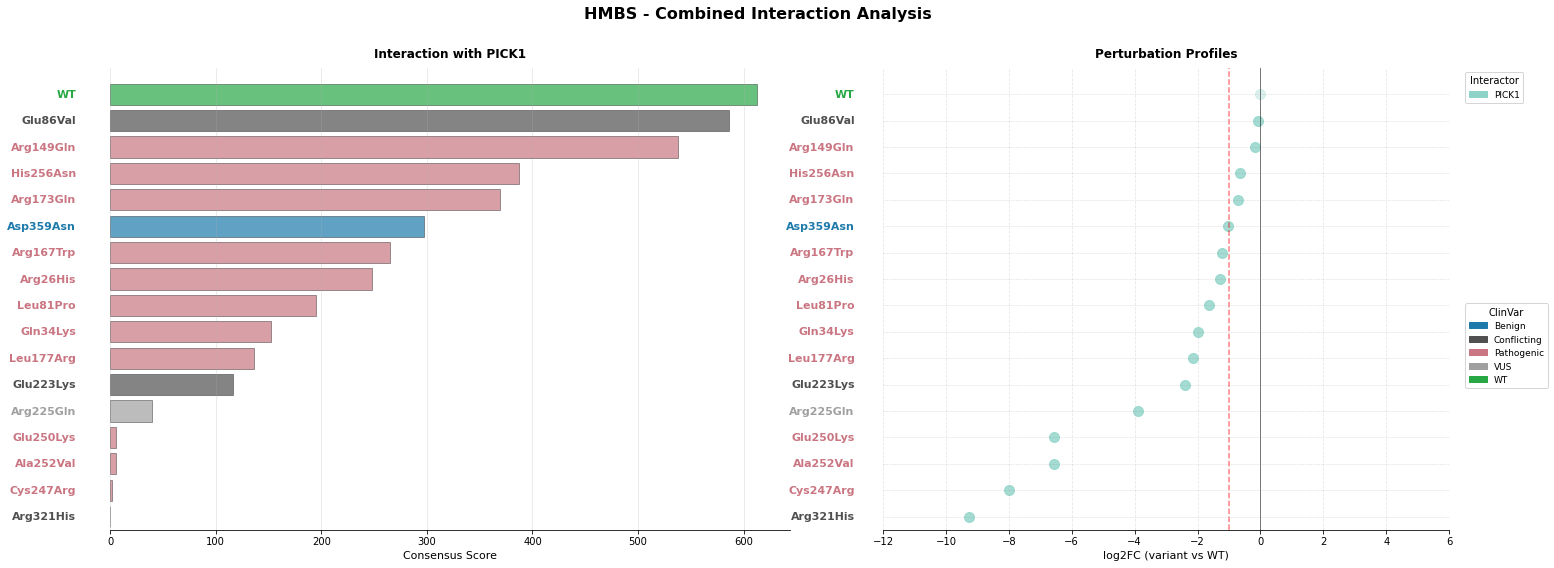


Processing: HPRT1
Plotting HPRT1: 14 variants, 2 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/HPRT1_combined.pdf


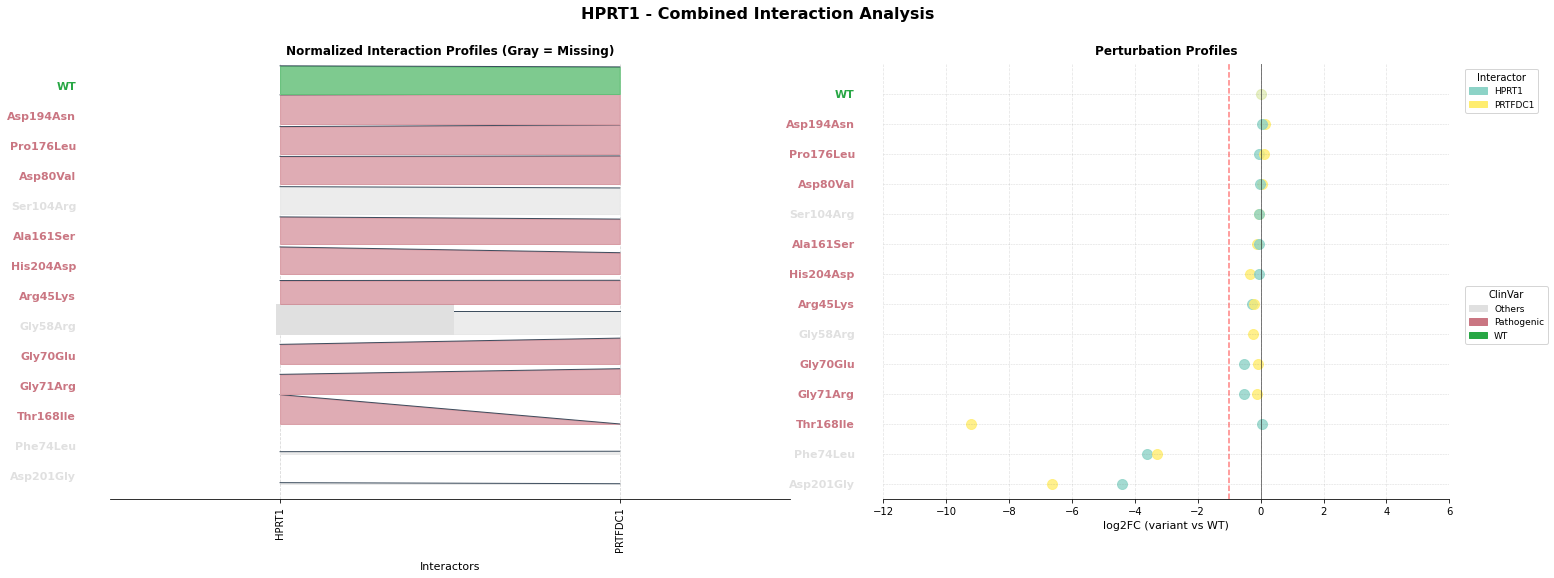


Processing: IER3IP1
Plotting IER3IP1: 3 variants, 5 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/IER3IP1_combined.pdf


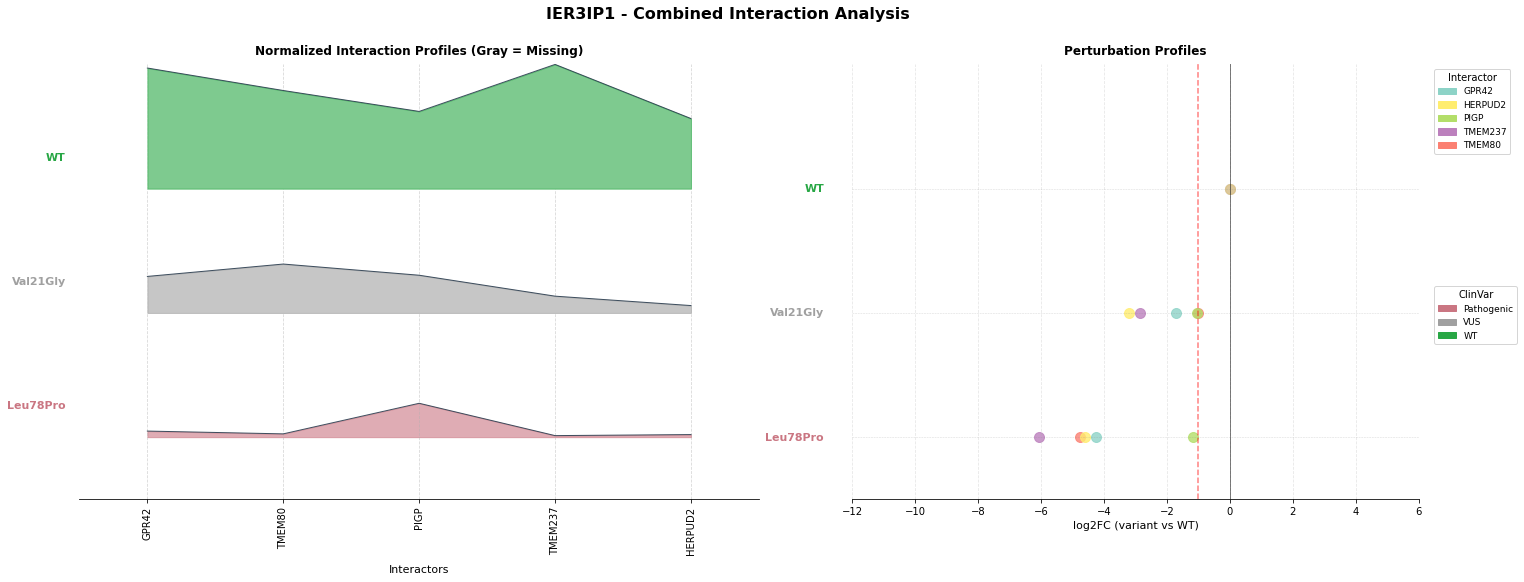


Processing: IL36RN
Plotting IL36RN: 5 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/IL36RN_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


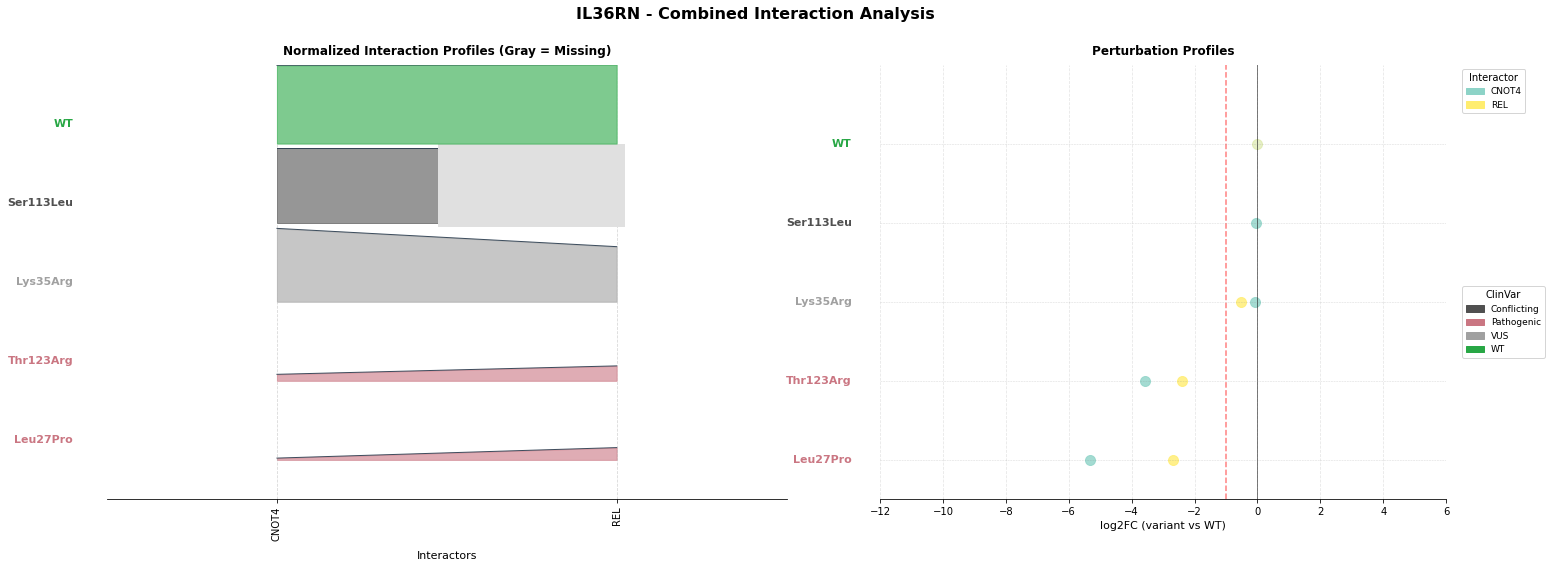


Processing: IMPDH1
Plotting IMPDH1: 3 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/IMPDH1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


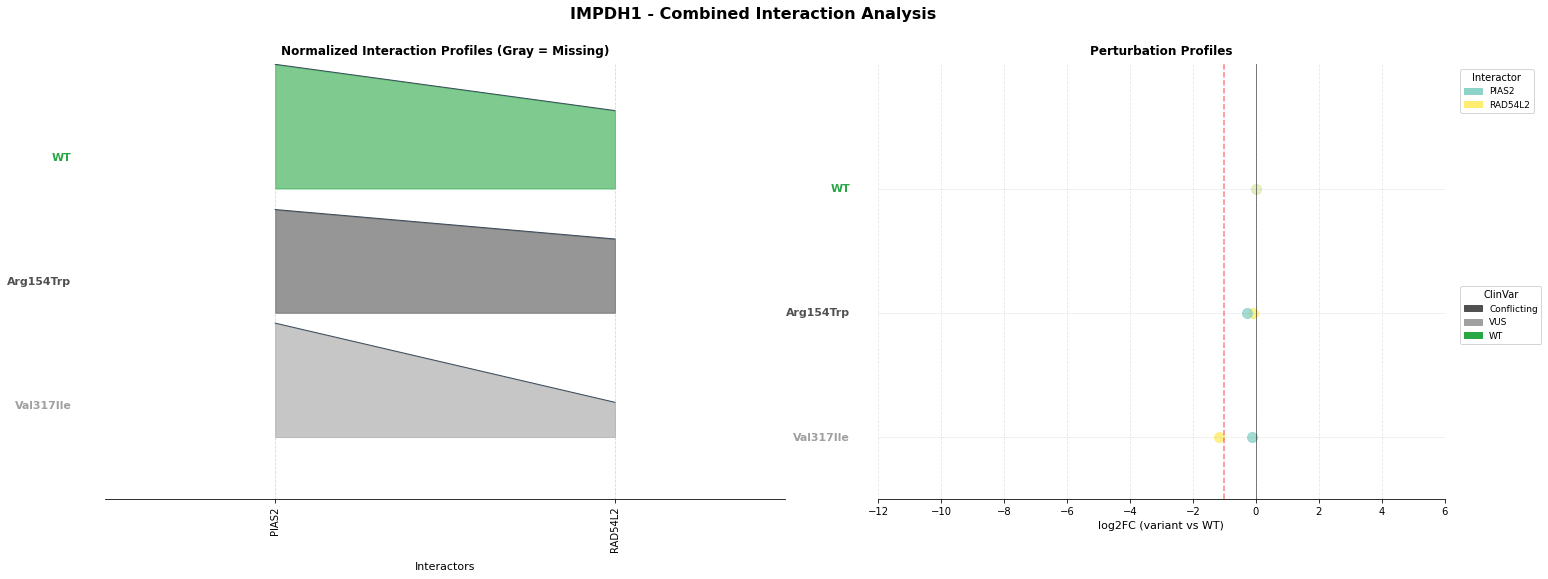


Processing: KCNJ2
Plotting KCNJ2: 27 variants, 2 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/KCNJ2_combined.pdf


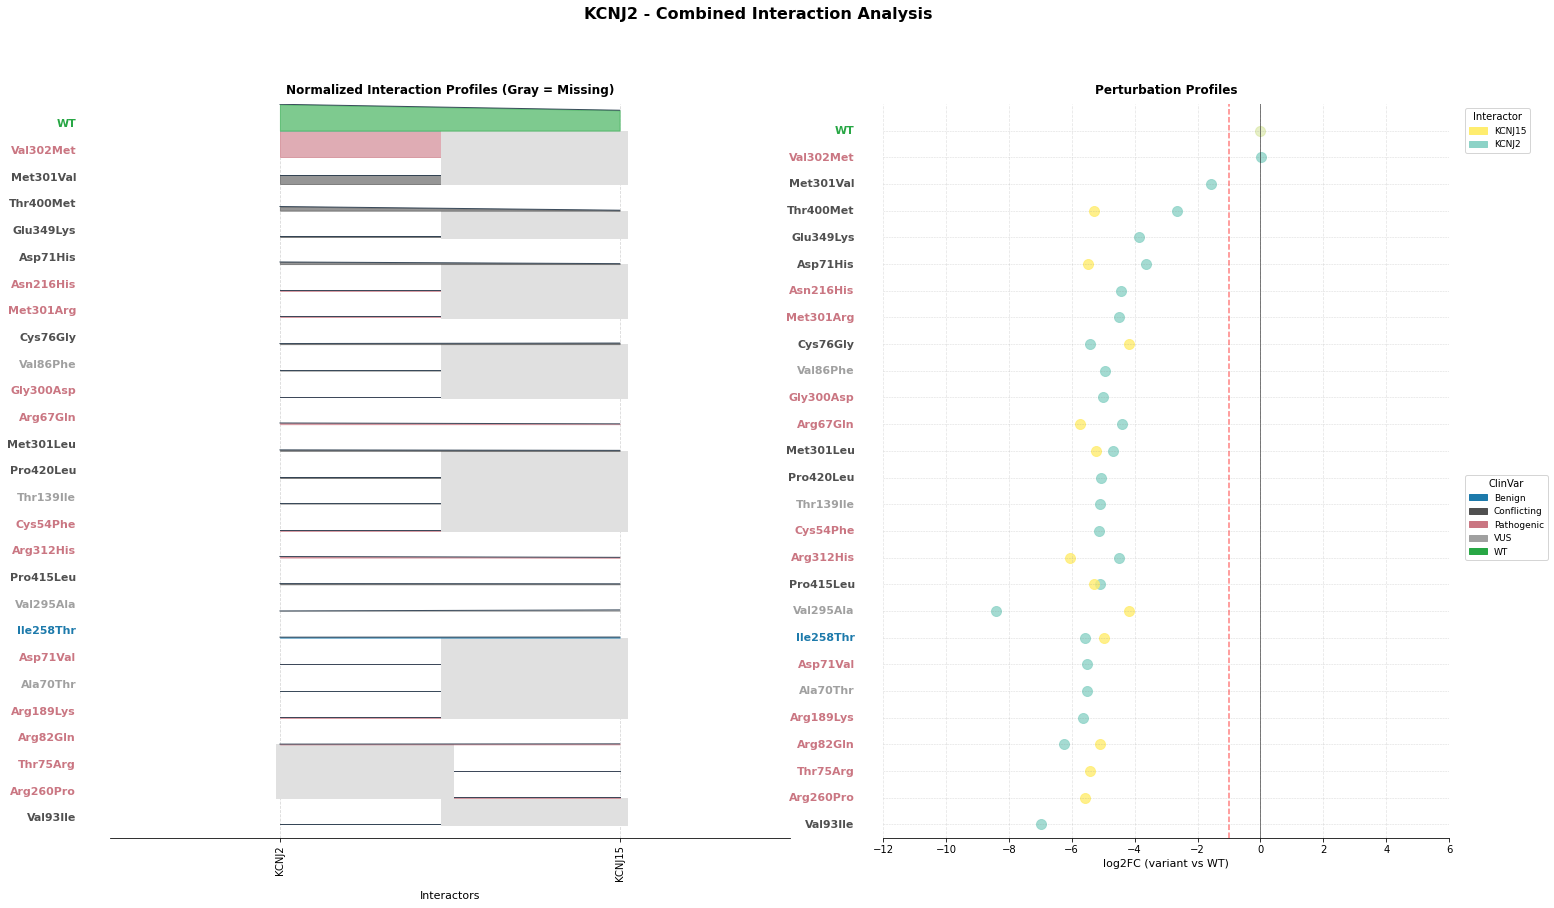


Processing: KCTD1
Plotting KCTD1: 6 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/KCTD1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


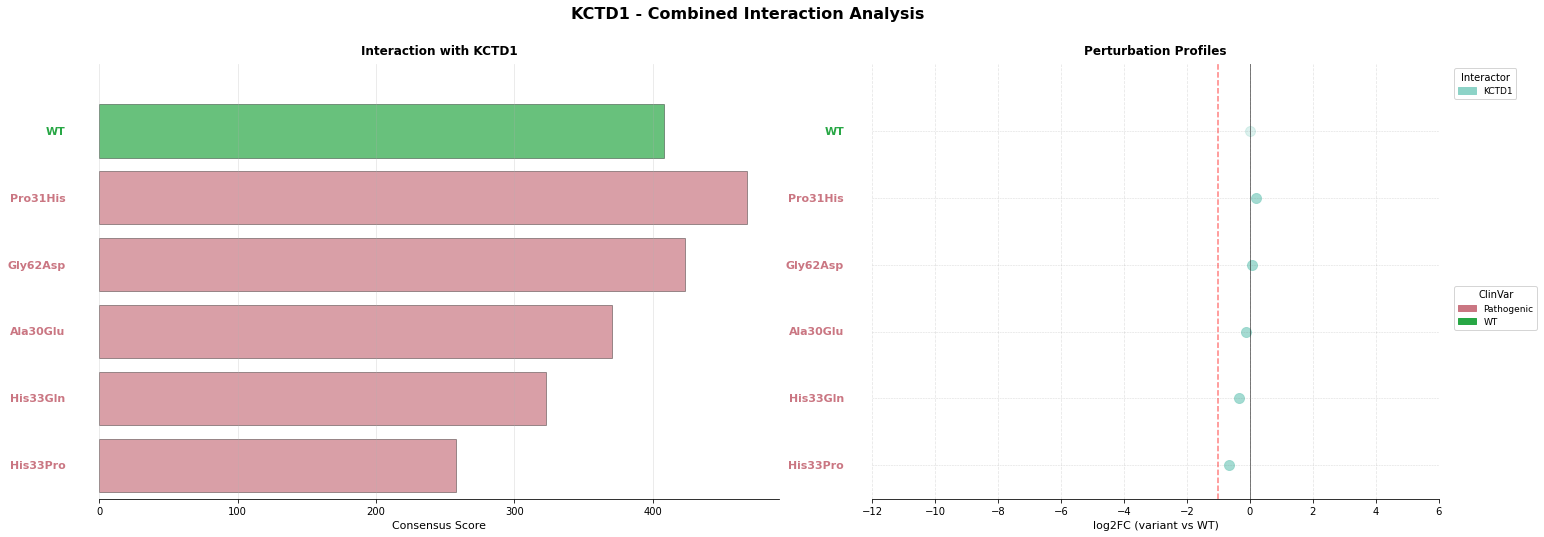


Processing: KCTD7
Plotting KCTD7: 4 variants, 7 interactors
Saved: ../3_outputs/sqY2H/combined_plots/KCTD7_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


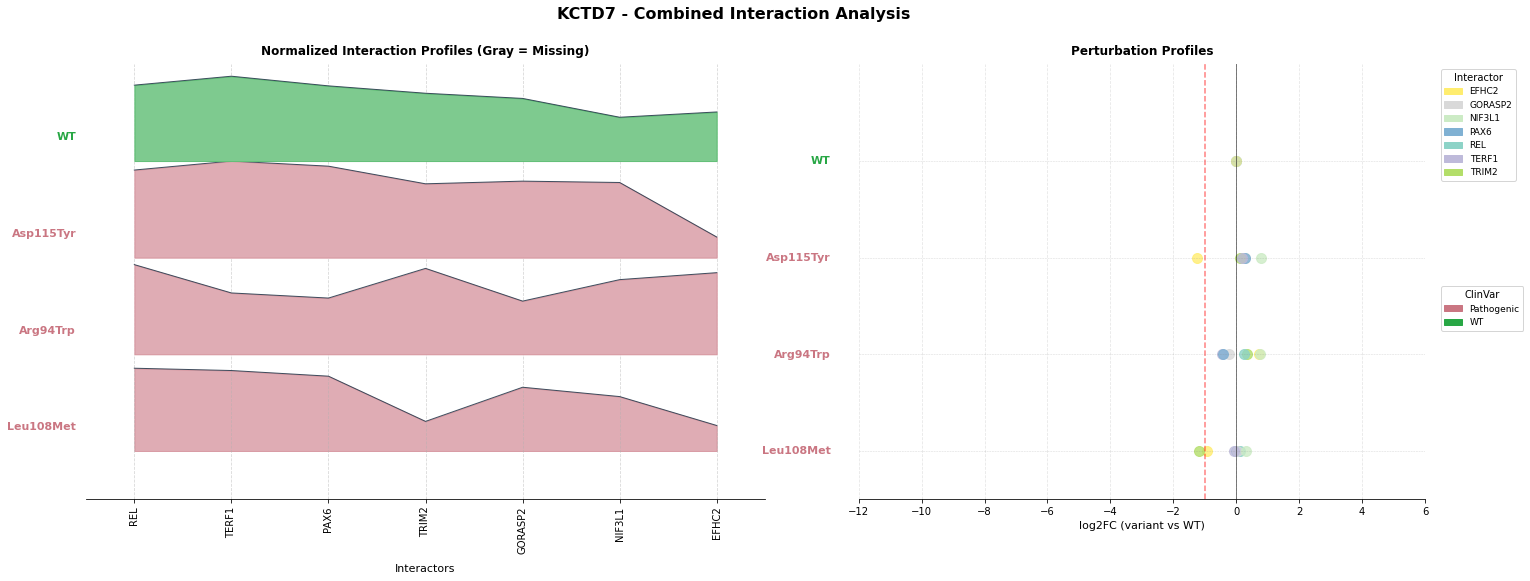


Processing: KRT2
Plotting KRT2: 5 variants, 3 interactors
Saved: ../3_outputs/sqY2H/combined_plots/KRT2_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


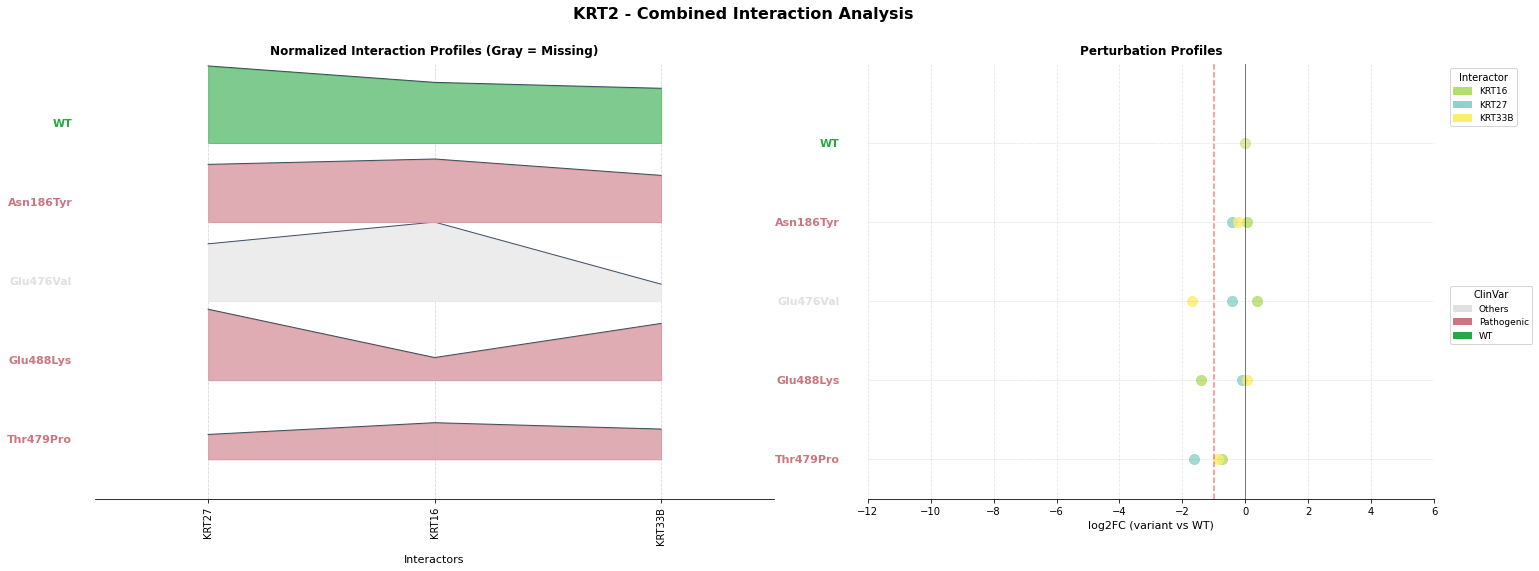


Processing: KRT5
Plotting KRT5: 3 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/KRT5_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


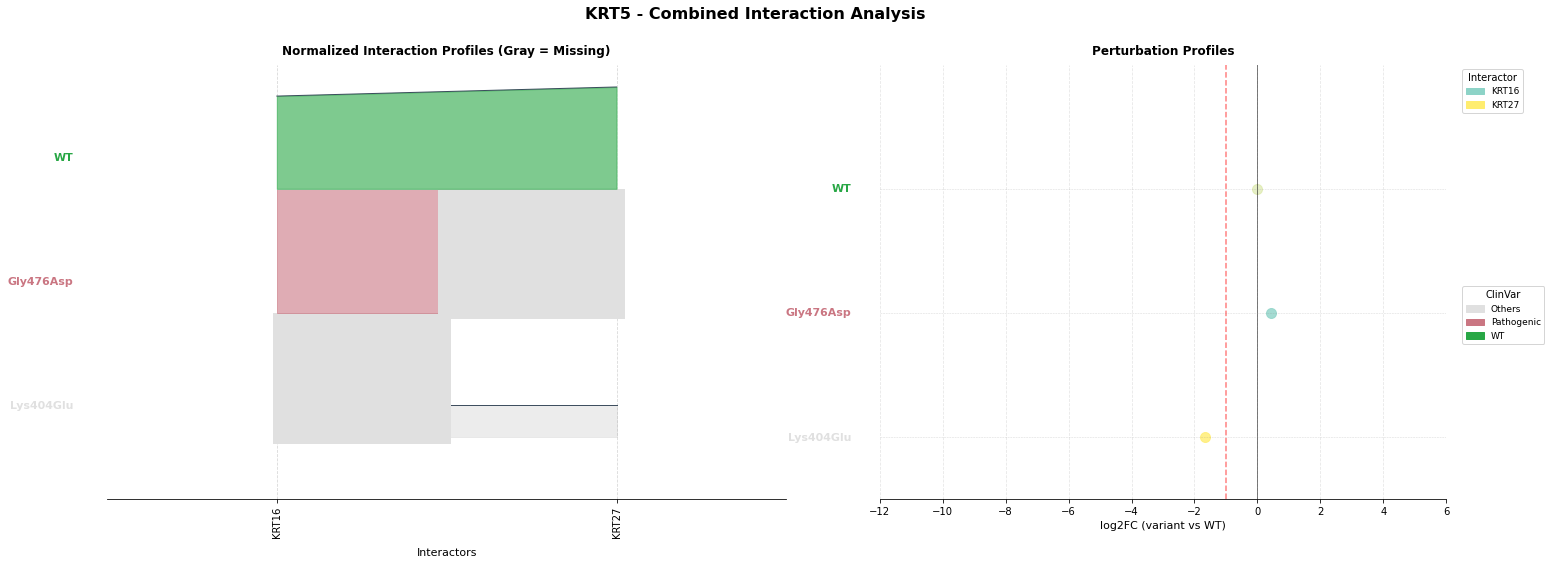


Processing: KRT6A
Plotting KRT6A: 14 variants, 4 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/KRT6A_combined.pdf


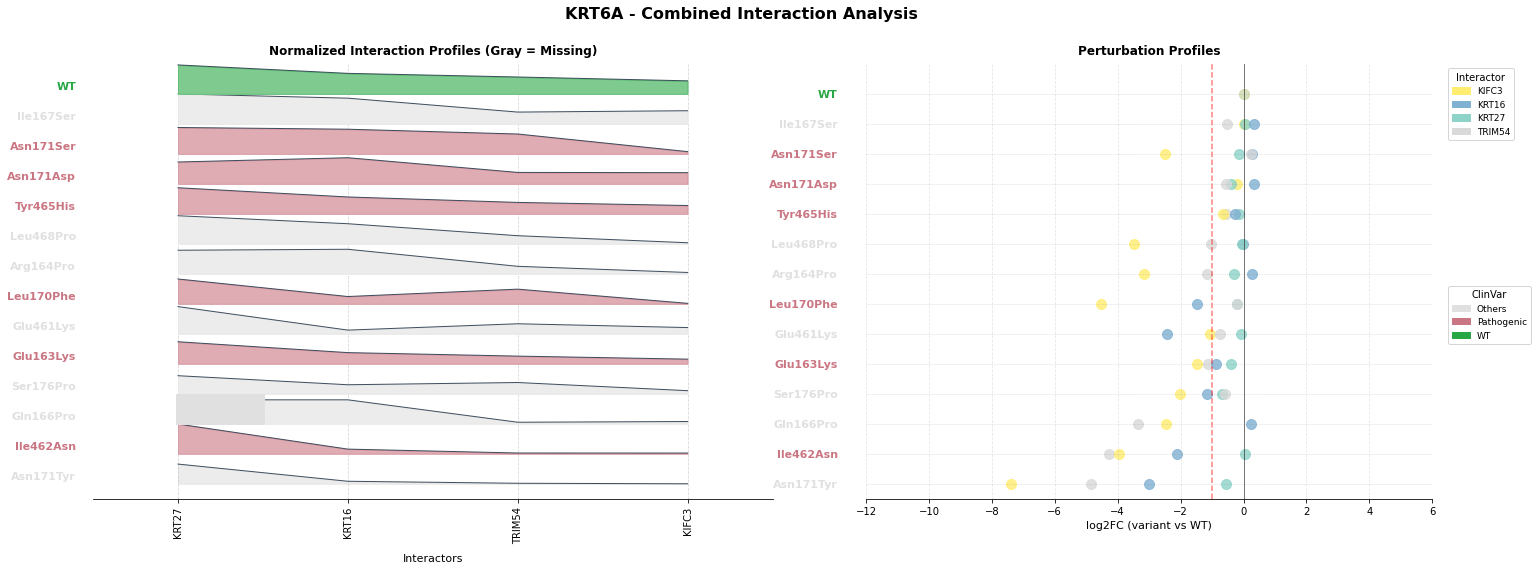


Processing: KRT8
Plotting KRT8: 4 variants, 4 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/KRT8_combined.pdf


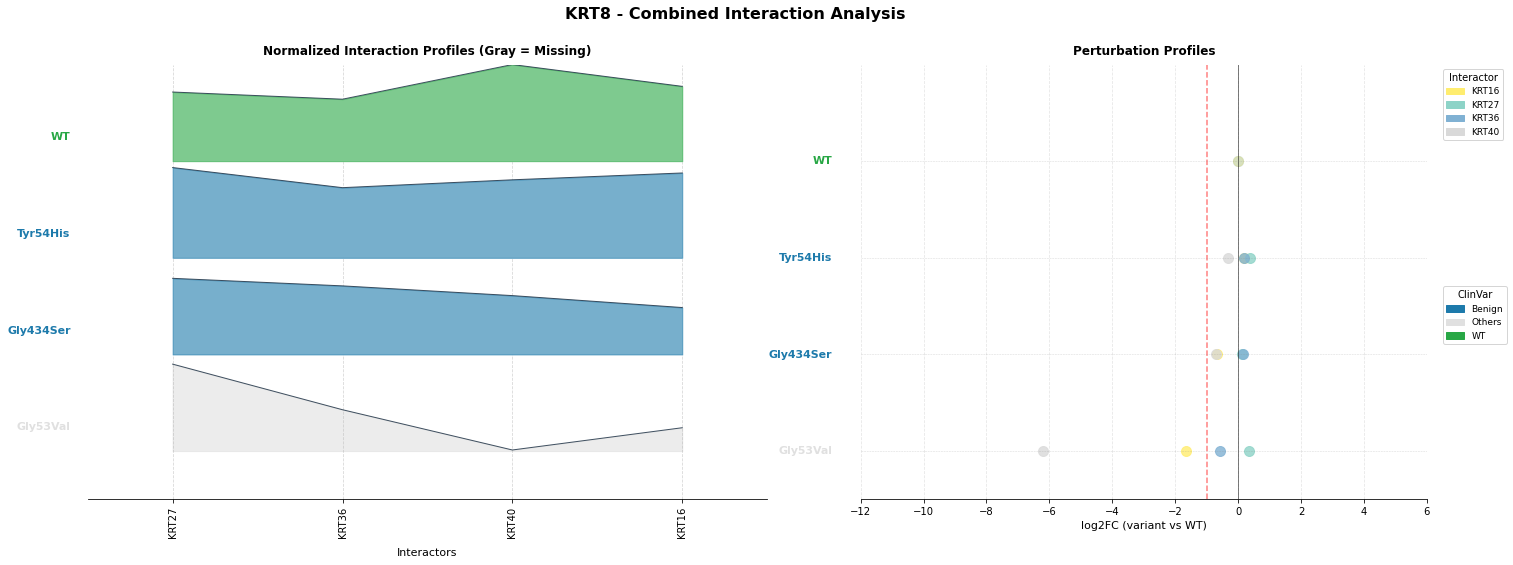


Processing: KRT86
Plotting KRT86: 3 variants, 7 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/KRT86_combined.pdf


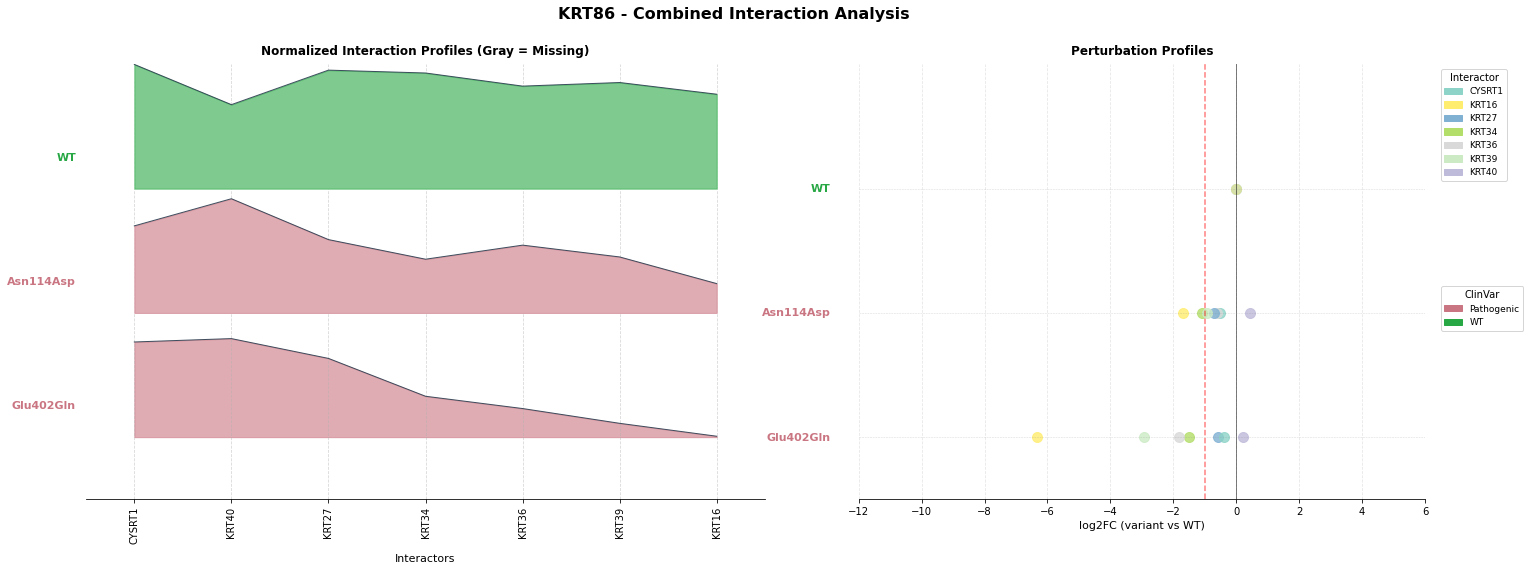


Processing: LDHB
Plotting LDHB: 2 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/LDHB_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


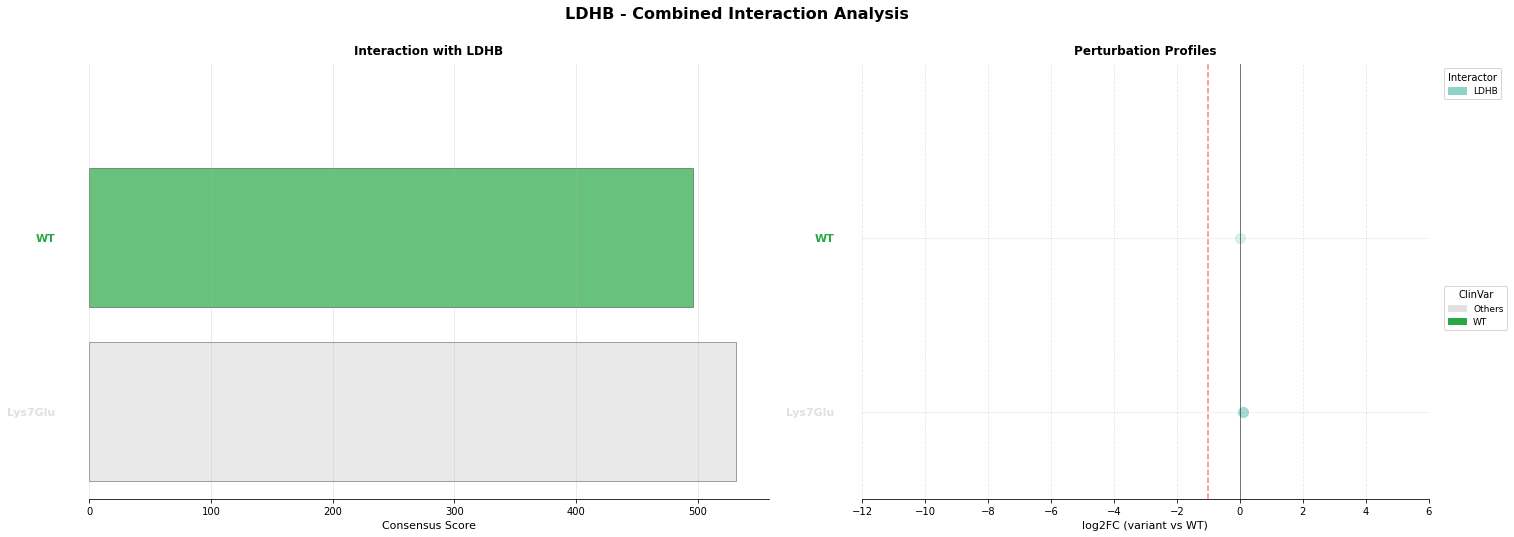


Processing: LITAF
Plotting LITAF: 23 variants, 15 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/LITAF_combined.pdf


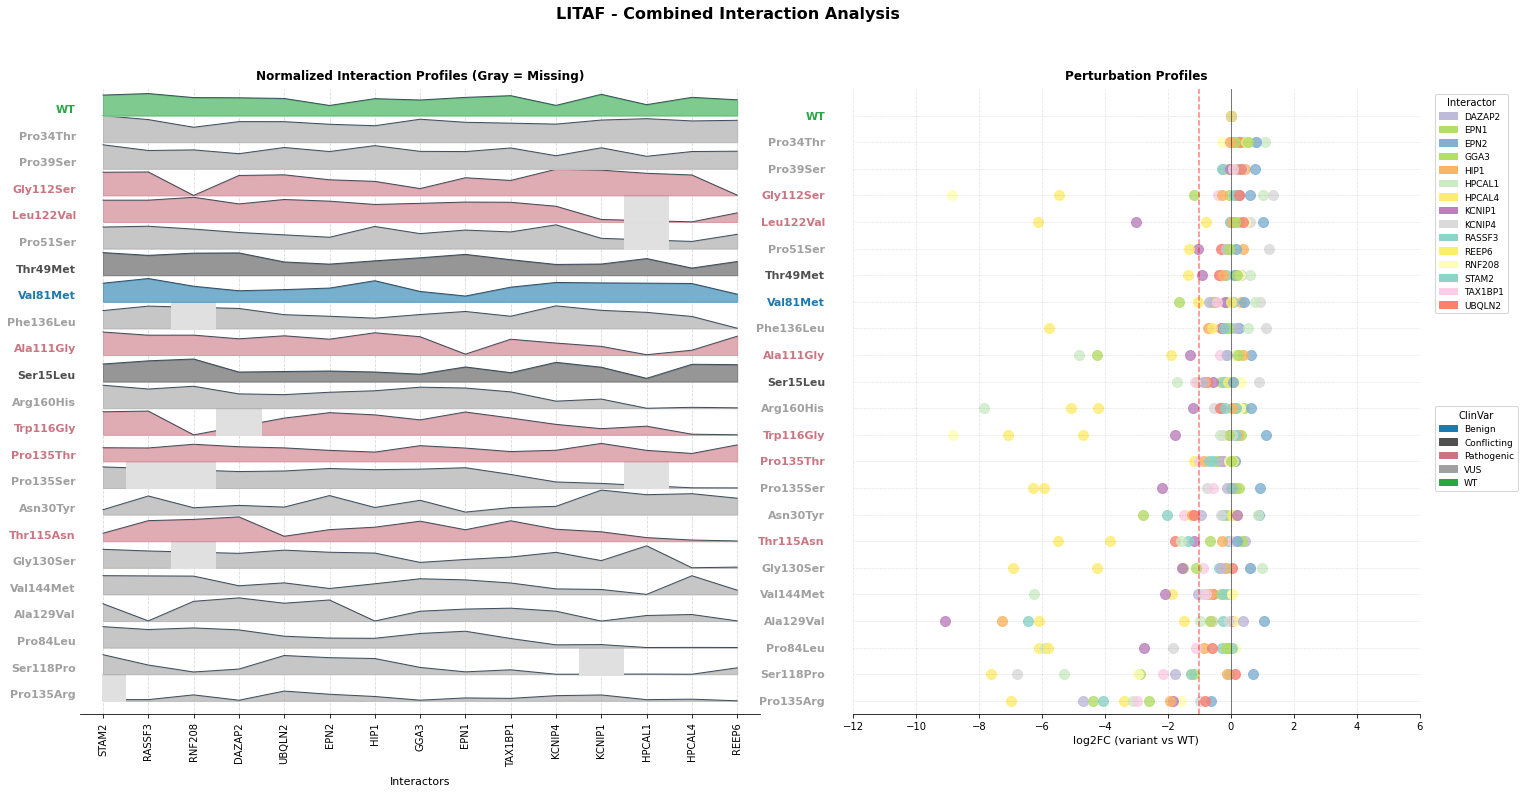


Processing: MLH1
Plotting MLH1: 13 variants, 16 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/MLH1_combined.pdf


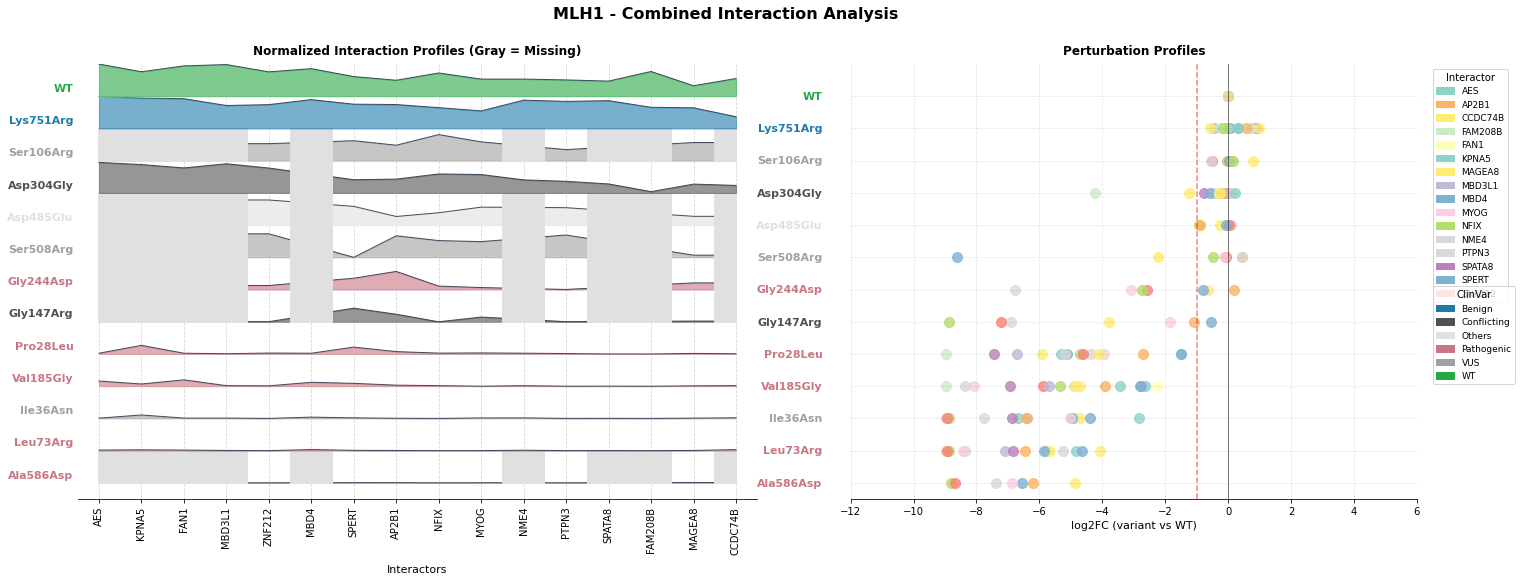


Processing: MVK
Plotting MVK: 11 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/MVK_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


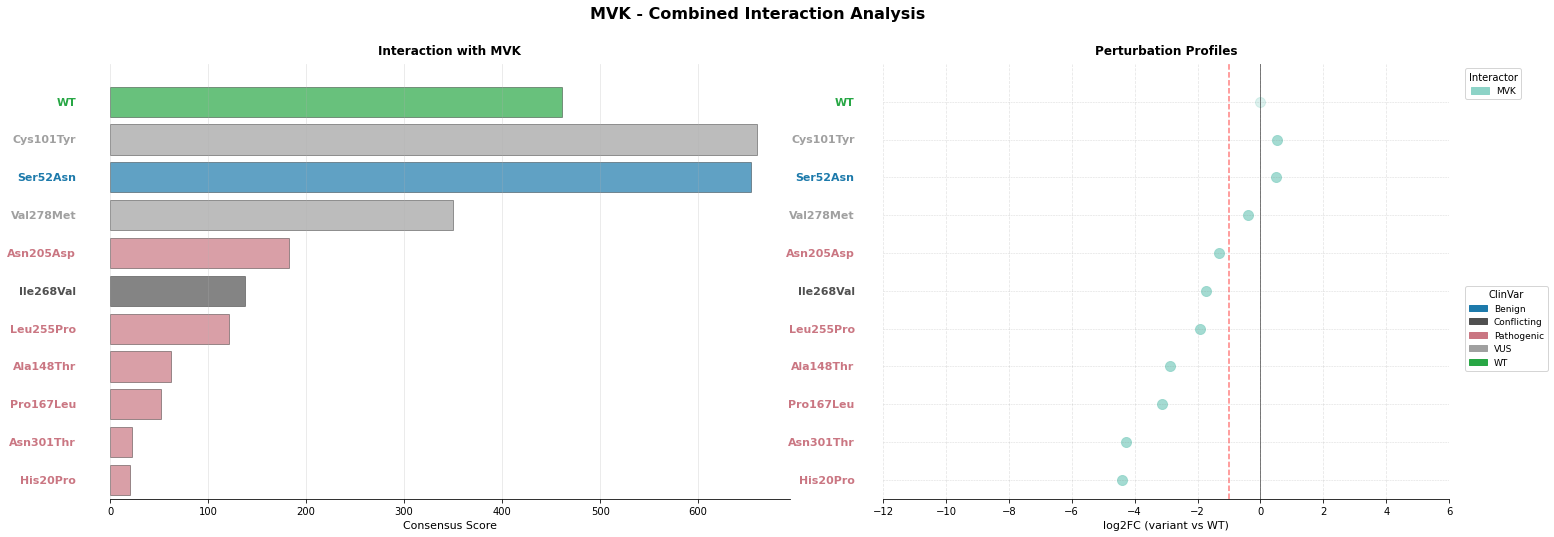


Processing: NAA10
Plotting NAA10: 2 variants, 9 interactors
Saved: ../3_outputs/sqY2H/combined_plots/NAA10_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


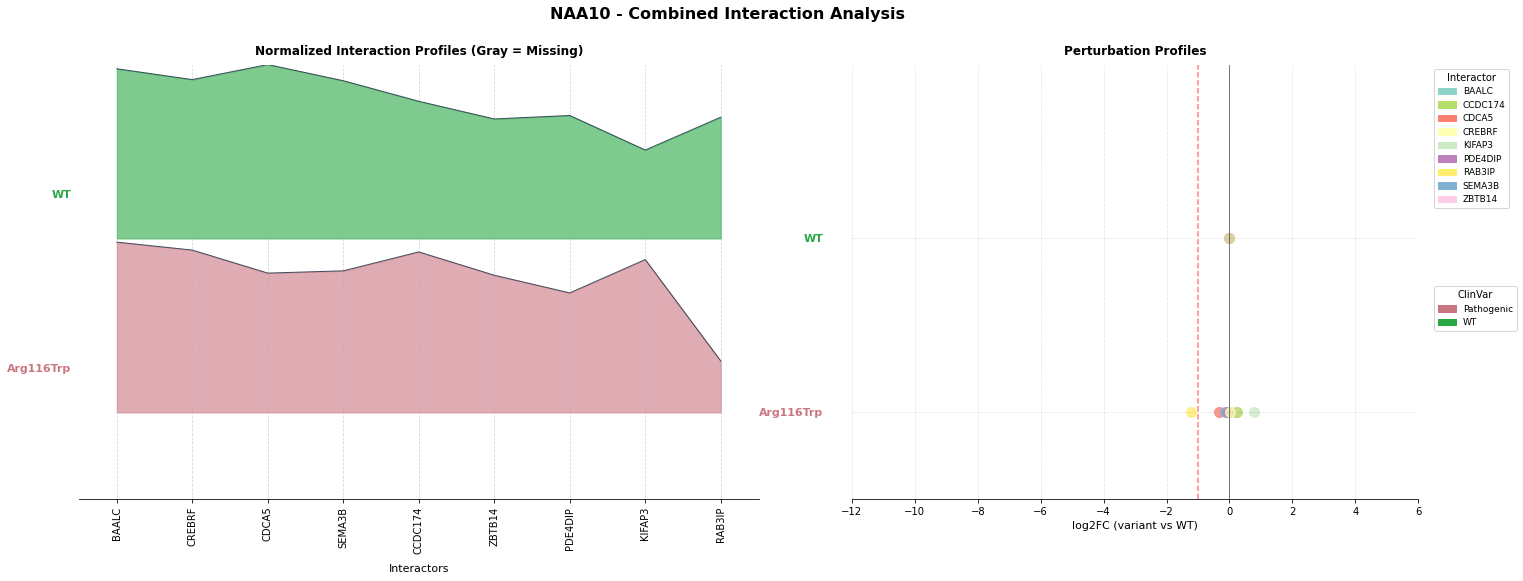


Processing: NCF2
Plotting NCF2: 5 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/NCF2_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


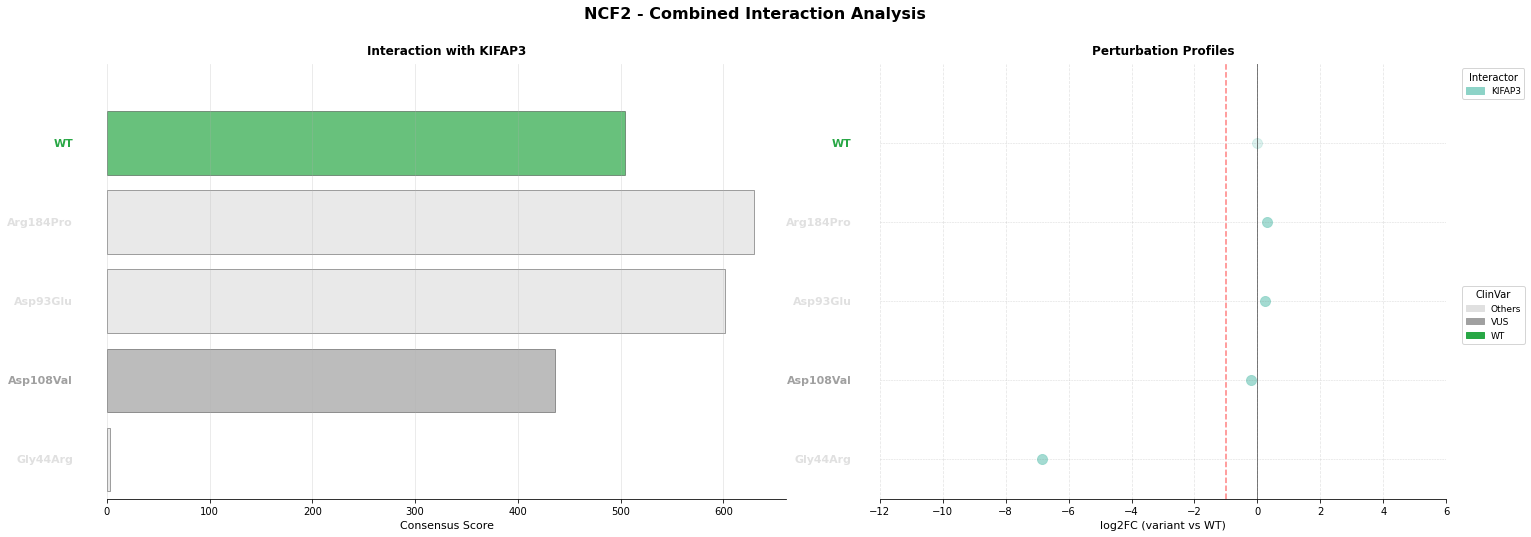


Processing: NEUROG3
Plotting NEUROG3: 2 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/NEUROG3_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


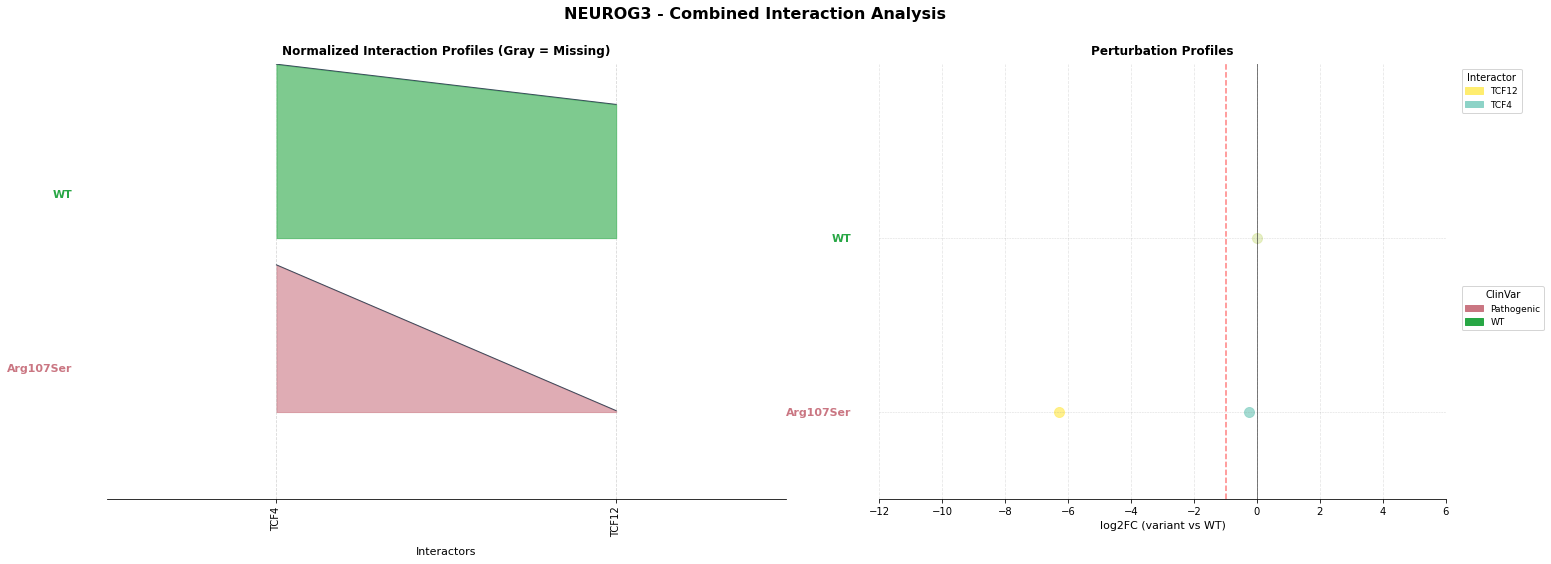


Processing: NMNAT1
Plotting NMNAT1: 6 variants, 3 interactors
Saved: ../3_outputs/sqY2H/combined_plots/NMNAT1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


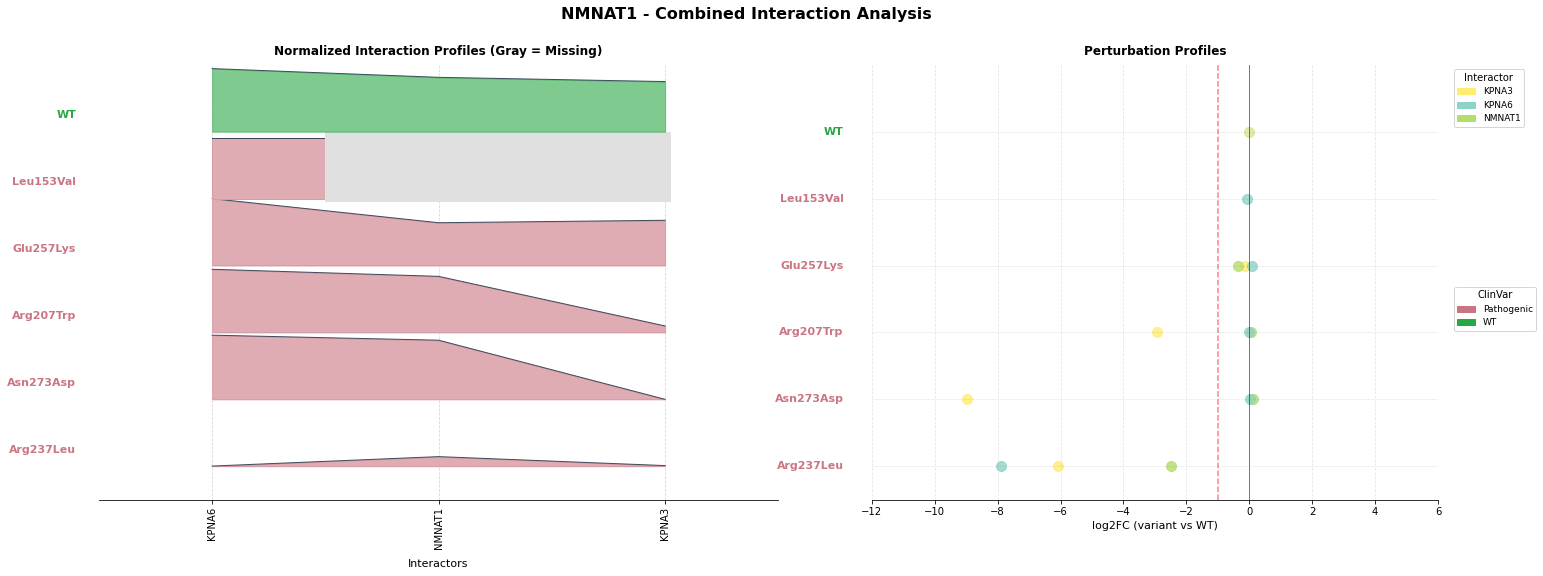


Processing: NR0B1
Plotting NR0B1: 2 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/NR0B1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


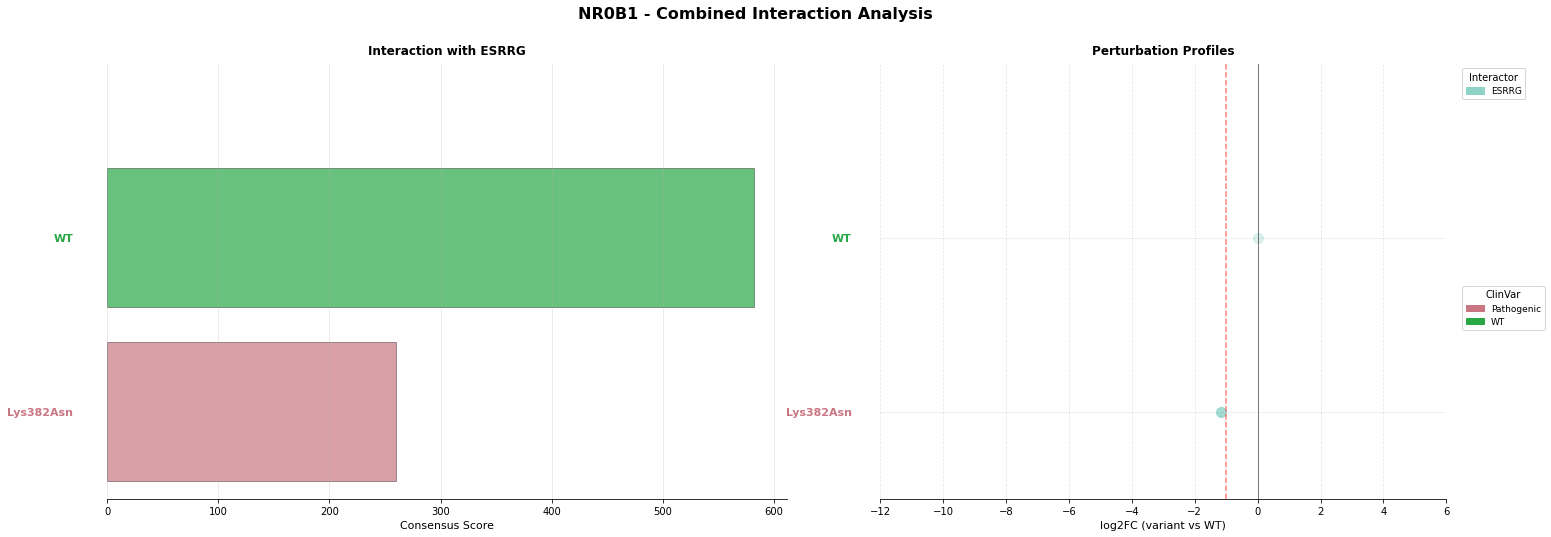


Processing: PCCA
Plotting PCCA: 3 variants, 1 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/PCCA_combined.pdf


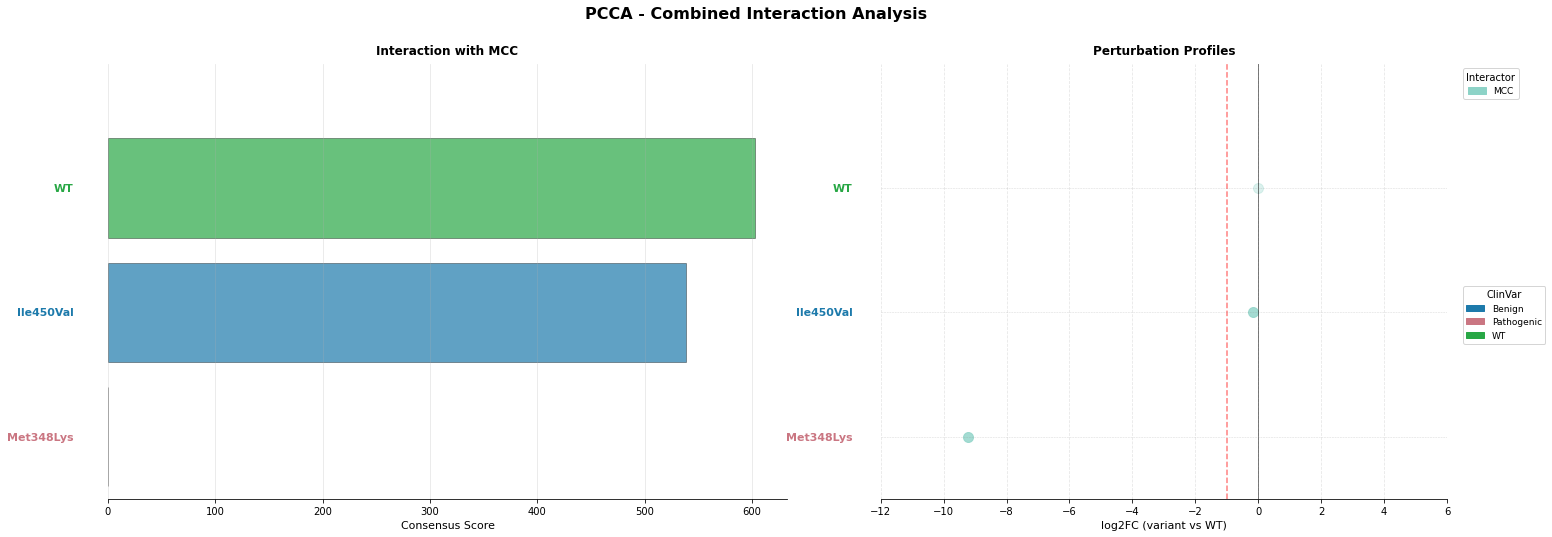


Processing: PITX2
Plotting PITX2: 6 variants, 3 interactors
Saved: ../3_outputs/sqY2H/combined_plots/PITX2_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


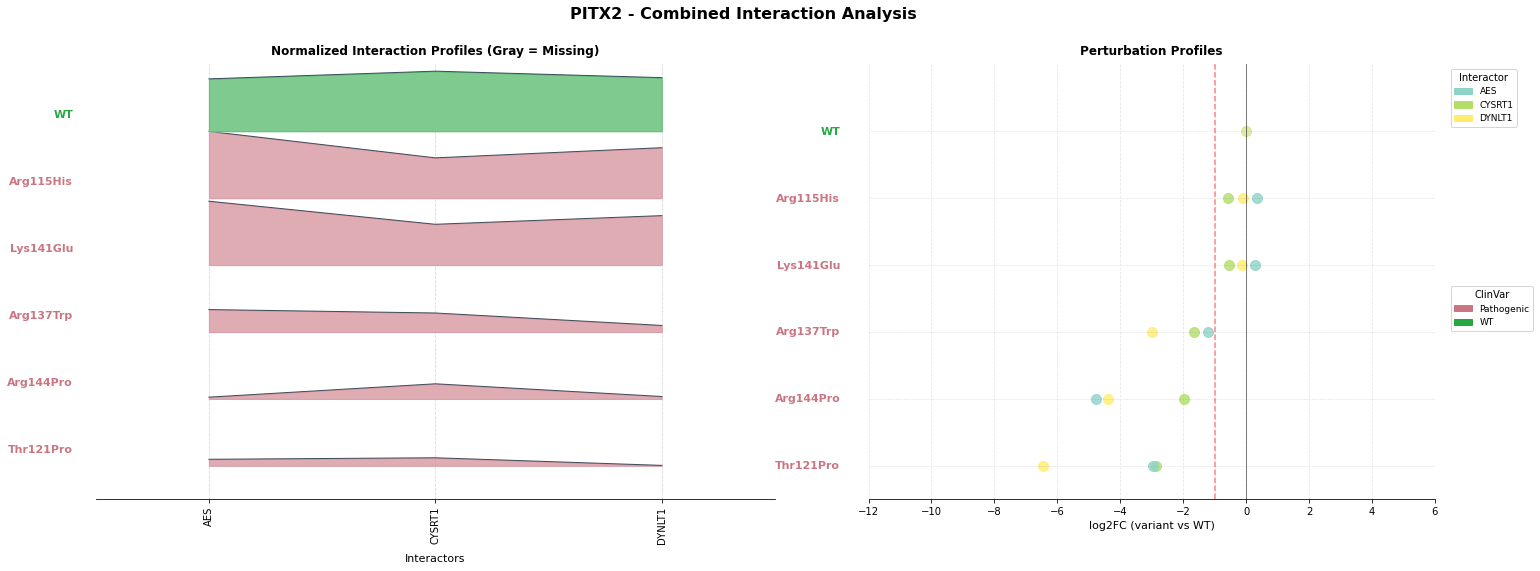


Processing: PKP2
Plotting PKP2: 13 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/PKP2_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


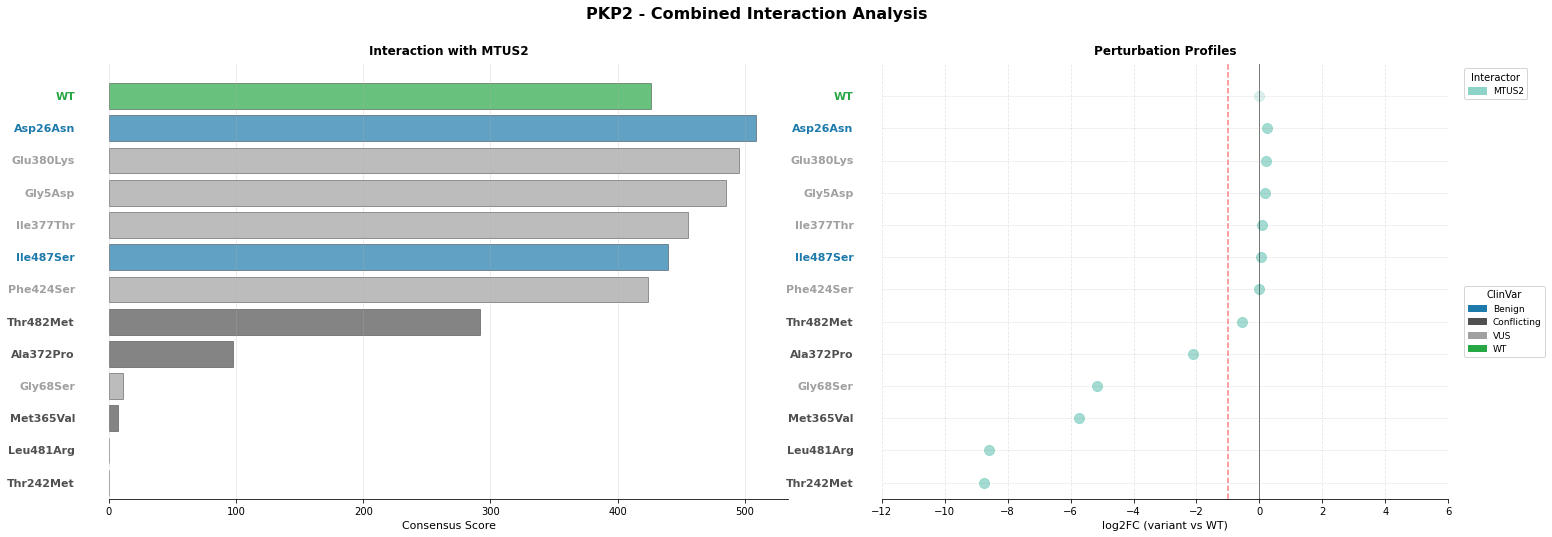


Processing: PLP1
Plotting PLP1: 12 variants, 16 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/PLP1_combined.pdf


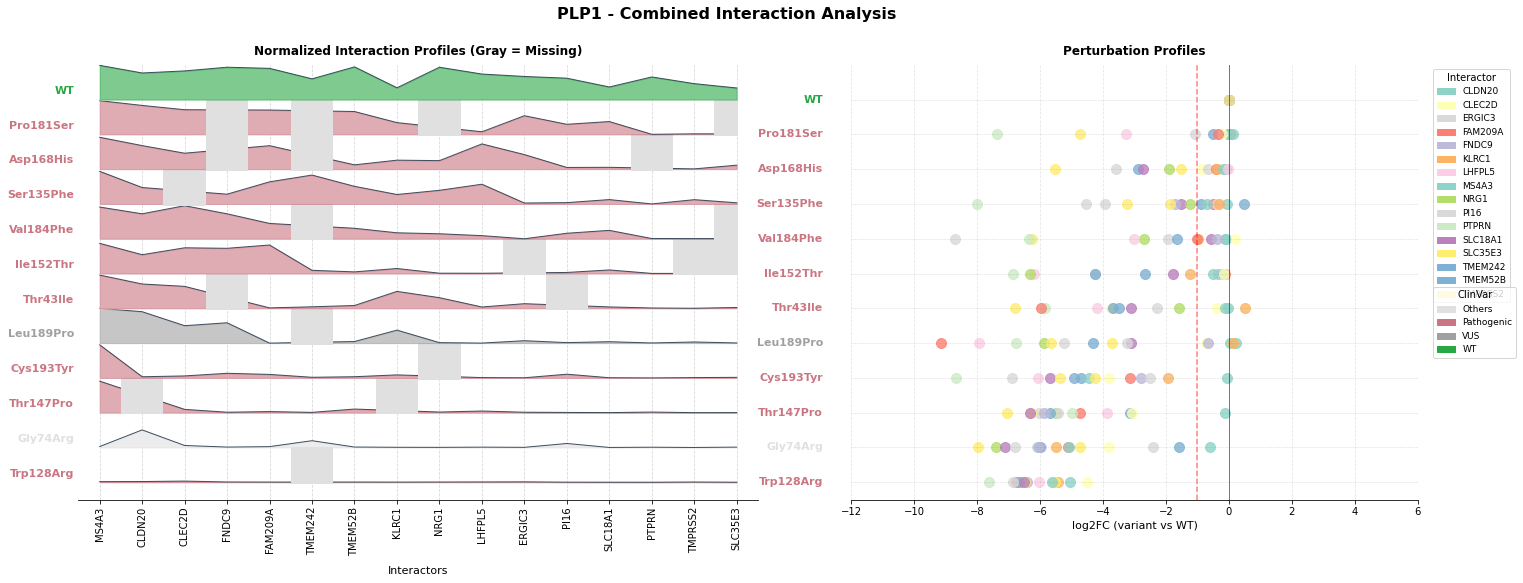


Processing: PMP22
Plotting PMP22: 4 variants, 7 interactors
Saved: ../3_outputs/sqY2H/combined_plots/PMP22_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


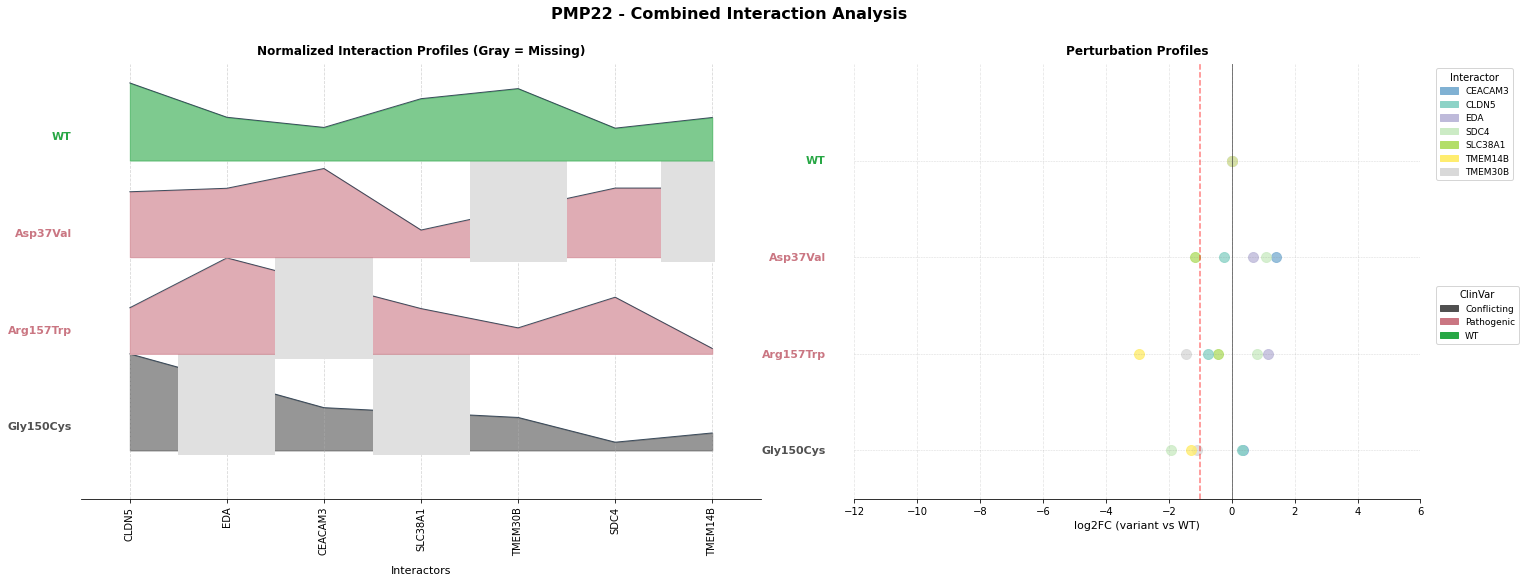


Processing: PNKP
Plotting PNKP: 2 variants, 11 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/PNKP_combined.pdf


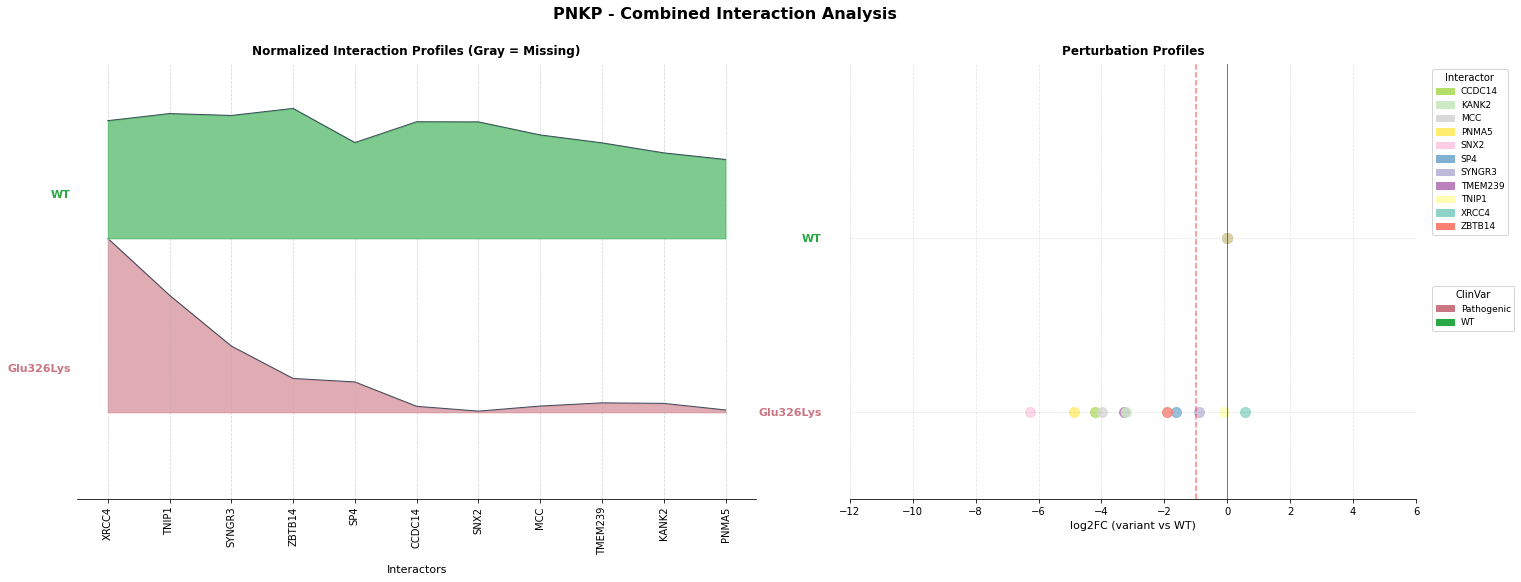


Processing: PRKAR1A
Plotting PRKAR1A: 3 variants, 5 interactors
Saved: ../3_outputs/sqY2H/combined_plots/PRKAR1A_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


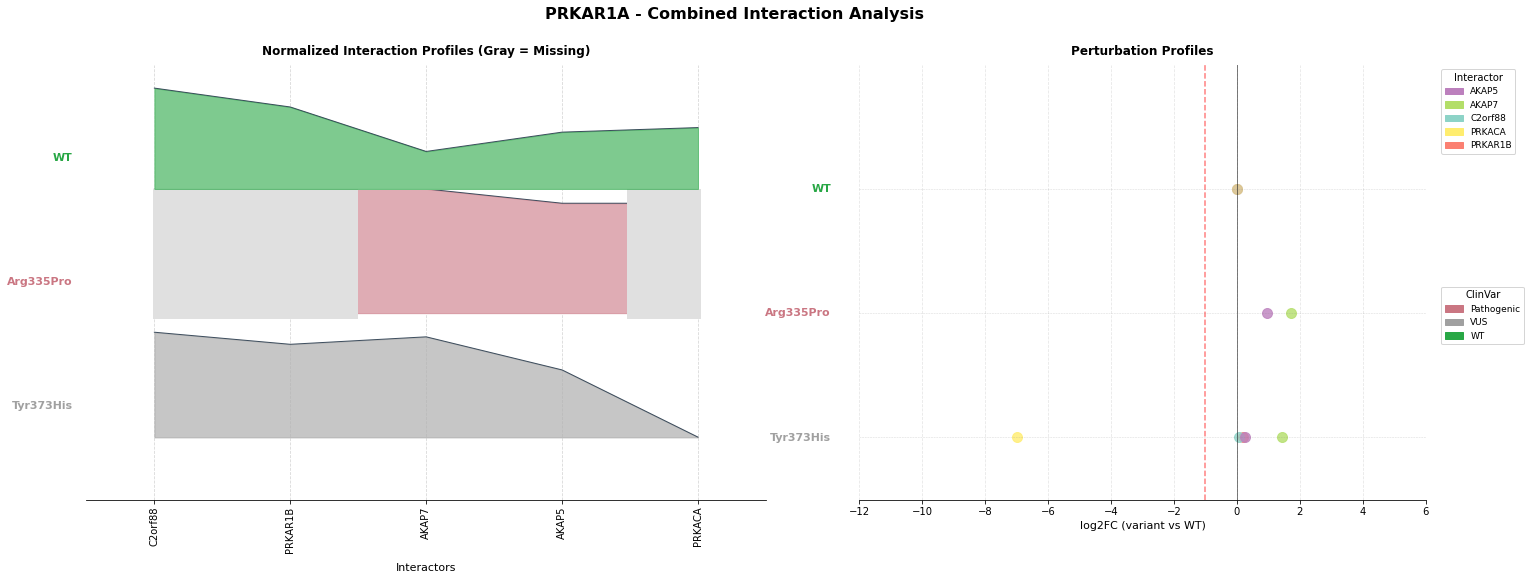


Processing: PRPS1
Plotting PRPS1: 2 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/PRPS1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


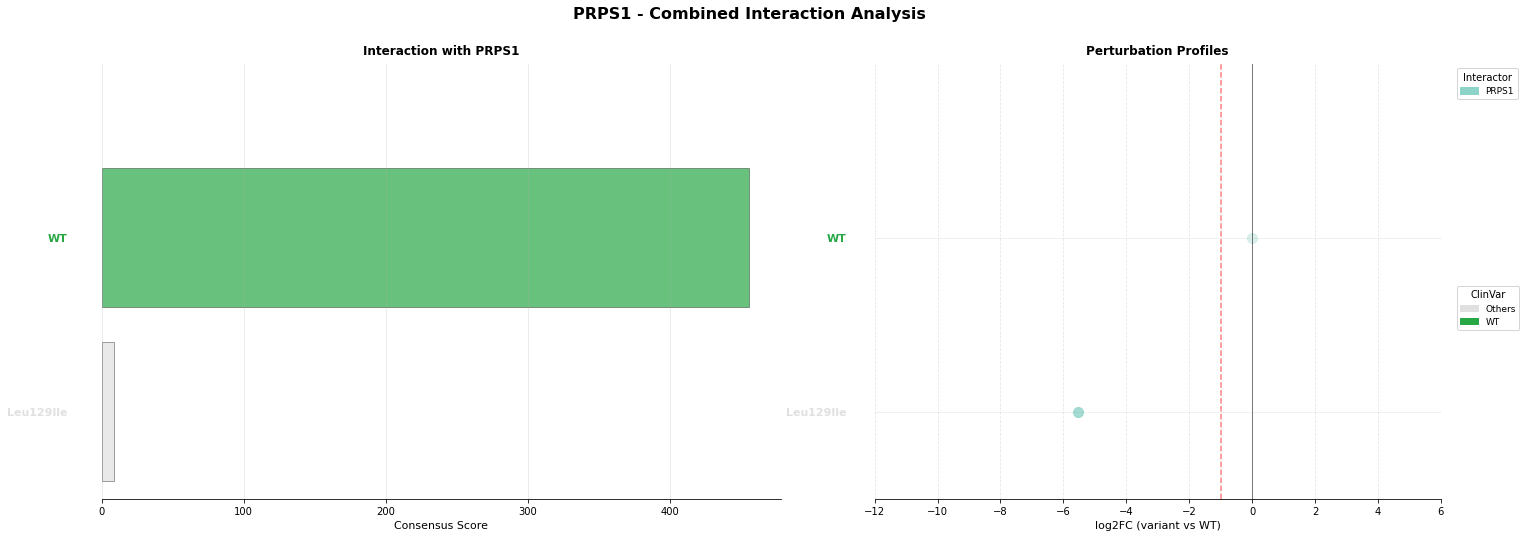


Processing: PTS
Plotting PTS: 3 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/PTS_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


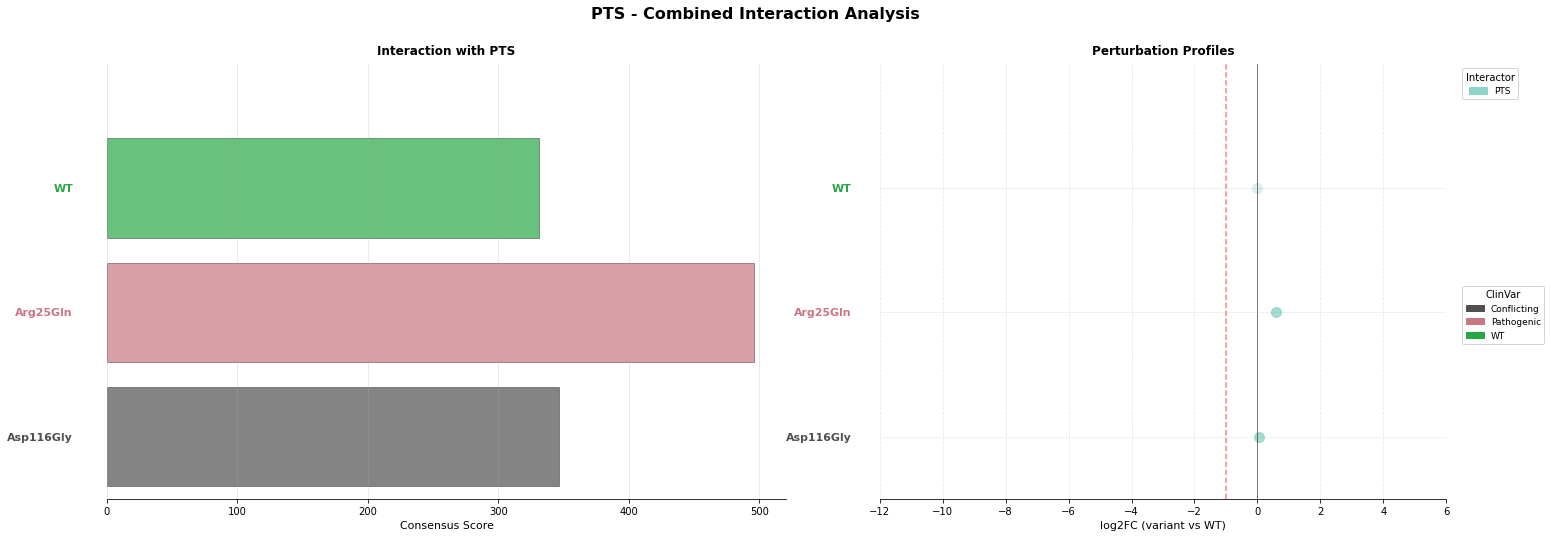


Processing: PYGL
Plotting PYGL: 6 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/PYGL_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


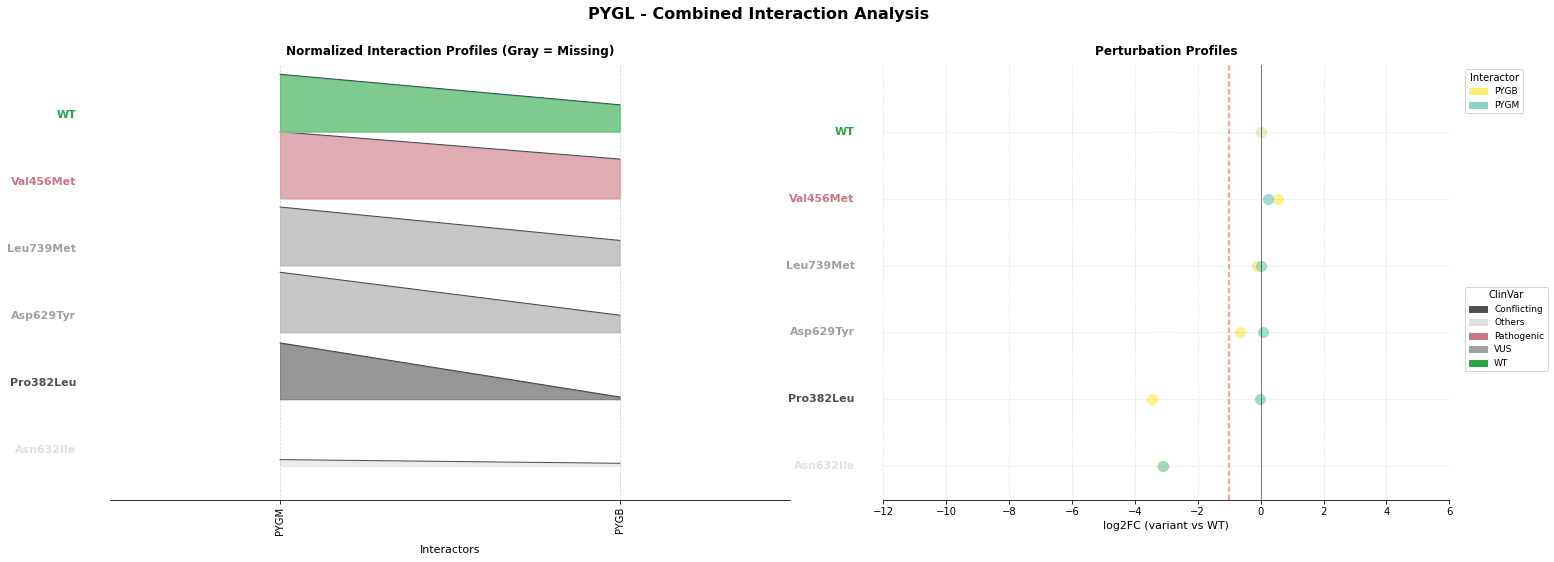


Processing: SFTPC
Plotting SFTPC: 6 variants, 4 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/SFTPC_combined.pdf


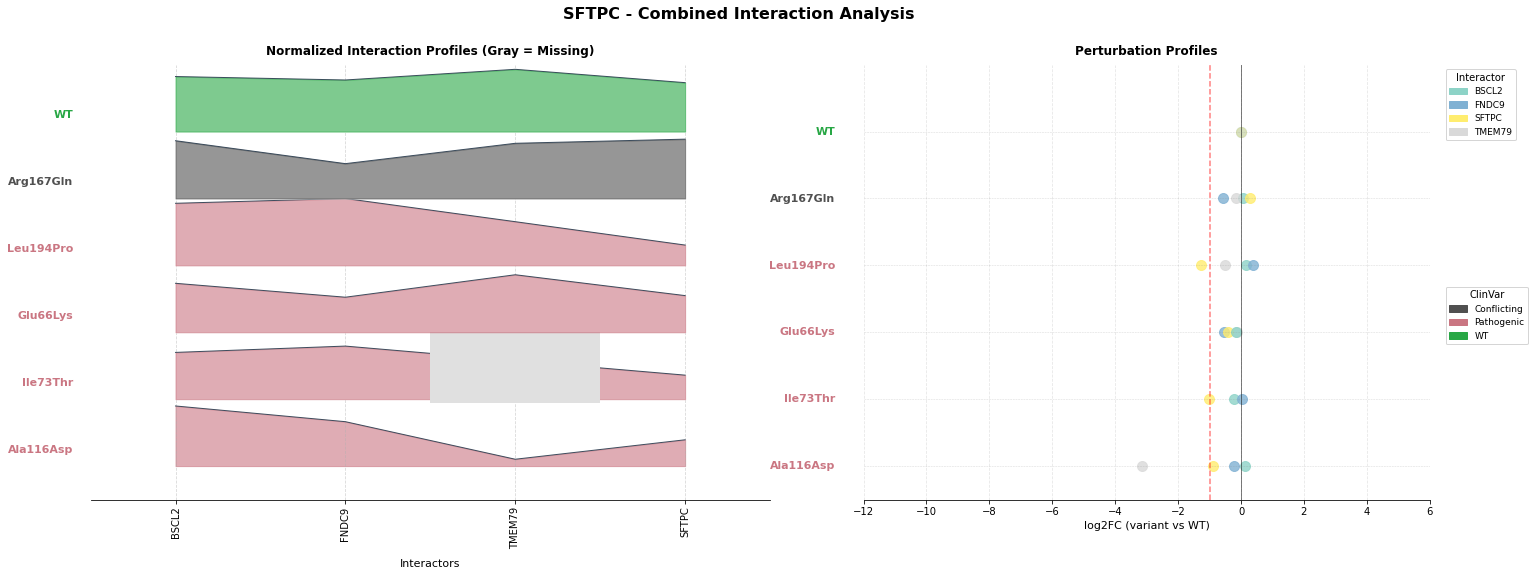


Processing: SH3BP2
Plotting SH3BP2: 5 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/SH3BP2_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


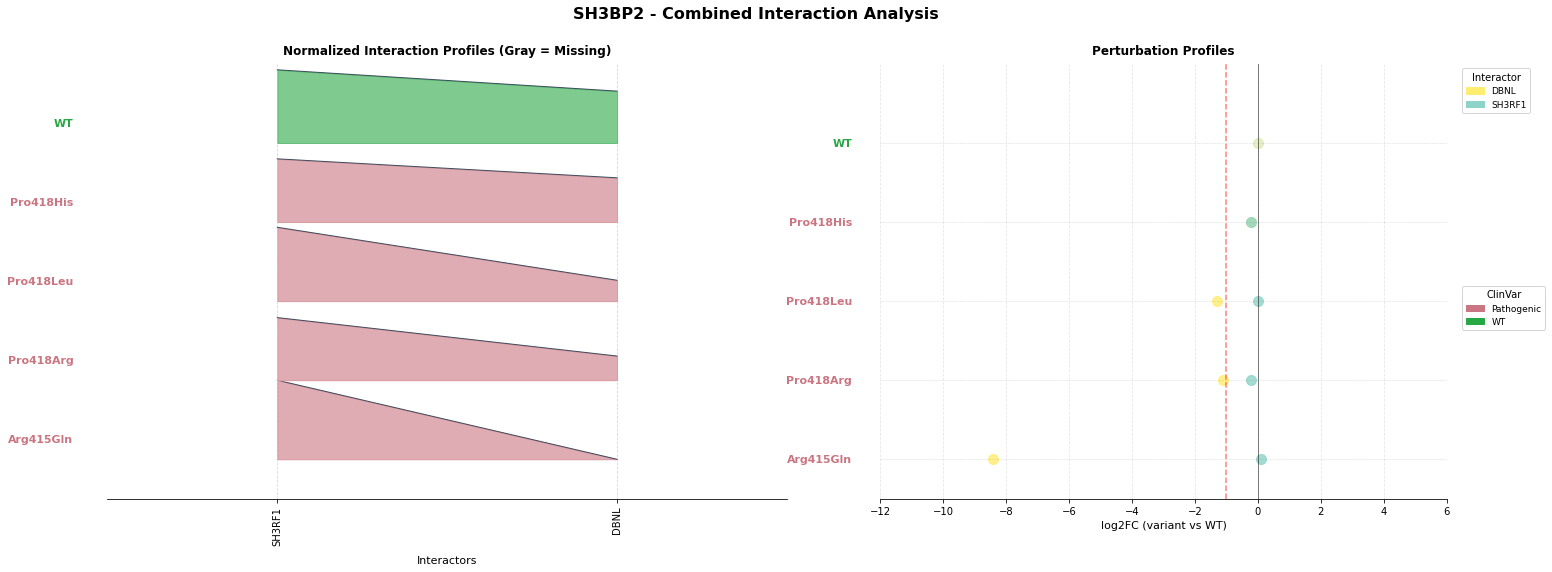


Processing: SIX1
Plotting SIX1: 2 variants, 3 interactors
Saved: ../3_outputs/sqY2H/combined_plots/SIX1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


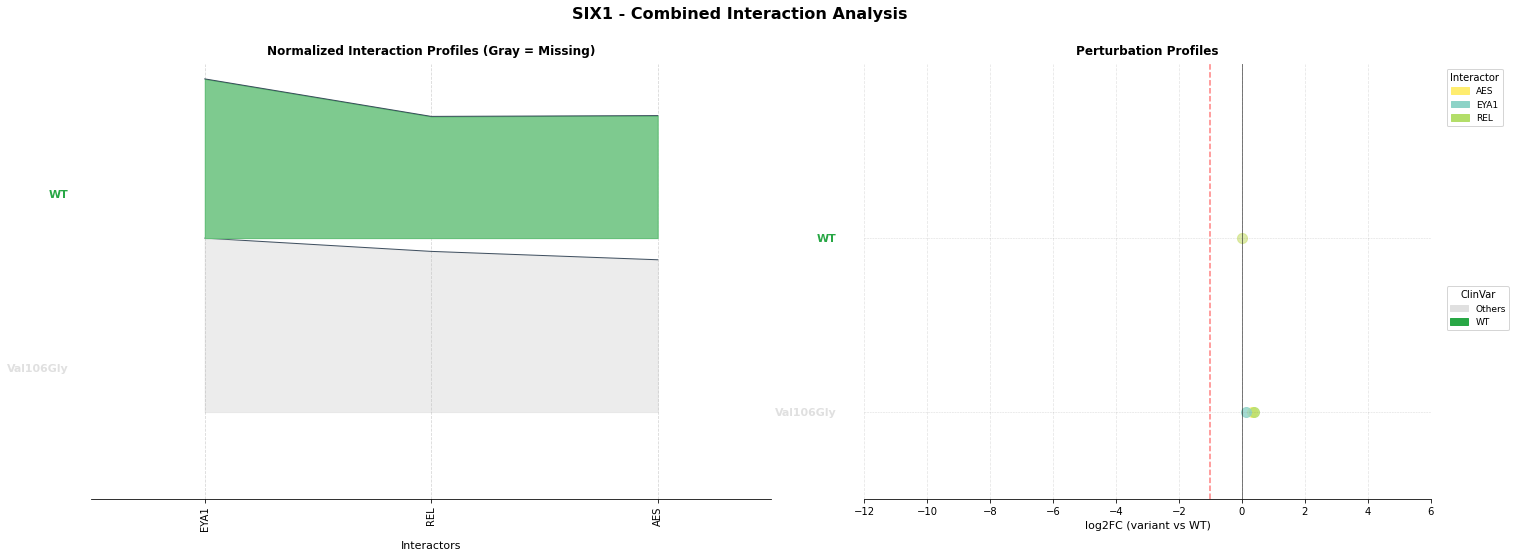


Processing: SMAD3
Plotting SMAD3: 23 variants, 2 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/SMAD3_combined.pdf


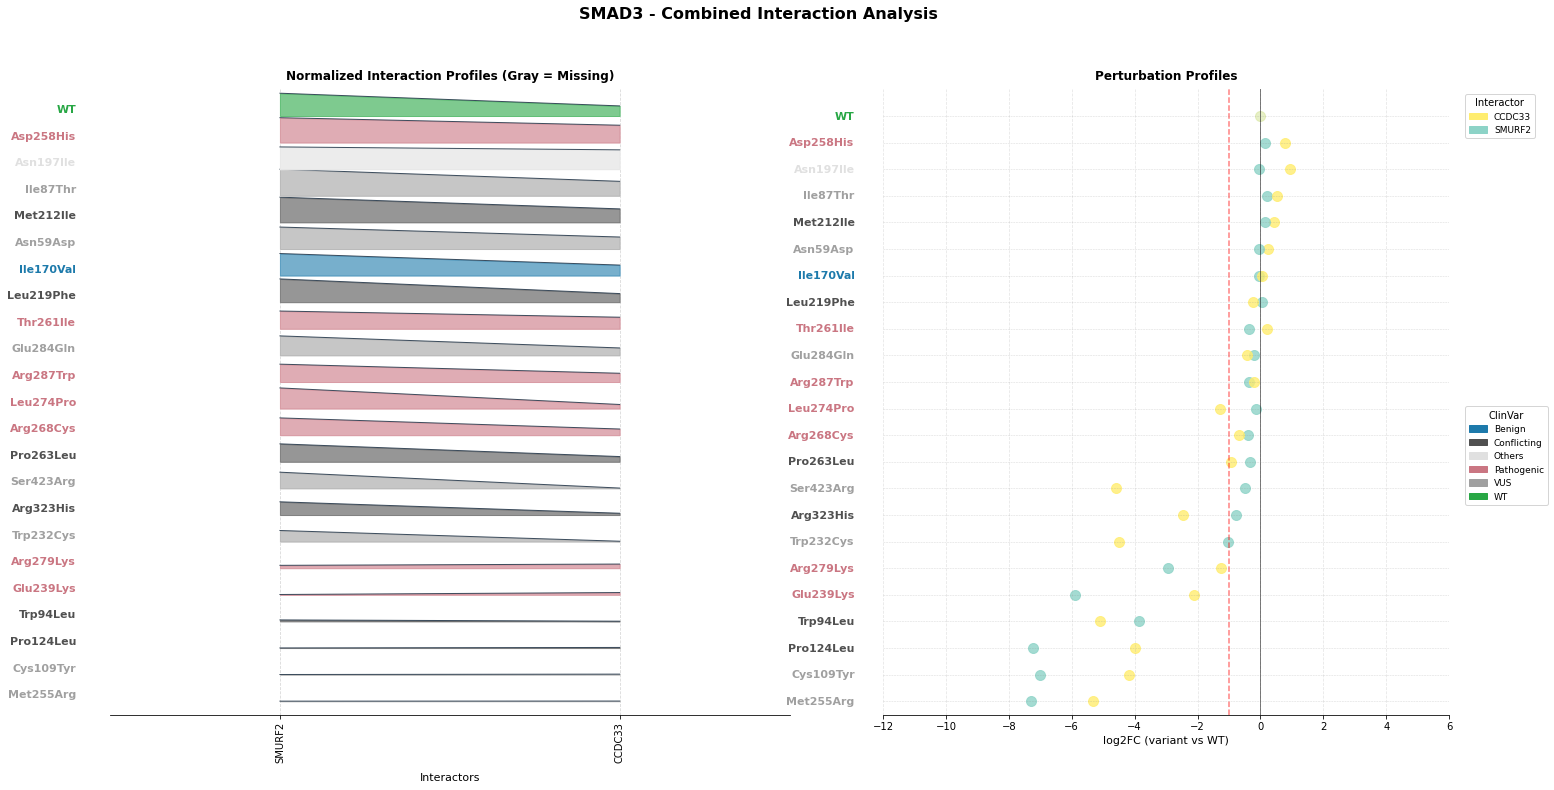


Processing: SMARCB1
Plotting SMARCB1: 3 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/SMARCB1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


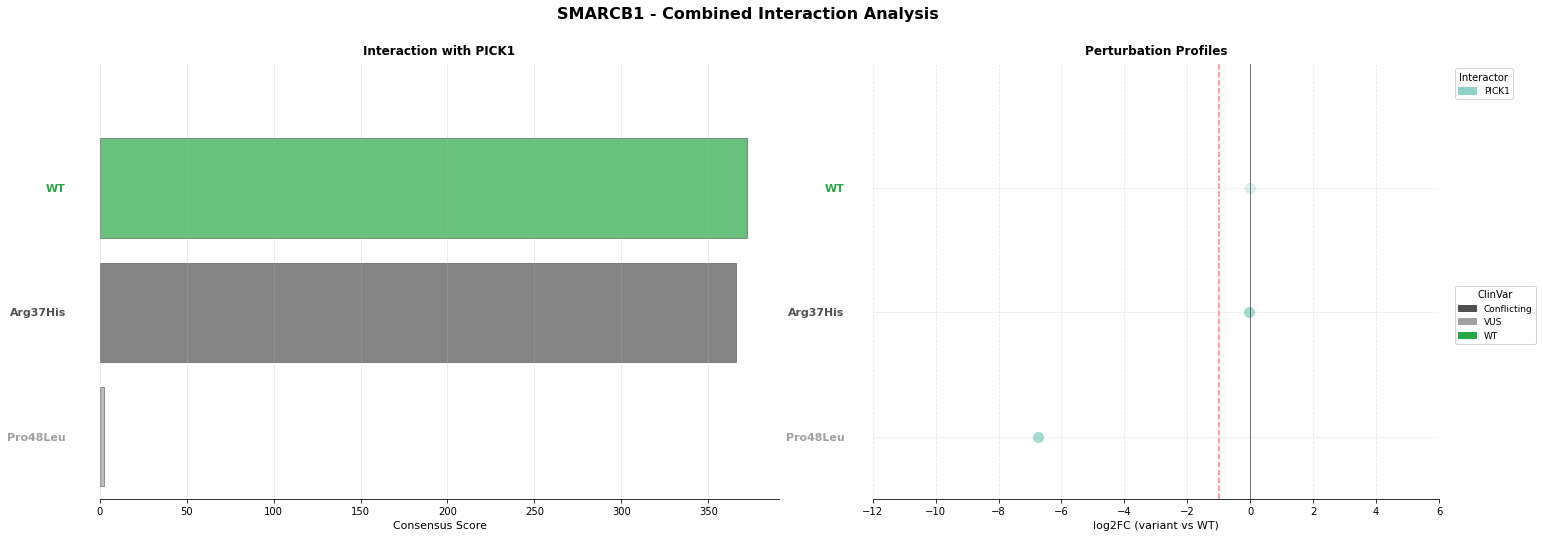


Processing: STAR
Plotting STAR: 5 variants, 2 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/STAR_combined.pdf


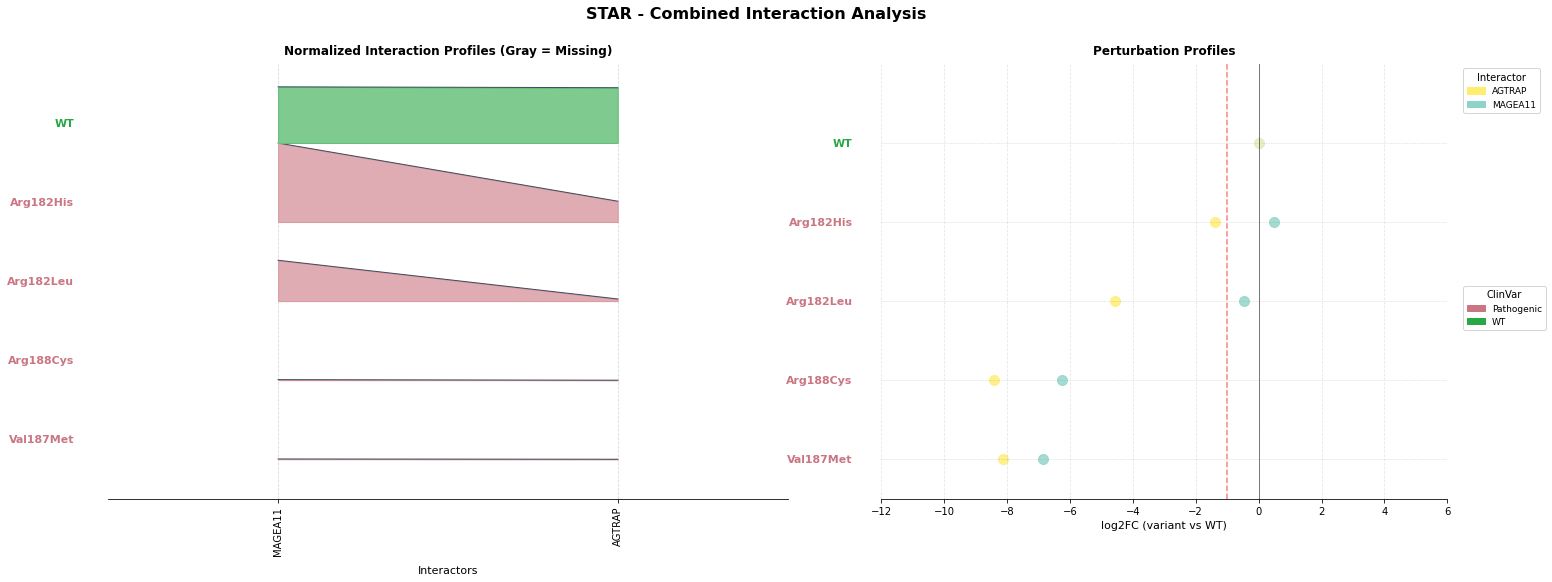


Processing: STXBP1
Plotting STXBP1: 32 variants, 5 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/STXBP1_combined.pdf


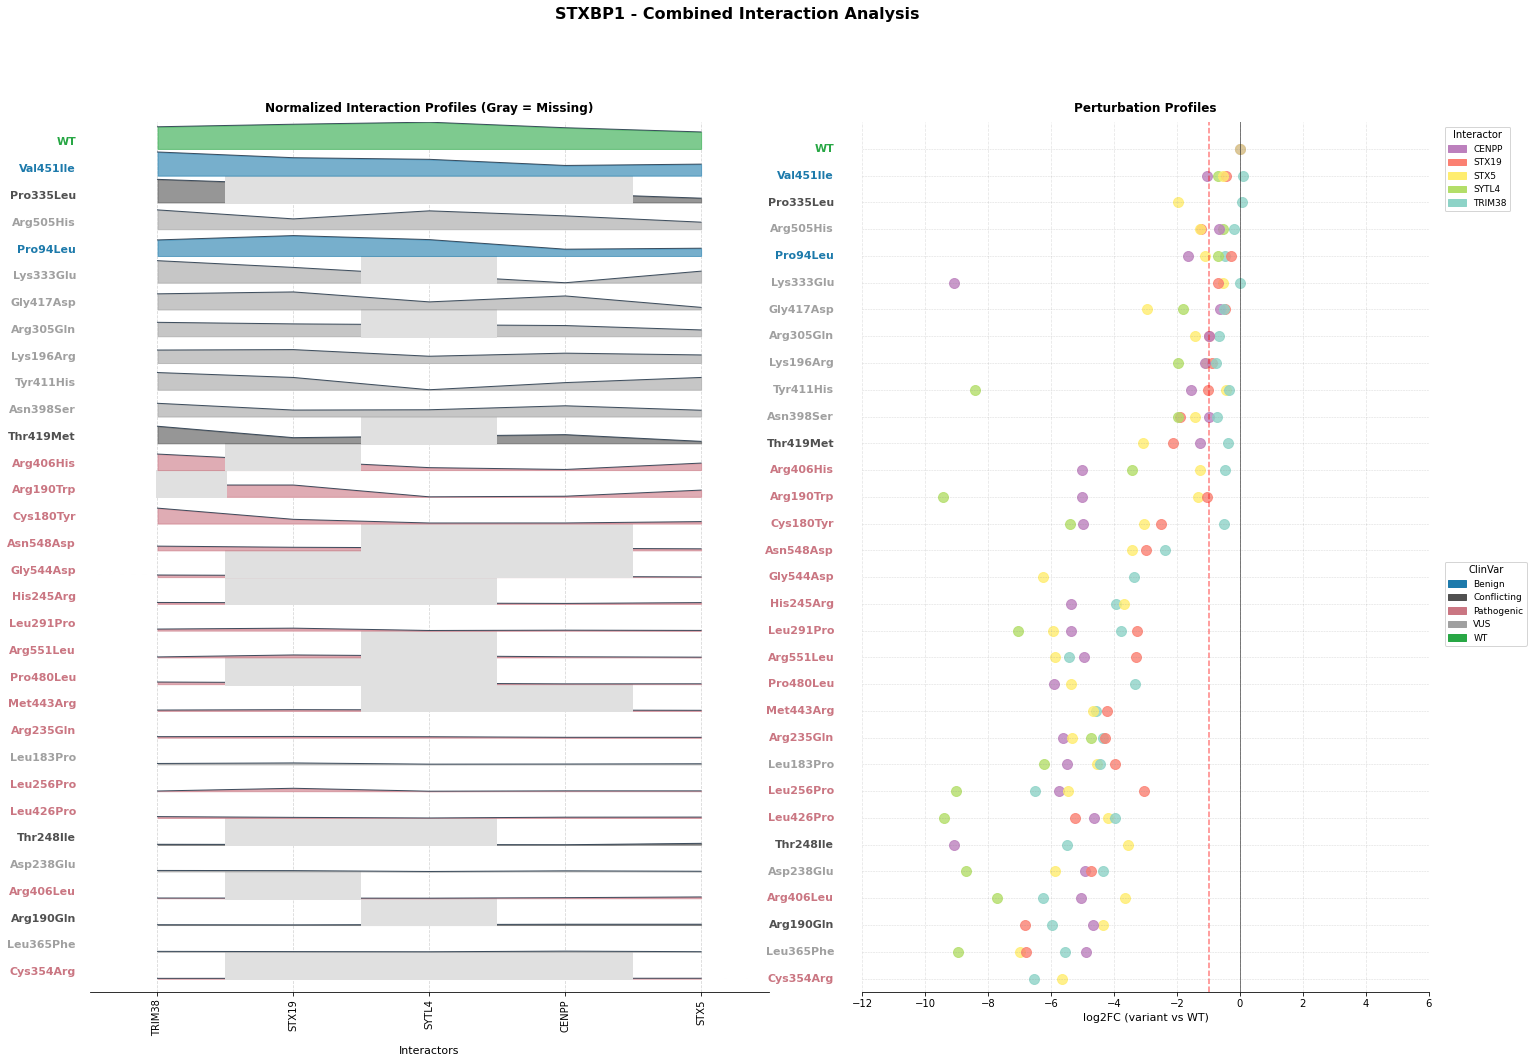


Processing: SUOX
Plotting SUOX: 3 variants, 22 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/SUOX_combined.pdf


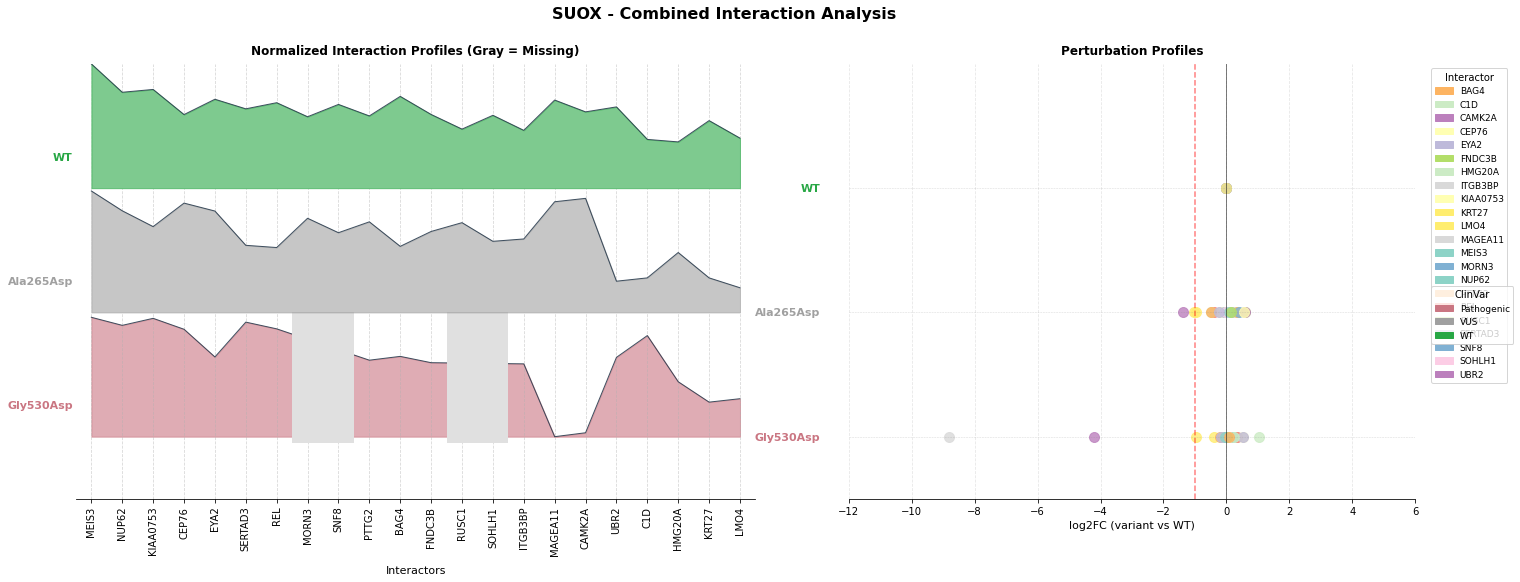


Processing: TH
Plotting TH: 13 variants, 2 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/TH_combined.pdf


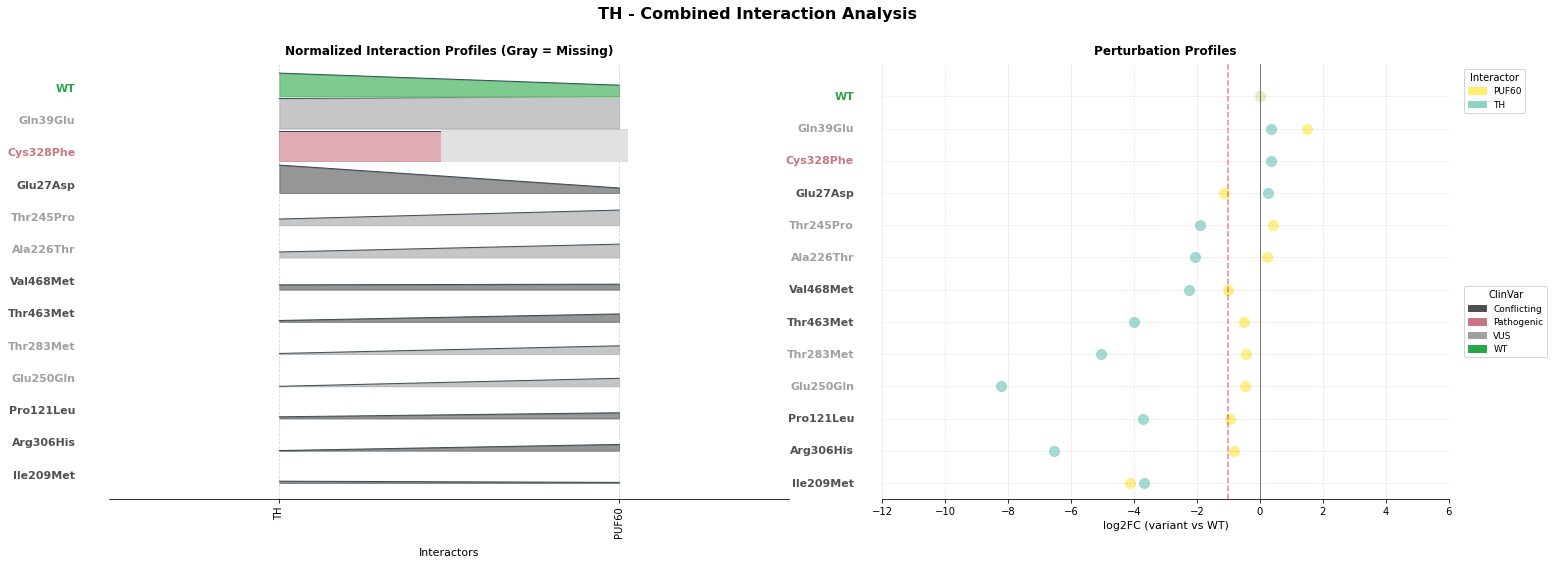


Processing: THAP1
Plotting THAP1: 3 variants, 2 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/THAP1_combined.pdf


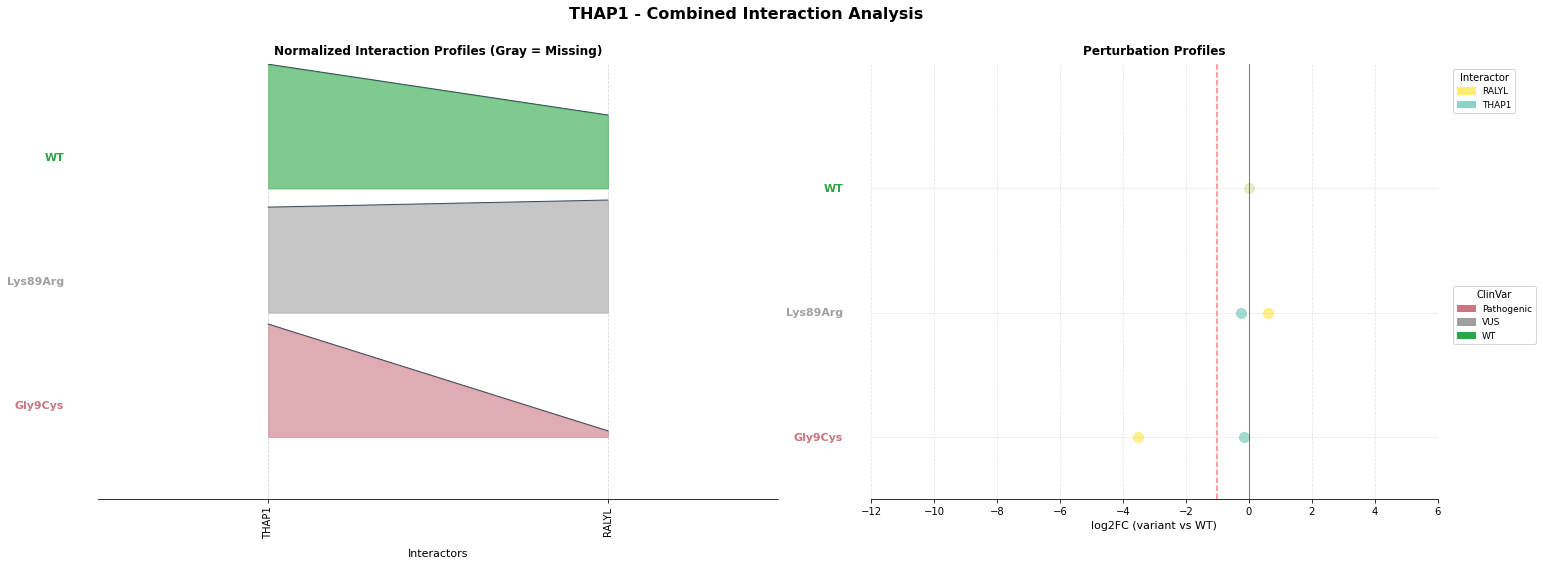


Processing: TMEM43
Plotting TMEM43: 6 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/TMEM43_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


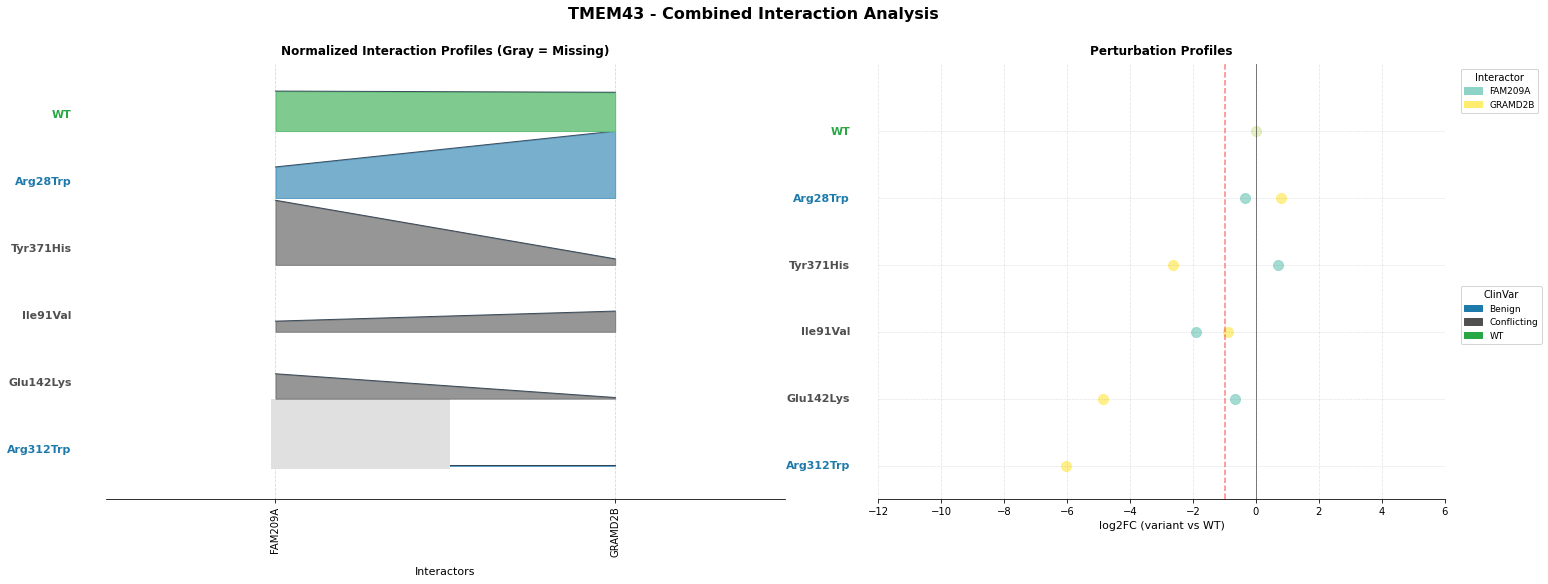


Processing: TPK1
Plotting TPK1: 2 variants, 1 interactors
Saved: ../3_outputs/sqY2H/combined_plots/TPK1_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


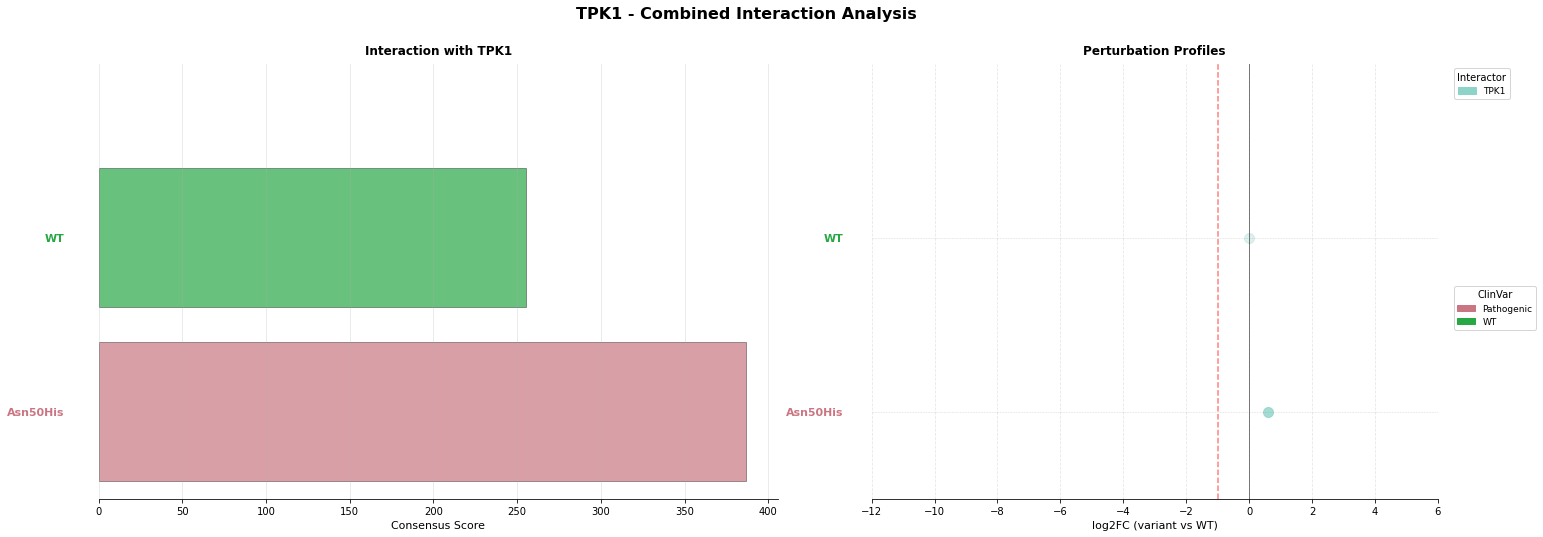


Processing: TPM1
Plotting TPM1: 23 variants, 2 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/TPM1_combined.pdf


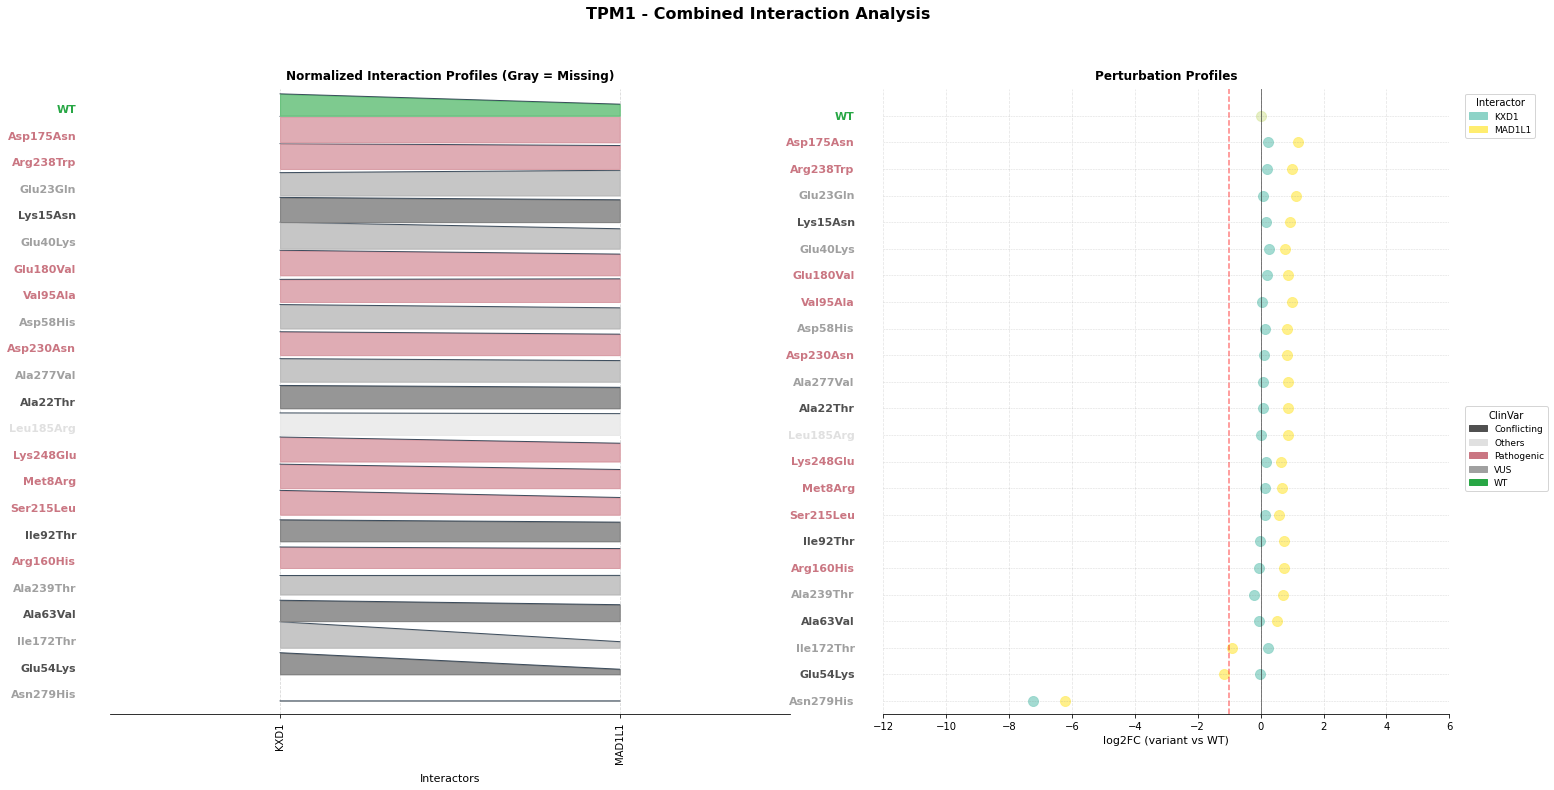


Processing: TTR
Plotting TTR: 21 variants, 1 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/TTR_combined.pdf


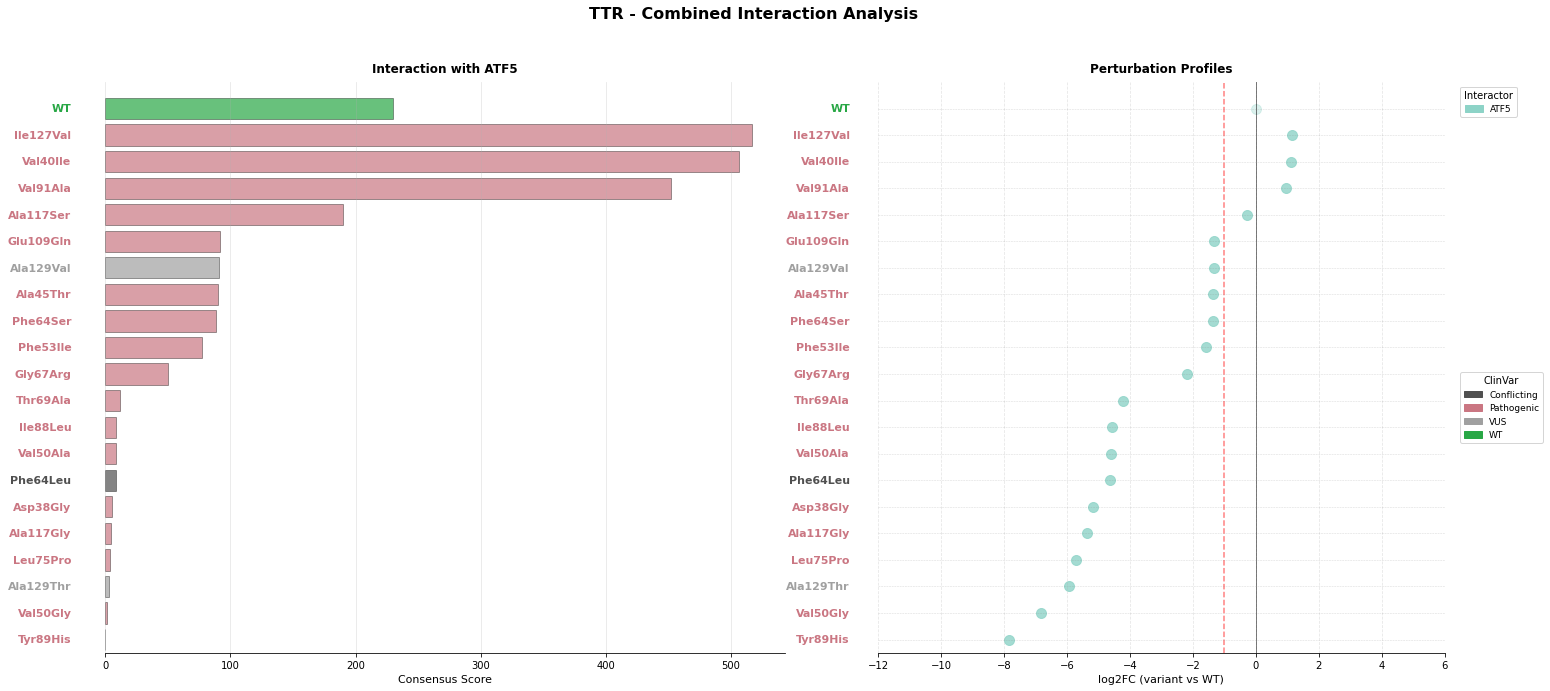


Processing: UBQLN2
Plotting UBQLN2: 6 variants, 32 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/UBQLN2_combined.pdf


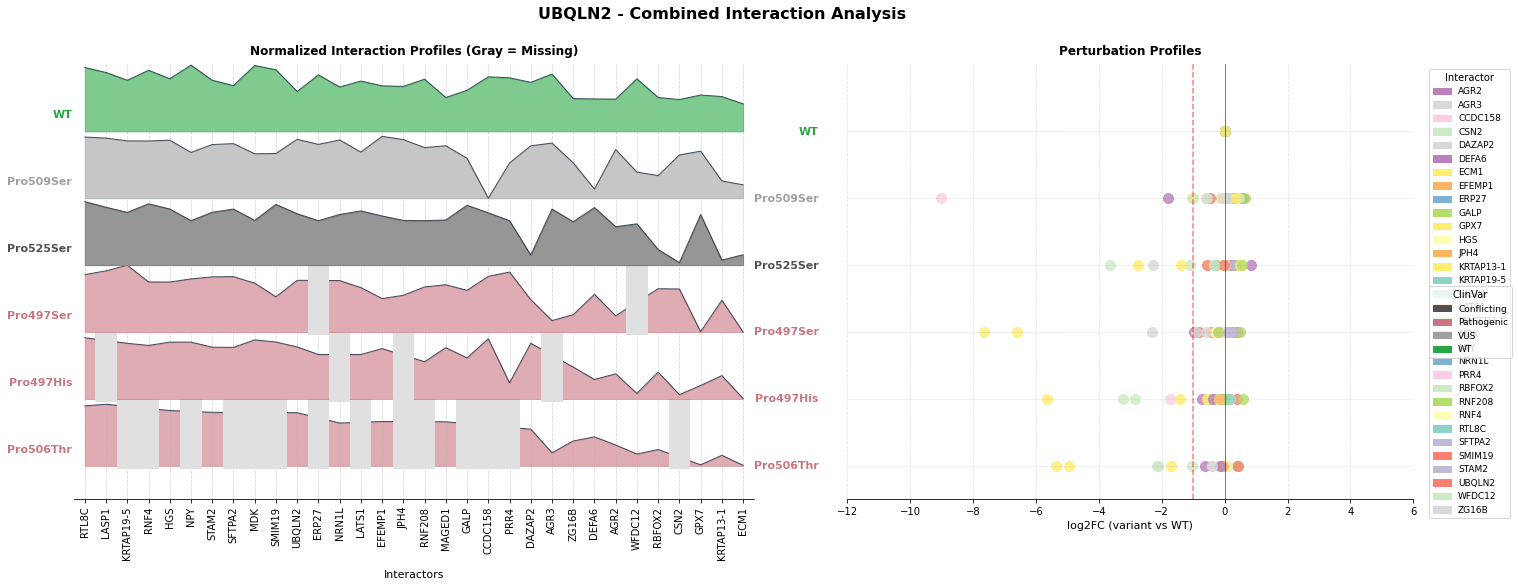


Processing: VHL
Plotting VHL: 17 variants, 1 interactors


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


Saved: ../3_outputs/sqY2H/combined_plots/VHL_combined.pdf


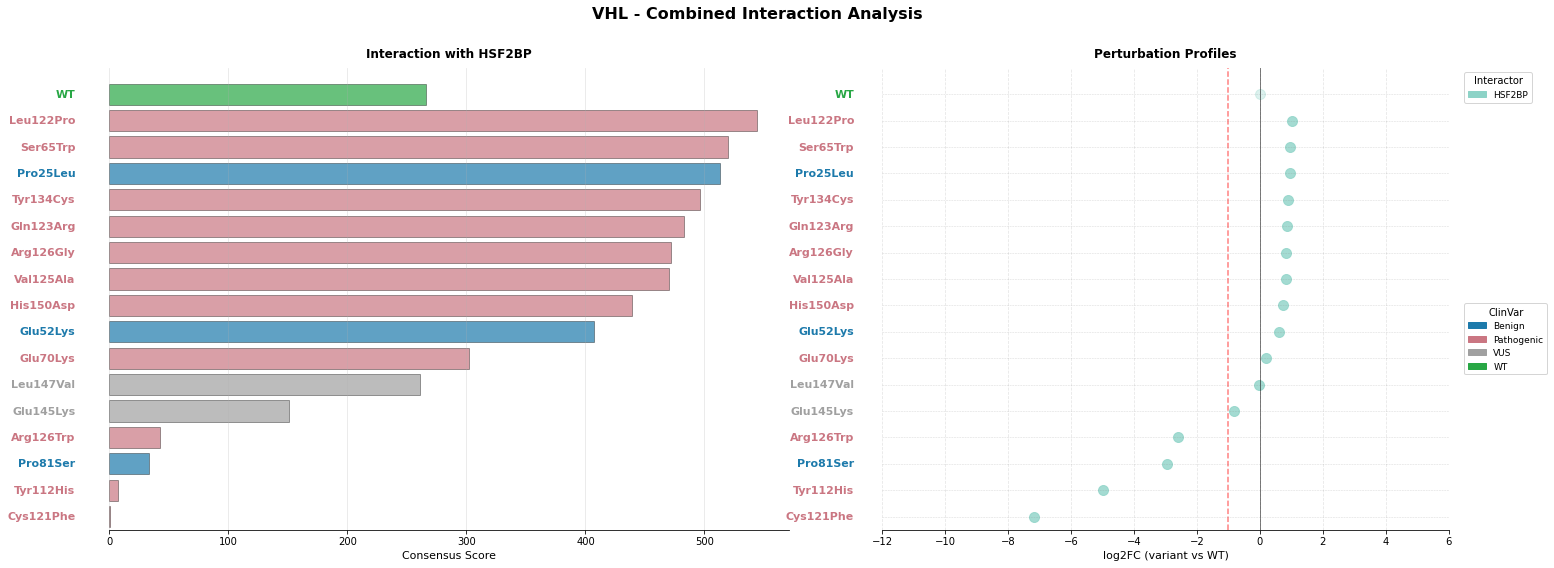


Processing: ZMYND10
Plotting ZMYND10: 3 variants, 2 interactors
Saved: ../3_outputs/sqY2H/combined_plots/ZMYND10_combined.pdf


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_26633/2962393410.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.96])


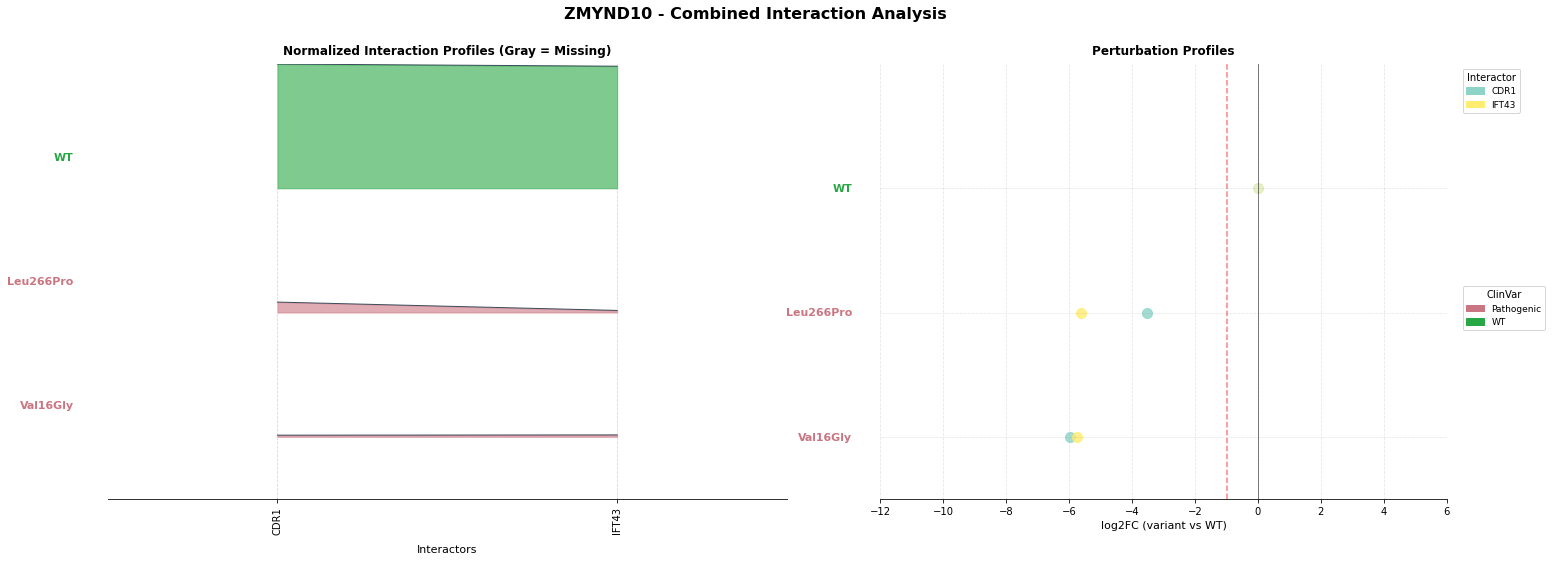


Completed: 73 combined plots generated as PDF


In [266]:
# ==========================================
# Usage
# ==========================================

# Generate all combined plots
all_combined_plots = plot_all_genes_combined(
    edge_df=edge_df,
    palette_dict=palette_dict,
    output_dir=f"{outputs_dir}/combined_plots",
    file_format='pdf'
)

In [219]:
edge_df[edge_df.symbol == 'AGXT'][['aa_change', 'consensus_score', 'wt_consensus_score', 'log2fc']]

,aa_change,consensus_score,wt_consensus_score,log2fc
476,NaN,357.210909,357.210909,0.000000
477,Pro11His,4.179909,357.210909,-6.111739
478,Lys12Arg,8.901949,357.210909,-5.176953
479,Pro10Ala,18.210367,357.210909,-4.220852
480,Phe152Ile,2.942261,357.210909,-6.505642
481,Arg197Gln,284.367454,357.210909,-0.327988
482,Ile340Met,35.321513,357.210909,-3.301913
483,Met49Leu,44.497370,357.210909,-2.976954
484,Arg111Gln,3.458802,357.210909,-6.328009
485,Ala280Val,7.315544,357.210909,-5.428855


# Consensus all media

In [220]:
consensus_all_media_df.columns

Index(['scoring_pla', 'scoring_pos', 'large_plate_name', 'retest_batch',
       'condition', 'condition_name', 'assay_id', 'media_control', 'ad_orf_id',
       'ad_mut_id',
       ...
       'splicing_variant', 'db_group', 'db_condition_group', 'ppi_group',
       'edge_group', 'seq_ad', 'seq_db', 'db_seq_final_right', 'aa_score',
       'consensus_manual_score_growth'],
      dtype='object', length=1046)

In [267]:
gene_filter = 'TTR'

consensus_all_media_df[
    (consensus_all_media_df.symbol == gene_filter) &
    # (consensus_all_media_df.ad_symbol == 'ARRDC3') &
    (consensus_all_media_df.aa_change.isna())
    ][['aa_change', 'ad_symbol', 'condition_name', 'consensus_score']]

,aa_change,ad_symbol,condition_name,consensus_score
725,NaN,ATF5,LW,535.435127
1231,NaN,ATF5,LWA,0.000000
1726,NaN,ATF5,LWH1,551.408869
2230,NaN,ATF5,LWH10,293.065611
2736,NaN,ATF5,LWH25,230.153450
3226,NaN,ATF5,LWAH1,0.000000


In [269]:

edge_df[(edge_df['symbol'] == gene_filter) &
        (edge_df.db_mut_id == 0) 
        # (edge_df.ad_symbol == 'ARRDC3')
        ]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
1005,VUSAPWT1B2r05_008,M13,VUSAPWT1B2r05_007_008_009_010_011_012,VUSAPWT1B2,r11,LWH25,1,False,3490,NaN,...,8999.0_0.0_LWH25_VUSAPWT1B2,3490.0_8999.0_0.0_VUSAPWT1B2,3490.0_8999.0_VUSAPWT1B2,1,1,NaN,3.49411,0.0,230.15345,0.0
